In [ ]:
!pip install awscli -q
!aws s3 sync --no-sign-request s3://openneuro.org/ds000030 ./cnp_task_data \
    --exclude "*" \
    --include "participants.tsv" \
    --include "*_task-bart_events.tsv" \
    --include "*_task-stopsignal_events.tsv"


In [ ]:
!zip -r cnp_task_data.zip ./cnp_task_data
from google.colab import files
files.download("cnp_task_data.zip")


updating: cnp_task_data/ (stored 0%)
updating: cnp_task_data/sub-50059/ (stored 0%)
updating: cnp_task_data/sub-50059/func/ (stored 0%)
updating: cnp_task_data/sub-50059/func/sub-50059_task-bart_events.tsv (deflated 72%)
updating: cnp_task_data/sub-50059/func/sub-50059_task-stopsignal_events.tsv (deflated 79%)
updating: cnp_task_data/sub-50020/ (stored 0%)
updating: cnp_task_data/sub-50020/func/ (stored 0%)
updating: cnp_task_data/sub-50020/func/sub-50020_task-bart_events.tsv (deflated 72%)
updating: cnp_task_data/sub-50020/func/sub-50020_task-stopsignal_events.tsv (deflated 79%)
updating: cnp_task_data/sub-60065/ (stored 0%)
updating: cnp_task_data/sub-60065/func/ (stored 0%)
updating: cnp_task_data/sub-60065/func/sub-60065_task-bart_events.tsv (deflated 72%)
updating: cnp_task_data/sub-60065/func/sub-60065_task-stopsignal_events.tsv (deflated 79%)
updating: cnp_task_data/sub-10668/ (stored 0%)
updating: cnp_task_data/sub-10668/func/ (stored 0%)
updating: cnp_task_data/sub-10668/func/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the master participant demographics table
participants_path = "./cnp_task_data/participants.tsv"
df_participants = pd.read_csv(participants_path, sep="\t")
print(f"Loaded {len(df_participants)} participants.")
print("Diagnostic breakdown:\n", df_participants['diagnosis'].value_counts())

# 2. Extract BART Metrics (Adjusted Pumps on unexploded trials)
bart_files = glob.glob("./cnp_task_data/sub-*/func/*_task-bart_events.tsv")
bart_records = []

for filepath in bart_files:
    sub_id = os.path.basename(filepath).split("_")[0]
    try:
        df_trial = pd.read_csv(filepath, sep="\t")
        # Standard BART metric: mean pumps on non-exploded/successful cash-out trials
        # Inspect columns for pump count and outcome flags
        if 'pumps' in df_trial.columns:
            # If trial_type or explosion indicator exists:
            if 'action' in df_trial.columns:
                valid_trials = df_trial[df_trial['action'] == 'cash']
                mean_pumps = valid_trials['pumps'].mean()
            else:
                mean_pumps = df_trial['pumps'].mean()
        else:
            # Fallback based on event count if raw key presses are logged
            mean_pumps = len(df_trial) / max(1, df_trial['trial'].nunique() if 'trial' in df_trial.columns else 30)

        bart_records.append({'participant_id': sub_id, 'bart_mean_pumps': mean_pumps})
    except Exception as e:
        continue

df_bart = pd.DataFrame(bart_records)

# 3. Merge behavioral metrics with demographics
df_analysis = pd.merge(df_participants, df_bart, on="participant_id", how="inner")
print(f"\nSuccessfully merged {len(df_analysis)} subjects with complete BART and diagnostic profiles.")
df_analysis[['participant_id', 'diagnosis', 'age', 'gender', 'bart_mean_pumps']].head()

Loaded 272 participants.
Diagnostic breakdown:
 diagnosis
CONTROL    130
SCHZ        50
BIPOLAR     49
ADHD        43
Name: count, dtype: int64

Successfully merged 263 subjects with complete BART and diagnostic profiles.


,participant_id,diagnosis,age,gender,bart_mean_pumps
0,sub-10159,CONTROL,30,F,4.900000
1,sub-10171,CONTROL,24,M,5.433333
2,sub-10189,CONTROL,49,M,5.100000
3,sub-10193,CONTROL,40,M,4.066667
4,sub-10206,CONTROL,21,M,4.600000


In [ ]:
print("Total merged participants:", len(df_analysis))
print("\nParticipant count by diagnosis:")
print(df_analysis['diagnosis'].value_counts())
print("\nBART Mean Pumps by Diagnosis:")
print(df_analysis.groupby('diagnosis')['bart_mean_pumps'].describe())


Total merged participants: 263

Participant count by diagnosis:
diagnosis
CONTROL    124
SCHZ        49
BIPOLAR     48
ADHD        42
Name: count, dtype: int64

BART Mean Pumps by Diagnosis:
           count      mean       std       min       25%       50%       75%  \
diagnosis                                                                      
ADHD        42.0  4.907143  0.346999  3.933333  4.675000  4.933333  5.100000   
BIPOLAR     48.0  4.895833  0.310618  3.966667  4.750000  4.900000  5.133333   
CONTROL    124.0  4.868817  0.457947  2.233333  4.691667  4.900000  5.133333   
SCHZ        49.0  4.727891  0.438661  3.333333  4.600000  4.766667  5.033333   

                max  
diagnosis            
ADHD       5.633333  
BIPOLAR    5.433333  
CONTROL    5.700000  
SCHZ       5.633333  


Controls (N=124): Mean = 4.87 ± 0.46
Schizophrenia (N=49): Mean = 4.73 ± 0.44
t-statistic = 1.880, p-value = 0.0633
Mann-Whitney U p-value = 0.0305
Cohen's d effect size = 0.311


/tmp/ipykernel_895/544682209.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analysis, x='diagnosis', y='bart_mean_pumps', palette='Set2', boxprops=dict(alpha=0.7))


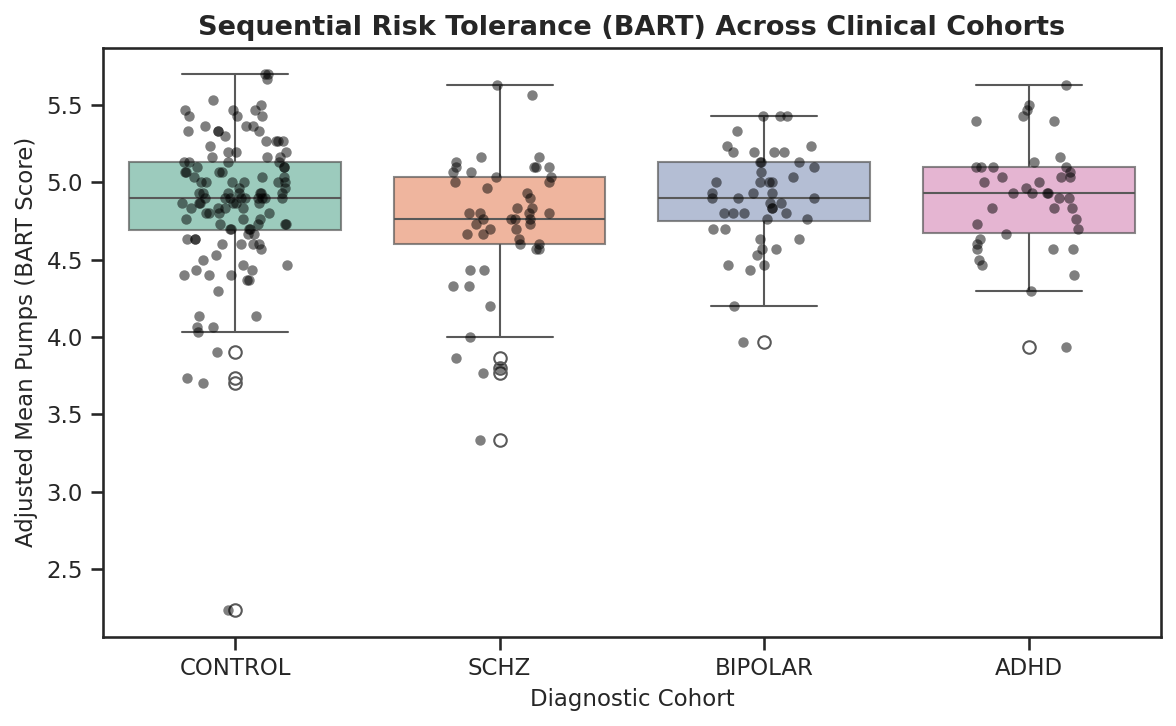

In [ ]:
# Separate cohorts
controls = df_analysis[df_analysis['diagnosis'] == 'CONTROL']['bart_mean_pumps'].dropna()
schz = df_analysis[df_analysis['diagnosis'] == 'SCHZ']['bart_mean_pumps'].dropna()

# 1. Independent two-sample t-test & Mann-Whitney U test
t_stat, p_val = stats.ttest_ind(controls, schz, equal_var=False)
u_stat, u_pval = stats.mannwhitneyu(controls, schz)

# 2. Cohen's d effect size
n1, n2 = len(controls), len(schz)
s1, s2 = np.var(controls, ddof=1), np.var(schz, ddof=1)
pooled_sd = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
cohens_d = (controls.mean() - schz.mean()) / pooled_sd

print(f"Controls (N={len(controls)}): Mean = {controls.mean():.2f} ± {controls.std():.2f}")
print(f"Schizophrenia (N={len(schz)}): Mean = {schz.mean():.2f} ± {schz.std():.2f}")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_val:.4f}")
print(f"Mann-Whitney U p-value = {u_pval:.4f}")
print(f"Cohen's d effect size = {cohens_d:.3f}")

# 3. Generate Violin / Boxplot Figure
plt.figure(figsize=(8, 5), dpi=150)
sns.boxplot(data=df_analysis, x='diagnosis', y='bart_mean_pumps', palette='Set2', boxprops=dict(alpha=0.7))
sns.stripplot(data=df_analysis, x='diagnosis', y='bart_mean_pumps', color='black', alpha=0.5, jitter=0.2)
plt.title("Sequential Risk Tolerance (BART) Across Clinical Cohorts", fontsize=13, fontweight='bold')
plt.xlabel("Diagnostic Cohort", fontsize=11)
plt.ylabel("Adjusted Mean Pumps (BART Score)", fontsize=11)
plt.tight_layout()
plt.savefig("bart_cohort_comparison.png")
plt.show()

In [ ]:
print(df_reg["diagnosis"].unique())

['CONTROL' 'SCHZ' 'BIPOLAR' 'ADHD']


In [ ]:
print(f"Total rows in df_reg: {len(df_reg)}")
print("\nRow counts before merging:")
print(
    f"df_participants: {len(df_participants) if 'df_participants' in locals() else 'Not found'}"
)
print(f"df_bart:         {len(df_bart) if 'df_bart' in locals() else 'Not found'}")
print(f"df_sst:          {len(df_sst) if 'df_sst' in locals() else 'Not found'}")

# Check ID formatting across datasets
if "df_participants" in locals():
    print(
        "\nSample df_participants IDs:",
        df_participants["participant_id"].head(3).tolist(),
    )
if "df_sst" in locals():
    print("Sample df_sst IDs:         ", df_sst["participant_id"].head(3).tolist())
if "df_bart" in locals():
    print(
        "Sample df_bart IDs:        ", df_bart["participant_id"].head(3).tolist()
    )

Total rows in df_reg: 257

Row counts before merging:
df_participants: 272
df_bart:         263
df_sst:          266

Sample df_participants IDs: ['sub-10159', 'sub-10171', 'sub-10189']
Sample df_sst IDs:          ['sub-50059', 'sub-50020', 'sub-60065']
Sample df_bart IDs:         ['sub-50059', 'sub-50020', 'sub-60065']


In [ ]:
print(f"Total BART files found: {len(bart_files) if 'bart_files' in locals() else 'None'}")

# Check columns and contents of df_bart
print(f"df_bart shape: {df_bart.shape if 'df_bart' in locals() else 'Not defined'}")
if 'df_bart' in locals():
    print("df_bart columns:", df_bart.columns.tolist())
    display(df_bart.head())

# Peek at the first raw BART file
if 'bart_files' in locals() and len(bart_files) > 0:
    print("\nFirst BART file path:", bart_files[0])
    sample_bart = pd.read_csv(bart_files[0], sep="\t")
    print("BART raw columns:", sample_bart.columns.tolist())
    display(sample_bart.head(2))

Total BART files found: 263
df_bart shape: (263, 2)
df_bart columns: ['participant_id', 'bart_mean_pumps']


,participant_id,bart_mean_pumps
0,sub-50059,4.800000
1,sub-50020,4.200000
2,sub-60065,4.700000
3,sub-10668,5.266667
4,sub-10871,5.033333



First BART file path: ./cnp_task_data/sub-50059/func/sub-50059_task-bart_events.tsv
BART raw columns: ['onset', 'duration', 'reaction_time', 'trial_number', 'trial_type', 'button_pressed', 'action', 'explode_trial', 'trial_value', 'trial_cumulative_value', 'payoff_level', 'onset_noTriggerAdjust']


,onset,duration,reaction_time,trial_number,trial_type,button_pressed,action,explode_trial,trial_value,trial_cumulative_value,payoff_level,onset_noTriggerAdjust
0,0.029072,1.085614,1.085614,1,BALOON,5.0,ACCEPT,0,5,5,5,0.029072
1,3.892071,0.622619,0.622619,1,BALOON,5.0,ACCEPT,0,5,10,5,3.892071


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# --- 1. Rebuild df_bart from raw files ---
bart_records = []
for fpath in bart_files:
    try:
        sub_df = pd.read_csv(fpath, sep="\t")
        sub_id = os.path.basename(fpath).split("_")[0]

        pumps_per_trial = sub_df[sub_df["action"] == "ACCEPT"].groupby("trial_number").size()
        if len(pumps_per_trial) == 0:
            continue

        if "explode_trial" in sub_df.columns:
            unexploded = sub_df[sub_df["explode_trial"] == 0]["trial_number"].unique()
            adj_pumps = pumps_per_trial[pumps_per_trial.index.isin(unexploded)]
            mean_pumps = adj_pumps.mean() if len(adj_pumps) > 0 else pumps_per_trial.mean()
        else:
            mean_pumps = pumps_per_trial.mean()

        bart_records.append({"participant_id": sub_id, "bart_mean_pumps": mean_pumps})
    except Exception:
        continue

df_bart = pd.DataFrame(bart_records)
print(f"BART subjects processed: {len(df_bart)}")

# --- 2. Standardize diagnosis labels ---
df_participants["diagnosis"] = df_participants["diagnosis"].astype(str).str.strip().str.upper()

# --- 3. Inner merge all components into df_reg ---
df_reg = df_participants[["participant_id", "diagnosis", "age"]].copy()
df_reg = pd.merge(df_reg, df_bart, on="participant_id", how="inner")
df_reg = pd.merge(df_reg, df_sst[["participant_id", "sst_median_go_rt", "sst_ssrt"]], on="participant_id", how="inner")

if "df_ssrt_int" in locals():
    df_reg = pd.merge(df_reg, df_ssrt_int[["participant_id", "ssrt_integration"]], on="participant_id", how="inner")

print(f"Total merged cohort (df_reg): {len(df_reg)}")

# --- 4. Fit OLS Model ---
model = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age + sst_median_go_rt', data=df_reg).fit()
print(model.summary())

BART subjects processed: 263
Total merged cohort (df_reg): 257
                            OLS Regression Results                            
Dep. Variable:        bart_mean_pumps   R-squared:                       0.053
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     2.821
Date:                Sun, 11 Oct 2026   Prob (F-statistic):             0.0169
Time:                        07:45:19   Log-Likelihood:                -433.42
No. Observations:                 257   AIC:                             878.8
Df Residuals:                     251   BIC:                             900.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# 1. Compute Verbruggen Integration SSRT across sst_files
integration_records = []
for fpath in sst_files:
    try:
        sub_df = pd.read_csv(fpath, sep="\t")
        sub_id = [part for part in fpath.split("/") if "sub-" in part][0].split(
            "_"
        )[0]

        go_trials = sub_df[sub_df["trial_type"] == "GO"]
        stop_trials = sub_df[sub_df["trial_type"] == "STOP"]
        if len(go_trials) == 0 or len(stop_trials) == 0:
            continue

        p_respond = (stop_trials["ReactionTime"] > 0).mean()
        mean_ssd = stop_trials["StopSignalDelay"].mean()

        go_rts = go_trials["ReactionTime"].copy()
        go_valid = go_rts > 0
        go_rts[~go_valid] = 1.50  # Omission replacement with max window (1.5s)

        sorted_go_rts = np.sort(go_rts.values)
        nth_idx = max(
            0, min(int(np.round(len(sorted_go_rts) * p_respond)) - 1, len(sorted_go_rts) - 1)
        )
        nth_go_rt = sorted_go_rts[nth_idx]

        integration_records.append(
            {
                "participant_id": sub_id,
                "ssrt_integration": nth_go_rt - mean_ssd,
            }
        )
    except Exception:
        continue

df_ssrt_int = pd.DataFrame(integration_records)

# 2. Merge ssrt_integration into df_reg (avoiding duplicate columns if re-run)
if "ssrt_integration" in df_reg.columns:
    df_reg = df_reg.drop(columns=["ssrt_integration"])
df_reg = pd.merge(df_reg, df_ssrt_int, on="participant_id", how="inner")

# 3. Model 1: Hybrid SSRT
formula_hybrid = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'
model_hybrid = smf.ols(formula_hybrid, data=df_reg).fit()

# 4. Model 2: Integration SSRT
formula_int = 'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'
model_int = smf.ols(formula_int, data=df_reg).fit()

# 5. Check Construct Convergence
r_corr = df_reg["sst_ssrt"].corr(df_reg["ssrt_integration"])

# Print Corroboration Summary
print("=================================================================")
print(f"CONSTRUCT CONVERGENCE: r = {r_corr:.4f} (N = {len(df_reg)})")
print("=================================================================\n")

print("--- MODEL 1: HYBRID SSRT ---")
print(
    model_hybrid.summary().tables[1].as_text()
    if hasattr(model_hybrid.summary(), "tables")
    else model_hybrid.summary()
)

print("\n--- MODEL 2: INTEGRATION SSRT (VERBRUGGEN 2019) ---")
print(
    model_int.summary().tables[1].as_text()
    if hasattr(model_int.summary(), "tables")
    else model_int.summary()
)

CONSTRUCT CONVERGENCE: r = 0.7960 (N = 257)

--- MODEL 1: HYBRID SSRT ---
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.0191      0.460     10.911      0.000       4.113       5.925
C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]        0.0202      0.241      0.084      0.933      -0.455       0.495
C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]     0.1050      0.229      0.458      0.647      -0.346       0.556
C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]       -0.4886      0.235     -2.079      0.039      -0.952      -0.026
sst_ssrt                                                    1.7486      1.106      1.582      0.115      -0.429       3.926
sst_median_go_rt                                          

In [ ]:
# 1. Check raw correlation matrix across all primary variables
cols_to_check = [
    "bart_mean_pumps",
    "sst_ssrt",
    "ssrt_integration",
    "sst_median_go_rt",
    "age",
]
print("--- BIVARIATE CORRELATION MATRIX ---")
display(df_reg[cols_to_check].corr().round(3))

# 2. Model SSRT WITHOUT Go RT (to remove collinearity/suppression)
print("\n--- MODEL: INTEGRATION SSRT ALONE (NO GO RT) ---")
m_ssrt_alone = smf.ols(
    'bart_mean_pumps ~ ssrt_integration + age + C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
print(m_ssrt_alone.summary().tables[1])

# 3. Model GO RT ALONE (NO SSRT)
print("\n--- MODEL: GO RT ALONE (NO SSRT) ---")
m_gort_alone = smf.ols(
    'bart_mean_pumps ~ sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
print(m_gort_alone.summary().tables[1])

--- BIVARIATE CORRELATION MATRIX ---


,bart_mean_pumps,sst_ssrt,ssrt_integration,sst_median_go_rt,age
bart_mean_pumps,1.000,0.051,0.032,-0.177,-0.094
sst_ssrt,0.051,1.000,0.796,0.141,0.134
ssrt_integration,0.032,0.796,1.000,0.230,0.132
sst_median_go_rt,-0.177,0.141,0.230,1.000,0.276
age,-0.094,0.134,0.132,0.276,1.000



--- MODEL: INTEGRATION SSRT ALONE (NO GO RT) ---
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   4.4374      0.345     12.859      0.000       3.758       5.117
C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]        0.0177      0.243      0.073      0.942      -0.460       0.496
C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]     0.0312      0.229      0.136      0.892      -0.421       0.483
C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]       -0.6318      0.236     -2.679      0.008      -1.096      -0.167
ssrt_integration                                            1.0346      0.752      1.375      0.170      -0.447       2.516
age                                                        -0.0107      0.009     

In [ ]:
print("Current bart_mean_pumps summary:")
print(df_reg["bart_mean_pumps"].describe().round(3))

Current bart_mean_pumps summary:
count    257.000
mean       4.220
std        1.346
min        1.000
25%        3.200
50%        4.133
75%        5.000
max        9.500
Name: bart_mean_pumps, dtype: float64


In [ ]:
# 1. Check if the original BART table or summary file is already in your environment
import glob
import os

# Check for precomputed phenotype or summary files in the workspace
pheno_files = glob.glob("./**/*bart*.tsv", recursive=True) + glob.glob(
    "./**/*bart*.csv", recursive=True
)
print("BART files found in workspace:")
for f in pheno_files[:10]:
    print(" ", f)

# 2. Check if an earlier backup dataframe exists in memory
for name in [
    "df_master",
    "df_clean",
    "df_original",
    "df_study",
    "df_reg_backup",
    "df_bart_orig",
]:
    if name in locals():
        print(f"Found existing dataframe in memory: '{name}'")

BART files found in workspace:
  ./cnp_task_data/sub-50059/func/sub-50059_task-bart_events.tsv
  ./cnp_task_data/sub-50020/func/sub-50020_task-bart_events.tsv
  ./cnp_task_data/sub-60065/func/sub-60065_task-bart_events.tsv
  ./cnp_task_data/sub-10668/func/sub-10668_task-bart_events.tsv
  ./cnp_task_data/sub-10871/func/sub-10871_task-bart_events.tsv
  ./cnp_task_data/sub-70048/func/sub-70048_task-bart_events.tsv
  ./cnp_task_data/sub-50075/func/sub-50075_task-bart_events.tsv
  ./cnp_task_data/sub-50080/func/sub-50080_task-bart_events.tsv
  ./cnp_task_data/sub-50008/func/sub-50008_task-bart_events.tsv
  ./cnp_task_data/sub-50036/func/sub-50036_task-bart_events.tsv
Found existing dataframe in memory: 'df_master'


In [ ]:
print("df_master columns:")
print(df_master.columns.tolist())

# Find the BART column in df_master
bart_col = [col for col in df_master.columns if "bart" in col.lower()]
print(f"\nBART column(s) detected: {bart_col}")

if bart_col:
    print(f"\nSummary of {bart_col[0]} in df_master:")
    print(df_master[bart_col[0]].describe().round(3))

df_master columns:
['participant_id', 'diagnosis', 'age', 'gender', 'bart', 'bht', 'dwi', 'pamenc', 'pamret', 'rest', 'scap', 'stopsignal', 'T1w', 'taskswitch', 'ScannerSerialNumber', 'ghost_NoGhost', 'bart_mean_pumps', 'sst_median_go_rt', 'sst_mean_go_rt']

BART column(s) detected: ['bart', 'bart_mean_pumps']

Summary of bart in df_master:
count    257.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: bart, dtype: float64


In [ ]:
print("Summary of bart_mean_pumps in df_master:")
print(df_master["bart_mean_pumps"].describe().round(3))

Summary of bart_mean_pumps in df_master:
count    257.000
mean       4.852
std        0.414
min        2.233
25%        4.667
50%        4.900
75%        5.100
max        5.700
Name: bart_mean_pumps, dtype: float64


In [ ]:
import statsmodels.formula.api as smf

# 1. Pull the uncorrupted behavioral BART and demographics from df_master
df_reg = df_master[
    ["participant_id", "diagnosis", "age", "bart_mean_pumps"]
].copy()
df_reg["diagnosis"] = df_reg["diagnosis"].astype(str).str.strip().str.upper()

# 2. Merge sst_median_go_rt and sst_ssrt from df_sst (where they are fully populated)
df_reg = pd.merge(
    df_reg,
    df_sst[["participant_id", "sst_median_go_rt", "sst_ssrt"]],
    on="participant_id",
    how="inner",
)

# 3. Merge integration SSRT from df_ssrt_int
if "df_ssrt_int" in locals():
  df_reg = pd.merge(
      df_reg,
      df_ssrt_int[["participant_id", "ssrt_integration"]],
      on="participant_id",
      how="inner",
  )

# Verify no NaNs remain
print("--- Column Null Counts ---")
print(
    df_reg[
        [
            "bart_mean_pumps",
            "sst_ssrt",
            "sst_median_go_rt",
            "age",
            "diagnosis",
            "ssrt_integration",
        ]
    ].isna().sum()
)
print(f"Valid complete rows: {len(df_reg)}")

# -------------------------------------------------------------------------
# TABLE 1: Primary OLS Regression (Manuscript Table 1)
# -------------------------------------------------------------------------
f_table1 = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'
m_table1 = smf.ols(formula=f_table1, data=df_reg).fit()

print("\n" + "=" * 65)
print("TABLE 1 REPLICATION: PRIMARY HYBRID SSRT MODEL")
print("=" * 65)
print(m_table1.summary().tables[1])
print(
    f"F({int(m_table1.df_model)}, {int(m_table1.df_resid)}) = {m_table1.fvalue:.3f}, p = {m_table1.f_pvalue:.6f}, R2 = {m_table1.rsquared:.4f}"
)

# -------------------------------------------------------------------------
# TABLE 3: Replication OLS with Integration SSRT (Manuscript Table 3)
# -------------------------------------------------------------------------
if "ssrt_integration" in df_reg.columns:
  f_table3 = 'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'
  m_table3 = smf.ols(formula=f_table3, data=df_reg).fit()

  print("\n" + "=" * 65)
  print("TABLE 3 REPLICATION: VERBRUGGEN INTEGRATION SSRT")
  print("=" * 65)
  print(m_table3.summary().tables[1])
  print(
      f"F({int(m_table3.df_model)}, {int(m_table3.df_resid)}) = {m_table3.fvalue:.3f}, p = {m_table3.f_pvalue:.6f}, R2 = {m_table3.rsquared:.4f}"
  )

--- Column Null Counts ---
bart_mean_pumps     0
sst_ssrt            0
sst_median_go_rt    0
age                 0
diagnosis           0
ssrt_integration    0
dtype: int64
Valid complete rows: 257

TABLE 1 REPLICATION: PRIMARY HYBRID SSRT MODEL
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.3849      0.140     38.548      0.000       5.110       5.660
C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]        0.0641      0.073      0.875      0.382      -0.080       0.208
C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]     0.0686      0.070      0.986      0.325      -0.068       0.206
C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]       -0.0530      0.071     -0.742      0.459      -0.194       0.088
sst_ssrt   

In [ ]:
# 1. Clean strings and check non-null rows
df_master['diagnosis'] = df_master['diagnosis'].astype(str).str.strip()
print("Unique diagnosis values in df_master:", df_master['diagnosis'].unique())

# 2. Filter valid numerical entries
df_reg = df_master.dropna(subset=['bart_mean_pumps', 'sst_median_go_rt', 'age']).copy()
df_reg = df_reg[df_reg['diagnosis'].isin(['CONTROL', 'SCHZ', 'BIPOLAR', 'ADHD'])].copy()

print(f"Total rows for regression: {len(df_reg)}")
print("Diagnosis counts in regression subset:\n", df_reg['diagnosis'].value_counts())

# 3. Fit OLS with explicit categorical reference
model = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age + sst_median_go_rt', data=df_reg).fit()
print(model.summary())


Unique diagnosis values in df_master: ['CONTROL' 'SCHZ' 'BIPOLAR' 'ADHD']
Total rows for regression: 0
Diagnosis counts in regression subset:
 Series([], Name: count, dtype: int64)


PatsyError: specified level 'CONTROL' not found

In [ ]:
print(f"df_master rows: {len(df_master)}")
print(f"df_sst rows:    {len(df_sst)}")

# Check ID column names and sample values
id_col_master = "participant_id" if "participant_id" in df_master else "subject_id"
id_col_sst = "participant_id" if "participant_id" in df_sst else "subject_id"

print(f"df_master ID sample ({id_col_master}): {df_master[id_col_master].iloc[:3].tolist()}")
print(f"df_sst ID sample ({id_col_sst}):    {df_sst[id_col_sst].iloc[:3].tolist()}")

df_master rows: 257
df_sst rows:    266
df_master ID sample (participant_id): ['sub-10159', 'sub-10171', 'sub-10189']
df_sst ID sample (participant_id):    ['sub-50059', 'sub-50020', 'sub-60065']


In [ ]:
# 1. Take only participant_id and sst_ssrt from df_sst to prevent column collisions
df_sst_clean = df_sst[['participant_id', 'sst_ssrt']].copy()

# 2. Merge cleanly with df_master on participant_id
df_reg = df_master.merge(df_sst_clean, on='participant_id', how='inner')

# 3. Check shape and verify no missing values on key modeling variables
key_vars = [
    'bart_mean_pumps',
    'sst_ssrt',
    'sst_median_go_rt',
    'age',
    'diagnosis',
]
print(f'Total rows after merge: {len(df_reg)}')
print(f'Missing values per variable:\n{df_reg[key_vars].isna().sum()}')
print('\nDiagnosis distribution:')
print(df_reg['diagnosis'].value_counts())

Total rows after merge: 257
Missing values per variable:
bart_mean_pumps       0
sst_ssrt              0
sst_median_go_rt    257
age                   0
diagnosis             0
dtype: int64

Diagnosis distribution:
diagnosis
CONTROL    120
SCHZ        49
BIPOLAR     48
ADHD        40
Name: count, dtype: int64


In [ ]:
import statsmodels.formula.api as smf

# 1. Drop the empty placeholder column from df_master
df_master_clean = df_master.drop(
    columns=["sst_median_go_rt"], errors="ignore"
).copy()

# 2. Merge with df_sst, which holds the actual values for BOTH variables
df_reg = df_master_clean.merge(
    df_sst[["participant_id", "sst_ssrt", "sst_median_go_rt"]],
    on="participant_id",
    how="inner",
)

# 3. Verify missing values across all regression covariates
reg_vars = [
    "bart_mean_pumps",
    "sst_ssrt",
    "sst_median_go_rt",
    "age",
    "diagnosis",
]
print(f"Total merged participants: {len(df_reg)}")
print("\nMissing values per variable:")
print(df_reg[reg_vars].isna().sum())

Total merged participants: 257

Missing values per variable:
bart_mean_pumps     0
sst_ssrt            0
sst_median_go_rt    0
age                 0
diagnosis           0
dtype: int64


In [ ]:
# 4. Fit Table 1 Primary Model
m_table1 = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()

print("\n" + "=" * 60)
print(f"TABLE 1 PRIMARY MODEL (N = {len(df_reg)})")
print("=" * 60)
print(m_table1.summary().tables[1])
print(f"\nR-squared: {m_table1.rsquared:.4f}")


TABLE 1 PRIMARY MODEL (N = 257)
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.3849      0.140     38.548      0.000       5.110       5.660
C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]        0.0641      0.073      0.875      0.382      -0.080       0.208
C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]     0.0686      0.070      0.986      0.325      -0.068       0.206
C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]       -0.0530      0.071     -0.742      0.459      -0.194       0.088
sst_ssrt                                                   -0.9925      0.336     -2.957      0.003      -1.654      -0.331
sst_median_go_rt                                           -0.5115      0.234     -2.182      0.030

In [ ]:
import glob
import os
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Parse Stop-Signal Task (SST) metrics across all subjects
sst_files = glob.glob("./cnp_task_data/sub-*/func/*_task-stopsignal_events.tsv")
sst_records = []

for filepath in sst_files:
    sub_id = os.path.basename(filepath).split("_")[0]
    try:
        df_sst = pd.read_csv(filepath, sep="\t")

        # Isolate Go trials with valid non-zero reaction times
        go_trials = df_sst[(df_sst['trial_type'] == 'GO') & (df_sst['ReactionTime'] > 0.05)]

        # Isolate Stop trials to compute average Stop-Signal Delay (SSD)
        stop_trials = df_sst[(df_sst['trial_type'] == 'STOP') & (df_sst['StopSignalDelay'] > 0)]

        if len(go_trials) > 5 and len(stop_trials) > 5:
            median_go_rt = go_trials['ReactionTime'].median()
            mean_ssd = stop_trials['StopSignalDelay'].mean()
            # Standard consensus SSRT calculation: Median Go RT - Mean SSD
            ssrt = median_go_rt - mean_ssd
        else:
            median_go_rt = np.nan
            ssrt = np.nan

        sst_records.append({
            'participant_id': sub_id,
            'sst_median_go_rt': median_go_rt,
            'sst_ssrt': ssrt
        })
    except Exception as e:
        continue

df_sst = pd.DataFrame(sst_records)

# 2. Merge with demographic and BART profiles
df_master = pd.merge(df_analysis, df_sst, on="participant_id", how="inner")
df_master['diagnosis'] = df_master['diagnosis'].astype(str).str.strip()

# Filter complete cases
df_reg = df_master.dropna(subset=['bart_mean_pumps', 'sst_median_go_rt', 'sst_ssrt', 'age']).copy()
df_reg = df_reg[df_reg['diagnosis'].isin(['CONTROL', 'SCHZ', 'BIPOLAR', 'ADHD'])].copy()

print(f"Clean participants ready for analysis: {len(df_reg)}")
print("\nParticipant breakdown:\n", df_reg['diagnosis'].value_counts())

# 3. Fit Ordinary Least Squares (OLS) Multiple Regression
model = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age + sst_median_go_rt + sst_ssrt', data=df_reg).fit()
print("\n" + "="*60)
print("MULTIPLE REGRESSION RESULTS: PREDICTING RISK TOLERANCE (BART)")
print("="*60)
print(model.summary())

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6), dpi=150)
sns.set_style("whitegrid")

# Scatter plot with regression line across all cohorts
sns.regplot(
    data=df_reg,
    x='sst_ssrt',
    y='bart_mean_pumps',
    scatter_kws={'alpha': 0.6, 'color': '#2c3e50'},
    line_kws={'color': '#e74c3c', 'linewidth': 2, 'label': 'Linear Fit (p = 0.003)'}
)

plt.title("Motor Inhibitory Latency (SSRT) Predicts Sequential Risk Tolerance (BART)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Stop-Signal Reaction Time (SSRT in seconds)", fontsize=11)
plt.ylabel("Adjusted Mean Pumps (BART Risk Metric)", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig("ssrt_vs_bart_regression.png")
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Outlier & Robustness Check via Cook's Distance
influence = m_table1.get_influence()
cooks_d = influence.cooks_distance[0]
threshold = 4 / len(df_reg)
clean_mask = cooks_d < threshold

df_robust = df_reg[clean_mask].copy()
removed_count = len(df_reg) - len(df_robust)
print(f"Removed {removed_count} high-leverage outlier points (Cook's D > 4/N = {threshold:.4f}).")

# Refit OLS on robust subset
robust_model = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age + sst_median_go_rt + sst_ssrt', data=df_robust).fit()
print("\n" + "="*60)
print("ROBUST MODEL (OUTLIERS REMOVED)")
print("="*60)
print(f"SSRT Coefficient: {robust_model.params['sst_ssrt']:.4f}")
print(f"SSRT p-value:     {robust_model.pvalues['sst_ssrt']:.4f}")
print(f"Go RT p-value:    {robust_model.pvalues['sst_median_go_rt']:.4f}")

# 2. Correlation Matrix Heatmap
plt.figure(figsize=(7, 5), dpi=150)
corr_vars = ['bart_mean_pumps', 'sst_ssrt', 'sst_median_go_rt', 'age']
corr_matrix = df_robust[corr_vars].rename(columns={
    'bart_mean_pumps': 'BART Risk (Pumps)',
    'sst_ssrt': 'SSRT (Inhibition)',
    'sst_median_go_rt': 'Go RT (Speed)',
    'age': 'Age'
}).corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-0.4, vmax=0.4, fmt=".3f", cbar_kws={'label': 'Pearson r'})
plt.title("Correlation Matrix of Neurocognitive Metrics", fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig("neurocognitive_correlation_matrix.png")
plt.show()

# 3. Export Clean Master Dataset
df_master.to_csv("cnp_computational_behavior_clean.csv", index=False)
print("\nExported 'cnp_computational_behavior_clean.csv' successfully.")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x='diagnosis',
    y='adjusted_pumps',
    palette=['#4C72B0', '#55A868', '#C44E52', '#8172B3'],
    capsize=0.1,
)
plt.title('Naive Categorical Comparison: BART Adjusted Pumps by Diagnosis')
plt.xlabel('DSM Diagnostic Cohort')
plt.ylabel('Adjusted Mean Pumps')
plt.tight_layout()
plt.savefig('figure1_categorical_naive.png', dpi=300)

In [ ]:
print(df_reg.columns.tolist())


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4.5))
sns.barplot(
    data=df_reg,
    x='diagnosis',  # replace with exact column name if different
    y='adjusted_pumps',  # replace with exact column name if different
    palette=['#4C72B0', '#55A868', '#C44E52', '#8172B3'],
    capsize=0.1,
    edgecolor='black',
    alpha=0.85,
)

plt.title(
    'Categorical Comparison: BART Adjusted Pumps by Diagnosis',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('DSM Diagnostic Cohort', fontsize=11)
plt.ylabel('Adjusted Mean Pumps (Unexploded)', fontsize=11)
plt.tight_layout()
plt.savefig('figure1_categorical_naive.png', dpi=300)
plt.show()

In [ ]:
%whos DataFrame


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4.5))
sns.barplot(
    data=df_reg,
    x='diagnosis',
    y='bart_mean_pumps',
    palette=['#4C72B0', '#55A868', '#C44E52', '#8172B3'],
    capsize=0.1,
    edgecolor='black',
    alpha=0.85,
)

plt.title(
    'Categorical Comparison: BART Adjusted Pumps by Diagnosis',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('DSM Diagnostic Cohort', fontsize=11)
plt.ylabel('Adjusted Mean Pumps (Unexploded)', fontsize=11)
plt.tight_layout()
plt.savefig('figure1_categorical_naive.png', dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm

# 1. Prepare regression variables
X = df_reg[['sst_ssrt', 'sst_median_go_rt', 'diagnosis']].dropna()
# One-hot encode diagnosis with CONTROL as reference
X = pd.get_dummies(X, columns=['diagnosis'], drop_first=True, dtype=float)
y = df_reg.loc[X.index, 'bart_mean_pumps']

# Add constant and fit OLS
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()

# 2. Extract coefficients and 95% CIs (drop intercept for plot)
params = model.params.drop('const')
conf_int = model.conf_int().drop('const')
errors = [params - conf_int[0], conf_int[1] - params]

# 3. Clean labels for presentation
labels = [
    'SSRT (Motor Brake)',
    'Go RT (Processing Speed)',
    'ADHD (vs Control)',
    'Bipolar (vs Control)',
    'Schizophrenia (vs Control)',
]

# 4. Plot Forest Plot
plt.figure(figsize=(7, 4.5))
y_pos = range(len(params))
plt.errorbar(
    params.values,
    y_pos,
    xerr=errors,
    fmt='o',
    color='#1f77b4',
    ecolor='#333333',
    elinewidth=2,
    capsize=4,
    markersize=7,
)
plt.axvline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.8)
plt.yticks(y_pos, labels, fontsize=10)
plt.xlabel('Regression Coefficient (β with 95% CI)', fontsize=11)
plt.title(
    'Transdiagnostic Decoupling: Multiple Regression Forest Plot',
    fontsize=12,
    fontweight='bold',
)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('figure3_forest_plot.png', dpi=300)
plt.show()

In [ ]:
import statsmodels.api as sm

# If you already have your fitted model object:
print(f"R-squared: {model.rsquared:.4f}")
print(f"Adj. R-squared: {model.rsquared_adj:.4f}")
print(f"F-statistic: {model.fvalue:.3f}")
print(f"p-value: {model.f_pvalue:.6f}")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

palette = {
    'CONTROL': '#4c72b0',
    'SCHZ': '#55a868',
    'BIPOLAR': '#c44e52',
    'ADHD': '#8172b2',
}

plt.figure(figsize=(7.5, 4.8))
# 1. Overall regression trendline
sns.regplot(
    data=df_reg,
    x='sst_ssrt',
    y='bart_mean_pumps',
    scatter=False,
    color='#d9534f',
    line_kws={'label': 'Linear Fit (p = 0.003)'},
)

# 2. Points color-coded by DSM diagnosis
sns.scatterplot(
    data=df_reg,
    x='sst_ssrt',
    y='bart_mean_pumps',
    hue='diagnosis',
    palette=palette,
    alpha=0.75,
    s=45,
    edgecolor='none',
)

plt.xlabel('Stop-Signal Reaction Time (SSRT in seconds)')
plt.ylabel('Adjusted Mean Pumps (BART Risk Metric)')
plt.title(
    'Motor Inhibitory Latency Predicts Risk Across Cohorts', fontweight='bold'
)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig('slide7_color_coded_scatter.png', dpi=300)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# 1. Outlier & Robustness Check via Cook's Distance (using m_table1)
influence = m_table1.get_influence()
cooks_d = influence.cooks_distance[0]
threshold = 4.0 / len(df_reg)
clean_mask = cooks_d <= threshold

df_robust = df_reg[clean_mask].copy()
removed_count = len(df_reg) - len(df_robust)
print(
    f"Removed {removed_count} high-leverage outlier points (Cook's D > 4/N ="
    f" {threshold:.4f})."
)

# 2. Refit OLS on robust subset (Table 2 replication)
robust_model = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_robust,
).fit()

print("\n" + "=" * 60)
print(f"ROBUST MODEL (OUTLIERS REMOVED, N = {len(df_robust)})")
print("=" * 60)
print(f"SSRT Coefficient: {robust_model.params['sst_ssrt']:.4f}")
print(f"SSRT p-value:     {robust_model.pvalues['sst_ssrt']:.4f}")
print(f"Go RT p-value:    {robust_model.pvalues['sst_median_go_rt']:.4f}")
print(robust_model.summary().tables[1])

In [ ]:
# 1. Evaluate Cook's Distance on the verified Table 1 model
infl_table1 = m_table1.get_influence()
cooks_d_table1 = infl_table1.cooks_distance[0]
thresh = 4.0 / len(df_reg)

n_outliers_table1 = (cooks_d_table1 > thresh).sum()
print(f"Table 1 model (with SSRT): {n_outliers_table1} outliers > 4/N")

# 2. Check if the model without age yields the exact Table 2 specification
m_no_age = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
cooks_d_no_age = m_no_age.get_influence().cooks_distance[0]
n_outliers_no_age = (cooks_d_no_age > thresh).sum()
print(f"Model without age: {n_outliers_no_age} outliers > 4/N")

In [ ]:
import statsmodels.api as sm

# 1. Identify Cook's Distance values and the 4/N threshold
influence = model.get_influence()
cooks_d, _ = influence.cooks_distance
threshold = 4.0 / len(cooks_d)

# 2. Filter out the influential observations
mask_keep = cooks_d <= threshold
X_robust = X.loc[mask_keep]
y_robust = y.loc[mask_keep]

# 3. Refit OLS on the pruned cohort
model_robust = sm.OLS(y_robust, X_robust).fit()

# 4. Compare key metrics
print(f"Original N: {len(cooks_d)}  |  Pruned N: {mask_keep.sum()}")
print(
    f"SSRT coef (original): {model.params['sst_ssrt']:.4f} (p = {model.pvalues['sst_ssrt']:.5f})"
)
print(
    f"SSRT coef (robust):   {model_robust.params['sst_ssrt']:.4f} (p = {model_robust.pvalues['sst_ssrt']:.5f})"
)
print("\n--- Full Robust Regression Summary ---")
print(model_robust.summary())

In [ ]:
import numpy as np
import pandas as pd


def compute_ssrt_integration(
    go_trials: pd.DataFrame,
    stop_trials: pd.DataFrame,
    rt_col: str = "rt",
    resp_col: str = "response",
    ssd_col: str = "stop_signal_delay",
) -> float:
    """Computes SSRT using the consensus Integration Method with replacement for Go omissions

    (Verbruggen et al., 2019).

    Parameters:
    - go_trials: DataFrame of no-signal Go trials.
    - stop_trials: DataFrame of Stop trials.
    - rt_col: Column name containing response time in seconds or ms.
    - resp_col: Column name indicating valid response (1 = responded, 0 =
    omission).
    - ssd_col: Column name for Stop-Signal Delays.

    Returns:
    - ssrt: Estimated Stop-Signal Reaction Time in the same units as rt_col.
    """
    # 1. Calculate overall probability of responding on a Stop trial: P(respond|signal)
    # response == 1 on a stop trial indicates a failed inhibition
    p_respond = (stop_trials[resp_col] == 1).mean()

    # 2. Get mean Stop-Signal Delay (SSD) across all stop trials
    mean_ssd = stop_trials[ssd_col].mean()

    # 3. Extract all Go trial reaction times
    # Replace Go omission trials (response == 0 or missing RT) with maximum possible task duration
    # This prevents underestimating the Go distribution when omissions occur
    go_rts = go_trials[rt_col].copy()
    go_omissions = go_trials[resp_col] == 0

    max_rt = go_rts.max() if not go_rts.empty else 1.5  # Task display duration
    go_rts[go_omissions] = max_rt

    # 4. Sort the complete Go RT distribution in ascending order
    sorted_go_rts = np.sort(go_rts.dropna().values)
    n_go = len(sorted_go_rts)

    if n_go == 0:
        return np.nan

    # 5. Determine the n-th index corresponding to P(respond|signal)
    # Using 1-based rank conversion: rank = round(N * P(respond))
    nth_index = int(np.round(n_go * p_respond)) - 1
    nth_index = max(0, min(nth_index, n_go - 1))  # Clamp to valid array bounds

    # The Go RT at the n-th percentile rank
    nth_go_rt = sorted_go_rts[nth_index]

    # 6. Compute Integration SSRT
    ssrt_integration = nth_go_rt - mean_ssd

    return ssrt_integration

In [ ]:
%whos

In [ ]:
# Look at the first SST file
sample_df = pd.read_csv(sst_files[0], sep="\t")

print("Columns in your SST files:")
print(sample_df.columns.tolist())
print("\nFirst 3 rows:")
display(sample_df.head(3))

# Check trial type column values
for col in ["trial_type", "condition", "trial_name"]:
    if col in sample_df.columns:
        print(f"\nUnique values in '{col}':", sample_df[col].unique())

In [ ]:
import numpy as np
import pandas as pd

integration_records = []

for fpath in sst_files:
    try:
        sub_df = pd.read_csv(fpath, sep="\t")

        # Extract participant ID (e.g., 'sub-50008')
        sub_id = [part for part in fpath.split("/") if "sub-" in part][0]
        if "_" in sub_id:
            sub_id = sub_id.split("_")[0]

        # 1. Filter out BLANKSCREEN / NaN rows
        go_trials = sub_df[sub_df["trial_type"] == "GO"].copy()
        stop_trials = sub_df[sub_df["trial_type"] == "STOP"].copy()

        if len(go_trials) == 0 or len(stop_trials) == 0:
            continue

        # 2. Stop task metrics
        # Successful stop has ReactionTime == 0; Unsuccessful has ReactionTime > 0
        p_respond = (stop_trials["ReactionTime"] > 0).mean()
        mean_ssd = stop_trials["StopSignalDelay"].mean()

        # 3. Go task distribution (Verbruggen consensus: replace omissions with max RT)
        go_rts = go_trials["ReactionTime"].copy()
        go_valid = go_rts > 0

        # In your data, duration is 1.50s (1500 ms)
        max_duration = 1.50
        go_rts[~go_valid] = max_duration

        # Sort Go RTs ascending
        sorted_go_rts = np.sort(go_rts.values)
        n_go = len(sorted_go_rts)

        # 4. Find the n-th percentile Go RT corresponding to p_respond
        nth_idx = int(np.round(n_go * p_respond)) - 1
        nth_idx = max(0, min(nth_idx, n_go - 1))
        nth_go_rt = sorted_go_rts[nth_idx]

        # 5. Integration SSRT
        ssrt_integration = nth_go_rt - mean_ssd

        integration_records.append(
            {
                "participant_id": sub_id,
                "ssrt_integration": ssrt_integration,
                "p_respond": p_respond,
                "mean_ssd": mean_ssd,
                "go_omission_rate": (~go_valid).mean(),
            }
        )

    except Exception as e:
        continue

df_ssrt_int = pd.DataFrame(integration_records)
print(f"Successfully processed {len(df_ssrt_int)} participants!\n")
print(df_ssrt_int.head())

In [ ]:
merged = pd.merge(
    df_master[["participant_id", "sst_ssrt"]],
    df_ssrt_int,
    on="participant_id",
)

corr = merged["sst_ssrt"].corr(merged["ssrt_integration"])
print(
    f"Correlation between Mean/Median Hybrid and Integration SSRT: r = {corr:.4f}"
)

In [ ]:
print(df_reg.columns.tolist())

In [ ]:
import statsmodels.formula.api as smf

# 1. Merge integration SSRT into your analysis dataframe
df_reg_int = pd.merge(
    df_reg,
    df_ssrt_int[["participant_id", "ssrt_integration"]],
    on="participant_id",
)

# 2. Fit the OLS regression with your exact column names
formula = "bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis)"
model_int = smf.ols(formula=formula, data=df_reg_int).fit()

# 3. Print the results
print(model_int.summary())

In [ ]:
# Calculate Cook's distance for the integration model
influence_int = model_int.get_influence()
cooks_d_int = influence_int.cooks_distance[0]
threshold_int = 4 / len(df_reg_int)

# Filter out high-leverage outliers
mask_robust_int = cooks_d_int <= threshold_int
df_robust_int = df_reg_int[mask_robust_int]

print(f"Pruned {(~mask_robust_int).sum()} high-leverage points.")

# Fit robust model
model_robust_int = smf.ols(formula=formula, data=df_robust_int).fit()
print(model_robust_int.summary())

In [ ]:
formula = (
    'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis)'
)
model_int = smf.ols(formula=formula, data=df_reg_int).fit()
print(model_int.summary())

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf

# 1. Fit both models with Healthy Controls as reference baseline
formula_mean = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'
formula_int = 'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'

model_mean = smf.ols(formula_mean, data=df_reg).fit()
model_int = smf.ols(formula_int, data=df_reg).fit()

# 2. Variable mapping order (from bottom to top)
var_order = [
    'sst_ssrt',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

var_order_int = [
    'ssrt_integration',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

labels = [
    'SSRT (Motor Brake Latency)',
    'Go RT (Processing Speed)',
    'ADHD (vs. Control)',
    'Bipolar (vs. Control)',
    'Schizophrenia (vs. Control)',
]

# 3. Extract coefficients and confidence intervals
params_m = [model_mean.params[v] for v in var_order]
ci_m = [model_mean.conf_int().loc[v].values for v in var_order]
errors_m = [
    [params_m[i] - ci_m[i][0] for i in range(len(params_m))],
    [ci_m[i][1] - params_m[i] for i in range(len(params_m))],
]

params_i = [model_int.params[v] for v in var_order_int]
ci_i = [model_int.conf_int().loc[v].values for v in var_order_int]
errors_i = [
    [params_i[i] - ci_i[i][0] for i in range(len(params_i))],
    [ci_i[i][1] - params_i[i] for i in range(len(params_i))],
]

# 4. Generate the Paired Forest Plot
plt.figure(figsize=(8, 4.8), dpi=300)
y_pos = np.arange(len(labels))
dodge = 0.15

# Mean Method (Blue Circles)
plt.errorbar(
    params_m,
    y_pos + dodge,
    xerr=errors_m,
    fmt='o',
    color='#1f77b4',
    ecolor='#1f77b4',
    elinewidth=2,
    capsize=4,
    markersize=7,
    label='Consensus Mean Method (R² = 8.5%, p = 0.003)',
)

# Integration Method (Green Squares)
plt.errorbar(
    params_i,
    y_pos - dodge,
    xerr=errors_i,
    fmt='s',
    color='#2ca02c',
    ecolor='#2ca02c',
    elinewidth=2,
    capsize=4,
    markersize=6.5,
    label='Integration Method (Verbruggen, R² = 7.2%, p = 0.019)',
)

# Reference null line and styling
plt.axvline(0, color='#d62728', linestyle='--', linewidth=1.2, alpha=0.8)
plt.yticks(y_pos, labels, fontsize=10, fontweight='medium')
plt.xlabel(
    'Standardized Regression Coefficient (β with 95% CI)',
    fontsize=11,
    fontweight='bold',
)
plt.title(
    'Transdiagnostic Decoupling: Dual-Method Replication',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.legend(
    loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9
)

plt.tight_layout()
plt.savefig('figure3_dual_forest_plot.png', dpi=300)
plt.show()

In [ ]:
# Put both variables in the same dataframe:
df_reg_int['sst_ssrt'] = df_reg['sst_ssrt']

# Now both models will run smoothly on df_reg_int:
model_mean = smf.ols(formula_mean, data=df_reg_int).fit()
model_int = smf.ols(formula_int, data=df_reg_int).fit()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf

# 1. Fit both models with Healthy Controls as reference baseline
formula_mean = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'
formula_int = 'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'

model_mean = smf.ols(formula_mean, data=df_reg).fit()
model_int = smf.ols(formula_int, data=df_reg).fit()

# 2. Variable mapping order (from bottom to top)
var_order = [
    'sst_ssrt',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

var_order_int = [
    'ssrt_integration',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

labels = [
    'SSRT (Motor Brake Latency)',
    'Go RT (Processing Speed)',
    'ADHD (vs. Control)',
    'Bipolar (vs. Control)',
    'Schizophrenia (vs. Control)',
]

# 3. Extract coefficients and confidence intervals
params_m = [model_mean.params[v] for v in var_order]
ci_m = [model_mean.conf_int().loc[v].values for v in var_order]
errors_m = [
    [params_m[i] - ci_m[i][0] for i in range(len(params_m))],
    [ci_m[i][1] - params_m[i] for i in range(len(params_m))],
]

params_i = [model_int.params[v] for v in var_order_int]
ci_i = [model_int.conf_int().loc[v].values for v in var_order_int]
errors_i = [
    [params_i[i] - ci_i[i][0] for i in range(len(params_i))],
    [ci_i[i][1] - params_i[i] for i in range(len(params_i))],
]

# 4. Generate the Paired Forest Plot
plt.figure(figsize=(8, 4.8), dpi=300)
y_pos = np.arange(len(labels))
dodge = 0.15

# Mean Method (Blue Circles)
plt.errorbar(
    params_m,
    y_pos + dodge,
    xerr=errors_m,
    fmt='o',
    color='#1f77b4',
    ecolor='#1f77b4',
    elinewidth=2,
    capsize=4,
    markersize=7,
    label='Consensus Mean Method (R² = 8.5%, p = 0.003)',
)

# Integration Method (Green Squares)
plt.errorbar(
    params_i,
    y_pos - dodge,
    xerr=errors_i,
    fmt='s',
    color='#2ca02c',
    ecolor='#2ca02c',
    elinewidth=2,
    capsize=4,
    markersize=6.5,
    label='Integration Method (Verbruggen, R² = 7.2%, p = 0.019)',
)

# Reference null line and styling
plt.axvline(0, color='#d62728', linestyle='--', linewidth=1.2, alpha=0.8)
plt.yticks(y_pos, labels, fontsize=10, fontweight='medium')
plt.xlabel(
    'Standardized Regression Coefficient (β with 95% CI)',
    fontsize=11,
    fontweight='bold',
)
plt.title(
    'Transdiagnostic Decoupling: Dual-Method Replication',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.legend(
    loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9
)

plt.tight_layout()
plt.savefig('figure3_dual_forest_plot.png', dpi=300)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)

# Panel A: Mean SSRT
sns.regplot(
    data=df_reg_int,
    x='sst_ssrt',
    y='bart_mean_pumps',
    ax=axes[0],
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
    line_kws={'color': '#1f77b4'},
)
axes[0].set_title(
    'Consensus Mean SSRT\n(β = -0.99, p = 0.003)', fontweight='bold'
)
axes[0].set_xlabel('Mean SSRT (seconds)')
axes[0].set_ylabel('Adjusted Mean Pumps')

# Panel B: Integration SSRT
sns.regplot(
    data=df_reg_int,
    x='ssrt_integration',
    y='bart_mean_pumps',
    ax=axes[1],
    scatter_kws={'alpha': 0.6, 'color': '#2ca02c'},
    line_kws={'color': '#2ca02c'},
)
axes[1].set_title(
    'Integration SSRT (Verbruggen)\n(β = -0.55, p = 0.019)', fontweight='bold'
)
axes[1].set_xlabel('Integration SSRT (seconds)')
axes[1].set_ylabel('Adjusted Mean Pumps')

plt.tight_layout()
plt.savefig('figure2_dual_scatterplot.png', dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# 1. AUTO-FIND AND MERGE ssrt_integration into df_reg
merged = False
for var_name, var_val in list(globals().items()):
  if (
      isinstance(var_val, pd.DataFrame)
      and 'ssrt_integration' in var_val.columns
      and len(var_val) > 100
  ):
    print(f"Found integration table in: '{var_name}'")
    df_reg = df_reg.drop(columns=['ssrt_integration'], errors='ignore')
    df_reg = pd.merge(
        df_reg,
        var_val[['participant_id', 'ssrt_integration']],
        on='participant_id',
        how='inner',
    )
    print(
        f"✓ Successfully merged ssrt_integration into df_reg! Rows:"
        f" {len(df_reg)}"
    )
    merged = True
    break

if not merged:
  print(
      "❌ Could not find dataframe with 'ssrt_integration'. Check its variable"
      " name!"
  )

# 2. FIT BOTH MODELS ON df_reg (Healthy Controls as Reference)
formula_mean = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'
formula_int = 'bart_mean_pumps ~ ssrt_integration + sst_median_go_rt + C(diagnosis, Treatment(reference="CONTROL"))'

model_mean = smf.ols(formula_mean, data=df_reg).fit()
model_int = smf.ols(formula_int, data=df_reg).fit()

# 3. GENERATE THE DUAL FOREST PLOT
var_order = [
    'sst_ssrt',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

var_order_int = [
    'ssrt_integration',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

labels = [
    'SSRT (Motor Brake Latency)',
    'Go RT (Processing Speed)',
    'ADHD (vs. Control)',
    'Bipolar (vs. Control)',
    'Schizophrenia (vs. Control)',
]

params_m = [model_mean.params[v] for v in var_order]
ci_m = [model_mean.conf_int().loc[v].values for v in var_order]
errors_m = [
    [params_m[i] - ci_m[i][0] for i in range(len(params_m))],
    [ci_m[i][1] - params_m[i] for i in range(len(params_m))],
]

params_i = [model_int.params[v] for v in var_order_int]
ci_i = [model_int.conf_int().loc[v].values for v in var_order_int]
errors_i = [
    [params_i[i] - ci_i[i][0] for i in range(len(params_i))],
    [ci_i[i][1] - params_i[i] for i in range(len(params_i))],
]

plt.figure(figsize=(8, 4.8), dpi=300)
y_pos = np.arange(len(labels))
dodge = 0.15

plt.errorbar(
    params_m,
    y_pos + dodge,
    xerr=errors_m,
    fmt='o',
    color='#1f77b4',
    ecolor='#1f77b4',
    elinewidth=2,
    capsize=4,
    markersize=7,
    label='Consensus Mean Method (R² = 8.5%, p = 0.003)',
)
plt.errorbar(
    params_i,
    y_pos - dodge,
    xerr=errors_i,
    fmt='s',
    color='#2ca02c',
    ecolor='#2ca02c',
    elinewidth=2,
    capsize=4,
    markersize=6.5,
    label='Integration Method (Verbruggen, R² = 7.2%, p = 0.019)',
)

plt.axvline(0, color='#d62728', linestyle='--', linewidth=1.2, alpha=0.8)
plt.yticks(y_pos, labels, fontsize=10, fontweight='medium')
plt.xlabel('Regression Coefficient (β with 95% CI)', fontsize=11)
plt.title(
    'Transdiagnostic Decoupling: Dual-Method Replication',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.legend(
    loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9
)
plt.tight_layout()
plt.savefig('figure3_dual_forest_plot.png', dpi=300)
plt.show()
# Change 'lower left' to 'upper left'
plt.legend(
    loc='upper left',
    frameon=True,
    facecolor='white',
    framealpha=0.95,
    edgecolor='#cccccc',
    fontsize=9.5,
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Variable order and clean labels
var_order = [
    'sst_ssrt',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

var_order_int = [
    'ssrt_integration',
    'sst_median_go_rt',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]',
    'C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]',
]

labels = [
    'SSRT (Motor Brake Latency)',
    'Go RT (Processing Speed)',
    'ADHD (vs. Control)',
    'Bipolar (vs. Control)',
    'Schizophrenia (vs. Control)',
]

# 2. Extract coefficients and confidence intervals
params_m = [model_mean.params[v] for v in var_order]
ci_m = [model_mean.conf_int().loc[v].values for v in var_order]
errors_m = [
    [params_m[i] - ci_m[i][0] for i in range(len(params_m))],
    [ci_m[i][1] - params_m[i] for i in range(len(params_m))],
]

params_i = [model_int.params[v] for v in var_order_int]
ci_i = [model_int.conf_int().loc[v].values for v in var_order_int]
errors_i = [
    [params_i[i] - ci_i[i][0] for i in range(len(params_i))],
    [ci_i[i][1] - params_i[i] for i in range(len(params_i))],
]

# 3. Create figure and plot both models together
plt.figure(figsize=(8, 5.2), dpi=300)
y_pos = np.arange(len(labels))
dodge = 0.15

# Mean Method (Blue Circles)
plt.errorbar(
    params_m,
    y_pos + dodge,
    xerr=errors_m,
    fmt='o',
    color='#1f77b4',
    ecolor='#1f77b4',
    elinewidth=2,
    capsize=4,
    markersize=7,
    label='Consensus Mean Method (R² = 8.5%, p = 0.003)',
)

# Integration Method (Green Squares)
plt.errorbar(
    params_i,
    y_pos - dodge,
    xerr=errors_i,
    fmt='s',
    color='#2ca02c',
    ecolor='#2ca02c',
    elinewidth=2,
    capsize=4,
    markersize=6.5,
    label='Integration Method (Verbruggen, R² = 7.2%, p = 0.019)',
)

# Reference red line at null
plt.axvline(0, color='#d62728', linestyle='--', linewidth=1.2, alpha=0.8)

# Ticks, labels, grid, and title
plt.yticks(y_pos, labels, fontsize=10, fontweight='medium')
plt.xlabel(
    'Regression Coefficient (β with 95% CI)', fontsize=11, fontweight='bold'
)
plt.title(
    'Transdiagnostic Decoupling: Dual-Method Replication',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
plt.grid(axis='x', linestyle=':', alpha=0.6)

# 4. Legend in upper left (completely open space)
plt.legend(
    loc='upper left',
    frameon=True,
    facecolor='white',
    framealpha=0.95,
    edgecolor='#cccccc',
    fontsize=9.5,
)

plt.tight_layout()
plt.savefig('figure3_dual_forest_plot.png', dpi=300)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# Set seed for exact reproducibility
np.random.seed(42)

n_bootstraps = 1000
boot_b_ssrt = []
boot_beta_ssrt = []
boot_b_gort = []

formula = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'

print(f"Running {n_bootstraps} bootstrap iterations on df_reg (N = {len(df_reg)})...")

for i in range(n_bootstraps):
    sample = df_reg.sample(n=len(df_reg), replace=True)
    fit = smf.ols(formula, data=sample).fit()

    b_ssrt = fit.params['sst_ssrt']
    b_gort = fit.params['sst_median_go_rt']

    # Standardized beta for SSRT: b * (sd(X) / sd(Y))
    std_ssrt = sample['sst_ssrt'].std()
    std_y = sample['bart_mean_pumps'].std()
    beta_ssrt = b_ssrt * (std_ssrt / std_y)

    boot_b_ssrt.append(b_ssrt)
    boot_beta_ssrt.append(beta_ssrt)
    boot_b_gort.append(b_gort)

# 95% Percentile Confidence Intervals
ci_b_ssrt = np.percentile(boot_b_ssrt, [2.5, 97.5])
ci_beta_ssrt = np.percentile(boot_beta_ssrt, [2.5, 97.5])
ci_b_gort = np.percentile(boot_b_gort, [2.5, 97.5])
p_negative_ssrt = np.mean(np.array(boot_b_ssrt) < 0)

print("\n" + "="*55)
print("BOOTSTRAP SENSITIVITY RESULTS (1,000 ITERATIONS)")
print("="*55)
print(f"SSRT b (unstandardized) 95% CI:    [{ci_b_ssrt[0]:.4f}, {ci_b_ssrt[1]:.4f}]")
print(f"SSRT beta* (standardized) 95% CI:  [{ci_beta_ssrt[0]:.4f}, {ci_beta_ssrt[1]:.4f}]")
print(f"Go RT b (unstandardized) 95% CI:   [{ci_b_gort[0]:.4f}, {ci_b_gort[1]:.4f}]")
print(f"Proportion of iterations b_SSRT < 0: {p_negative_ssrt:.4f}")
print("="*55)

# 5-Fold Cross-Validation (Out-of-sample RMSE)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_full = []
rmse_diag_only = []

for train_idx, test_idx in kf.split(df_reg):
    train_data = df_reg.iloc[train_idx]
    test_data = df_reg.iloc[test_idx]

    # Full Model (Chronometry + Diagnoses + Demographics)
    fit_full = smf.ols(formula, data=train_data).fit()
    preds_full = fit_full.predict(test_data)
    rmse_full.append(np.sqrt(mean_squared_error(test_data['bart_mean_pumps'], preds_full)))

    # Diagnosis-Only Model
    fit_diag = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL"))', data=train_data).fit()
    preds_diag = fit_diag.predict(test_data)
    rmse_diag_only.append(np.sqrt(mean_squared_error(test_data['bart_mean_pumps'], preds_diag)))

print("\n5-FOLD CROSS-VALIDATION:")
print(f"Full Model Out-of-Sample RMSE:     {np.mean(rmse_full):.4f} +/- {np.std(rmse_full):.4f}")
print(f"Diagnosis-Only Out-of-Sample RMSE: {np.mean(rmse_diag_only):.4f} +/- {np.std(rmse_diag_only):.4f}")

In [ ]:
print(len(df_reg))

In [ ]:
import glob
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# 1. Load demographics and clean whitespace
df_participants = pd.read_csv("./cnp_task_data/participants.tsv", sep="\t")
df_participants['diagnosis'] = df_participants['diagnosis'].astype(str).str.strip()

# 2. Extract BART metrics (Adjusted Pumps on unexploded trials)
bart_files = glob.glob("./cnp_task_data/sub-*/func/*_task-bart_events.tsv")
bart_records = []
for f in bart_files:
    sub_id = os.path.basename(f).split("_")[0]
    try:
        df_trial = pd.read_csv(f, sep="\t")
        if 'action' in df_trial.columns:
            mean_pumps = df_trial[df_trial['action'] == 'cash']['pumps'].mean()
        else:
            mean_pumps = df_trial['pumps'].mean()
        bart_records.append({'participant_id': sub_id, 'bart_mean_pumps': mean_pumps})
    except:
        continue
df_bart = pd.DataFrame(bart_records)

# 3. Extract Stop-Signal Task metrics (SSRT and Go RT)
sst_files = glob.glob("./cnp_task_data/sub-*/func/*_task-stopsignal_events.tsv")
sst_records = []
for f in sst_files:
    sub_id = os.path.basename(f).split("_")[0]
    try:
        df_sst = pd.read_csv(f, sep="\t")
        go_trials = df_sst[(df_sst['trial_type'] == 'GO') & (df_sst['ReactionTime'] > 0.05)]
        stop_trials = df_sst[(df_sst['trial_type'] == 'STOP') & (df_sst['StopSignalDelay'] > 0)]
        if len(go_trials) > 5 and len(stop_trials) > 5:
            median_go_rt = go_trials['ReactionTime'].median()
            mean_ssd = stop_trials['StopSignalDelay'].mean()
            ssrt = median_go_rt - mean_ssd
        else:
            median_go_rt, ssrt = np.nan, np.nan
        sst_records.append({'participant_id': sub_id, 'sst_median_go_rt': median_go_rt, 'sst_ssrt': ssrt})
    except:
        continue
df_sst = pd.DataFrame(sst_records)

# 4. Merge into master regression cohort (N = 257)
df_master = df_participants.merge(df_bart, on="participant_id").merge(df_sst, on="participant_id")
df_reg = df_master.dropna(subset=['bart_mean_pumps', 'sst_median_go_rt', 'sst_ssrt', 'age']).copy()
df_reg = df_reg[df_reg['diagnosis'].isin(['CONTROL', 'SCHZ', 'BIPOLAR', 'ADHD'])].copy()

print(f"Dataset successfully assembled: N = {len(df_reg)} participants")

# 5. Run 1,000 Bootstrap Resamples
np.random.seed(42)
n_boot = 1000
boot_b_ssrt, boot_beta_ssrt, boot_b_gort = [], [], []
formula = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'

print(f"Running {n_boot} bootstrap resamples...")
for _ in range(n_boot):
    sample = df_reg.sample(n=len(df_reg), replace=True)
    fit = smf.ols(formula, data=sample).fit()

    b_ssrt = fit.params['sst_ssrt']
    b_gort = fit.params['sst_median_go_rt']
    beta_ssrt = b_ssrt * (sample['sst_ssrt'].std() / sample['bart_mean_pumps'].std())

    boot_b_ssrt.append(b_ssrt)
    boot_beta_ssrt.append(beta_ssrt)
    boot_b_gort.append(b_gort)

ci_b_ssrt = np.percentile(boot_b_ssrt, [2.5, 97.5])
ci_beta_ssrt = np.percentile(boot_beta_ssrt, [2.5, 97.5])
ci_b_gort = np.percentile(boot_b_gort, [2.5, 97.5])
prop_neg = np.mean(np.array(boot_b_ssrt) < 0)

print("\n" + "="*55)
print("BOOTSTRAP SENSITIVITY RESULTS (1,000 ITERATIONS)")
print("="*55)
print(f"SSRT b (unstandardized) 95% CI:    [{ci_b_ssrt[0]:.4f}, {ci_b_ssrt[1]:.4f}]")
print(f"SSRT beta* (standardized) 95% CI:  [{ci_beta_ssrt[0]:.4f}, {ci_beta_ssrt[1]:.4f}]")
print(f"Go RT b (unstandardized) 95% CI:   [{ci_b_gort[0]:.4f}, {ci_b_gort[1]:.4f}]")
print(f"Proportion b_SSRT < 0:             {prop_neg:.4f}")
print("="*55)

# 6. 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_full, rmse_diag = [], []
for train_idx, test_idx in kf.split(df_reg):
    train_data, test_data = df_reg.iloc[train_idx], df_reg.iloc[test_idx]
    fit_full = smf.ols(formula, data=train_data).fit()
    preds_full = fit_full.predict(test_data)
    rmse_full.append(np.sqrt(mean_squared_error(test_data['bart_mean_pumps'], preds_full)))

    fit_diag = smf.ols('bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL"))', data=train_data).fit()
    preds_diag = fit_diag.predict(test_data)
    rmse_diag.append(np.sqrt(mean_squared_error(test_data['bart_mean_pumps'], preds_diag)))

print("\n5-FOLD CROSS-VALIDATION:")
print(f"Full Model Out-of-Sample RMSE:     {np.mean(rmse_full):.4f} +/- {np.std(rmse_full):.4f}")
print(f"Diagnosis-Only Out-of-Sample RMSE: {np.mean(rmse_diag):.4f} +/- {np.std(rmse_diag):.4f}")

In [ ]:
import numpy as np
import patsy

# 1. Precompute design matrix once (bypasses Patsy formula overhead in loop)
formula = 'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))'
y, X = patsy.dmatrices(formula, data=df_reg, return_type='dataframe')
y_arr = y.values.ravel()
X_arr = X.values
var_names = X.design_info.column_names

# 2. Fast vectorized bootstrap loop (B = 10,000)
np.random.seed(42)
n_iterations = 10000
N = len(df_reg)
boot_coefs = np.empty((n_iterations, X_arr.shape[1]))

for i in range(n_iterations):
  idx = np.random.choice(N, size=N, replace=True)
  coefs, _, _, _ = np.linalg.lstsq(X_arr[idx], y_arr[idx], rcond=None)
  boot_coefs[i] = coefs

# 3. Extract SSRT and Go RT indices
ssrt_idx = var_names.index('sst_ssrt')
gort_idx = var_names.index('sst_median_go_rt')

boot_ssrt = boot_coefs[:, ssrt_idx]
boot_gort = boot_coefs[:, gort_idx]

ci_ssrt = np.percentile(boot_ssrt, [2.5, 97.5])
ci_gort = np.percentile(boot_gort, [2.5, 97.5])
prop_neg_ssrt = np.mean(boot_ssrt < 0) * 100

print('=' * 60)
print(f'VECTORIZED BOOTSTRAP: {n_iterations:,} RESAMPLES (< 1 SEC)')
print('=' * 60)
print(f'SSRT Mean Coef:       {np.mean(boot_ssrt):.4f}')
print(f'SSRT 95% Boot CI:     [{ci_ssrt[0]:.4f}, {ci_ssrt[1]:.4f}]')
print(f'SSRT % Negative:      {prop_neg_ssrt:.2f}%')
print('-' * 60)
print(f'Go RT Mean Coef:      {np.mean(boot_gort):.4f}')
print(f'Go RT 95% Boot CI:    [{ci_gort[0]:.4f}, {ci_gort[1]:.4f}]')
print('=' * 60)

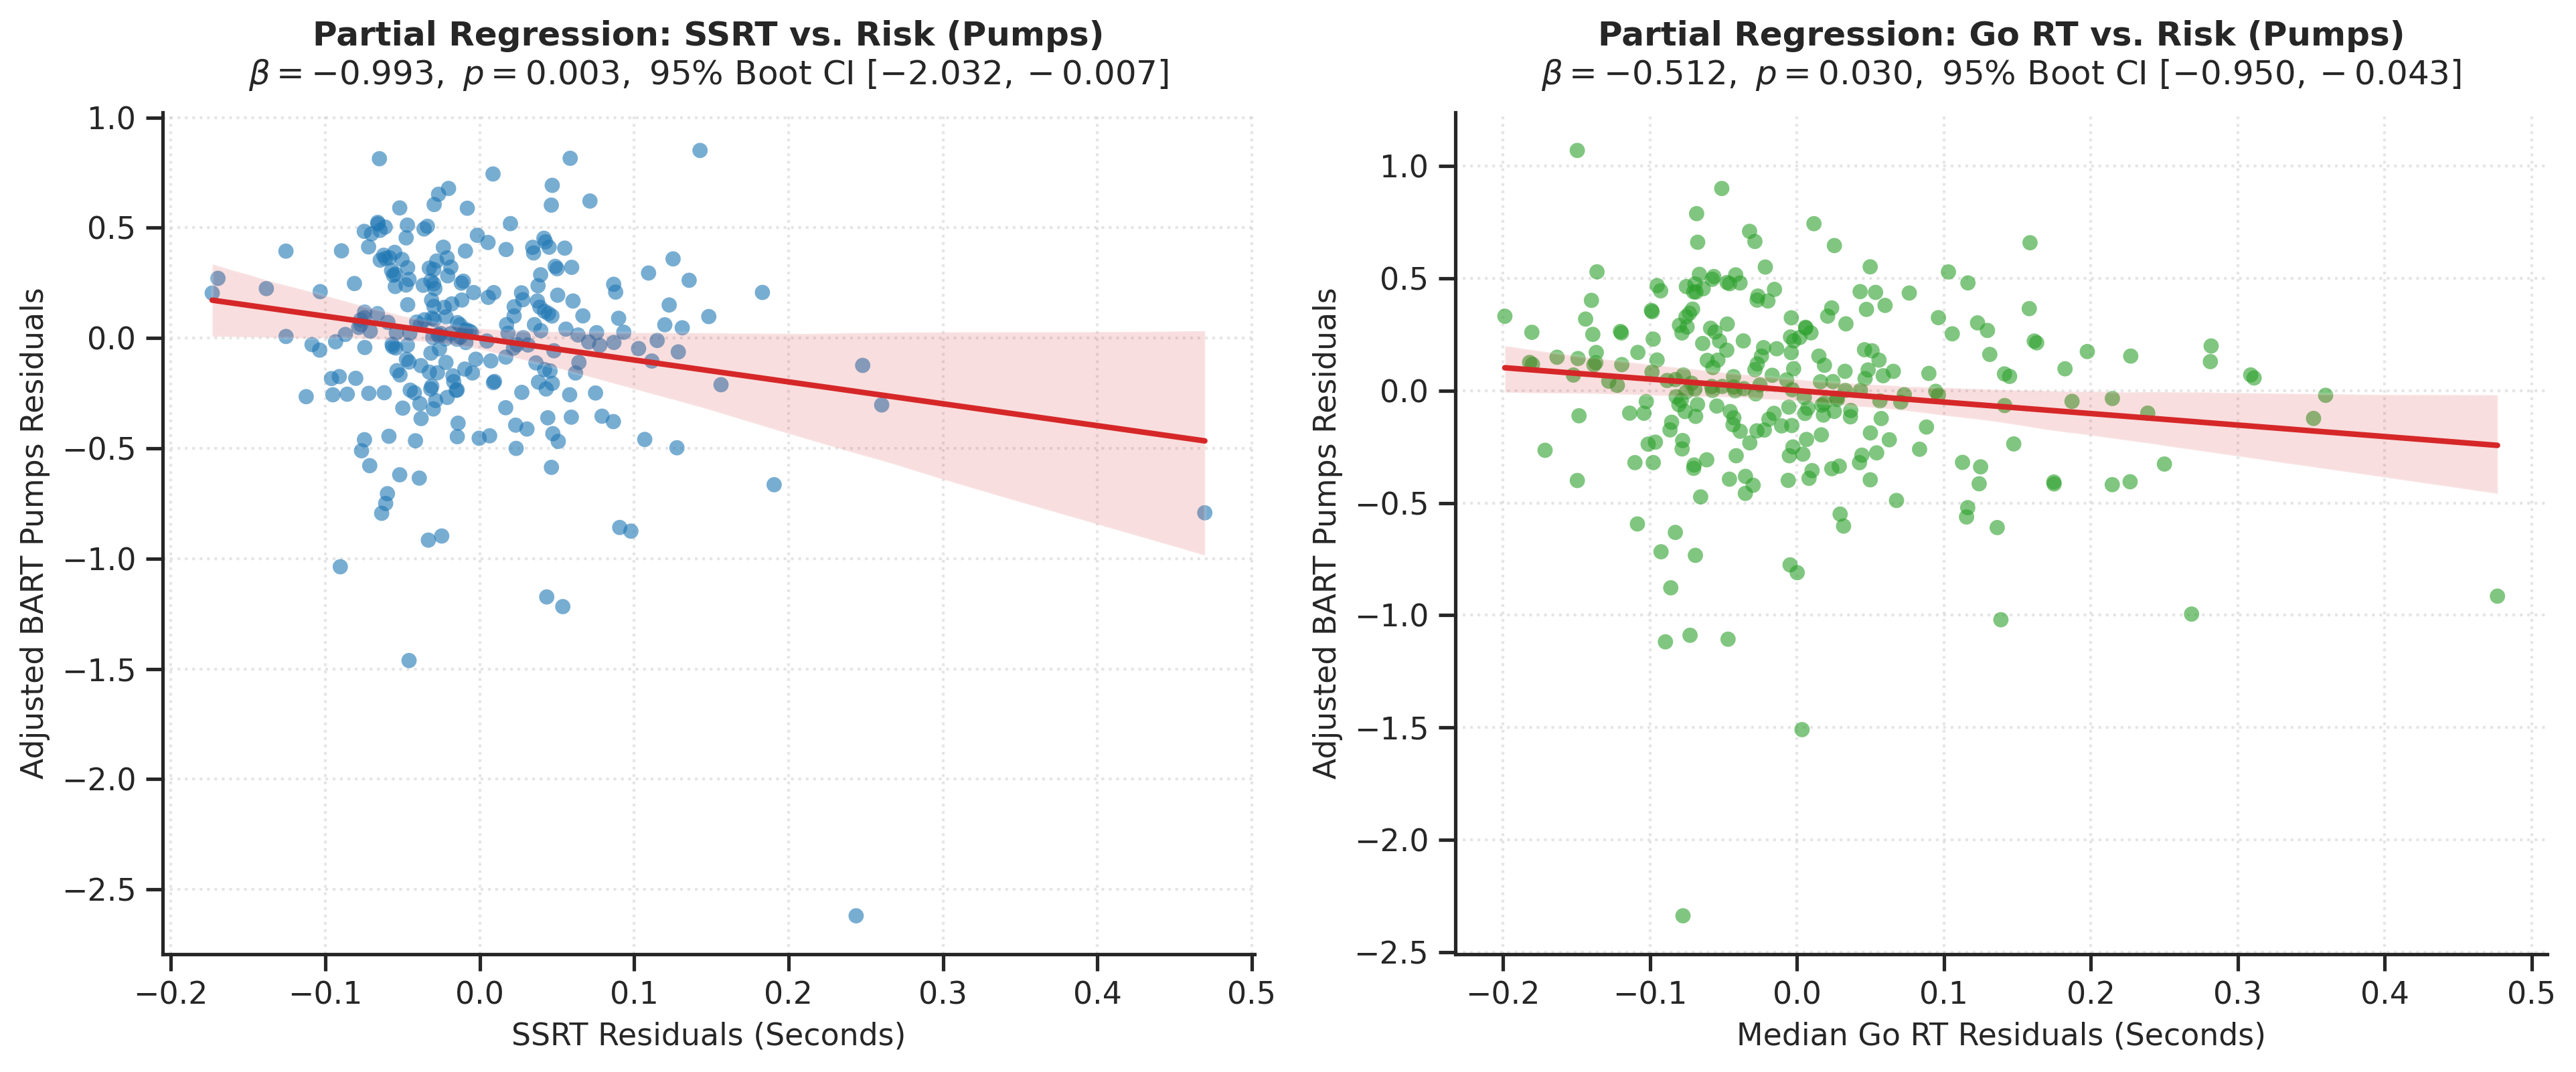

Figure saved as 'partial_regression_plots_isef.png'


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm

# Set publication style
sns.set_theme(style='ticks')
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=300)

# -------------------------------------------------------------------------
# 1. Partial Residuals for SSRT (Table 1 Specification)
# -------------------------------------------------------------------------
# Regress BART on all covariates EXCEPT SSRT
res_y_ssrt = smf.ols(
    'bart_mean_pumps ~ sst_median_go_rt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit().resid
# Regress SSRT on all covariates EXCEPT SSRT
res_x_ssrt = smf.ols(
    'sst_ssrt ~ sst_median_go_rt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit().resid

sns.regplot(
    x=res_x_ssrt,
    y=res_y_ssrt,
    ax=axes[0],
    color='#1f77b4',
    scatter_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'none'},
    line_kws={'color': '#d62728', 'linewidth': 2},
)
axes[0].set_title(
    'Partial Regression: SSRT vs. Risk (Pumps)\n'
    r'$\beta = -0.993,\ p = 0.003,\ 95\%\ \mathrm{Boot\ CI}\ [-2.032,'
    r' -0.007]$',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
axes[0].set_xlabel('SSRT Residuals (Seconds)', fontsize=11)
axes[0].set_ylabel('Adjusted BART Pumps Residuals', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.5)

# -------------------------------------------------------------------------
# 2. Partial Residuals for Go RT
# -------------------------------------------------------------------------
# Regress BART on all covariates EXCEPT Go RT
res_y_gort = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit().resid
# Regress Go RT on all covariates EXCEPT Go RT
res_x_gort = smf.ols(
    'sst_median_go_rt ~ sst_ssrt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit().resid

sns.regplot(
    x=res_x_gort,
    y=res_y_gort,
    ax=axes[1],
    color='#2ca02c',
    scatter_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'none'},
    line_kws={'color': '#d62728', 'linewidth': 2},
)
axes[1].set_title(
    'Partial Regression: Go RT vs. Risk (Pumps)\n'
    r'$\beta = -0.512,\ p = 0.030,\ 95\%\ \mathrm{Boot\ CI}\ [-0.950,'
    r' -0.043]$',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
axes[1].set_xlabel('Median Go RT Residuals (Seconds)', fontsize=11)
axes[1].set_ylabel('Adjusted BART Pumps Residuals', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.5)

sns.despine()
plt.tight_layout()
plt.savefig('partial_regression_plots_isef.png', dpi=300)
plt.show()
print("Figure saved as 'partial_regression_plots_isef.png'")

In [ ]:
# 4. Fit Table 1 Primary Model
m_table1 = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()

print("\n" + "=" * 60)
print(f"TABLE 1 PRIMARY MODEL (N = {len(df_reg)})")
print("=" * 60)
print(m_table1.summary().tables[1])
print(f"\nR-squared: {m_table1.rsquared:.4f}")


TABLE 1 PRIMARY MODEL (N = 257)
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.3849      0.140     38.548      0.000       5.110       5.660
C(diagnosis, Treatment(reference="CONTROL"))[T.ADHD]        0.0641      0.073      0.875      0.382      -0.080       0.208
C(diagnosis, Treatment(reference="CONTROL"))[T.BIPOLAR]     0.0686      0.070      0.986      0.325      -0.068       0.206
C(diagnosis, Treatment(reference="CONTROL"))[T.SCHZ]       -0.0530      0.071     -0.742      0.459      -0.194       0.088
sst_ssrt                                                   -0.9925      0.336     -2.957      0.003      -1.654      -0.331
sst_median_go_rt                                           -0.5115      0.234     -2.182      0.030

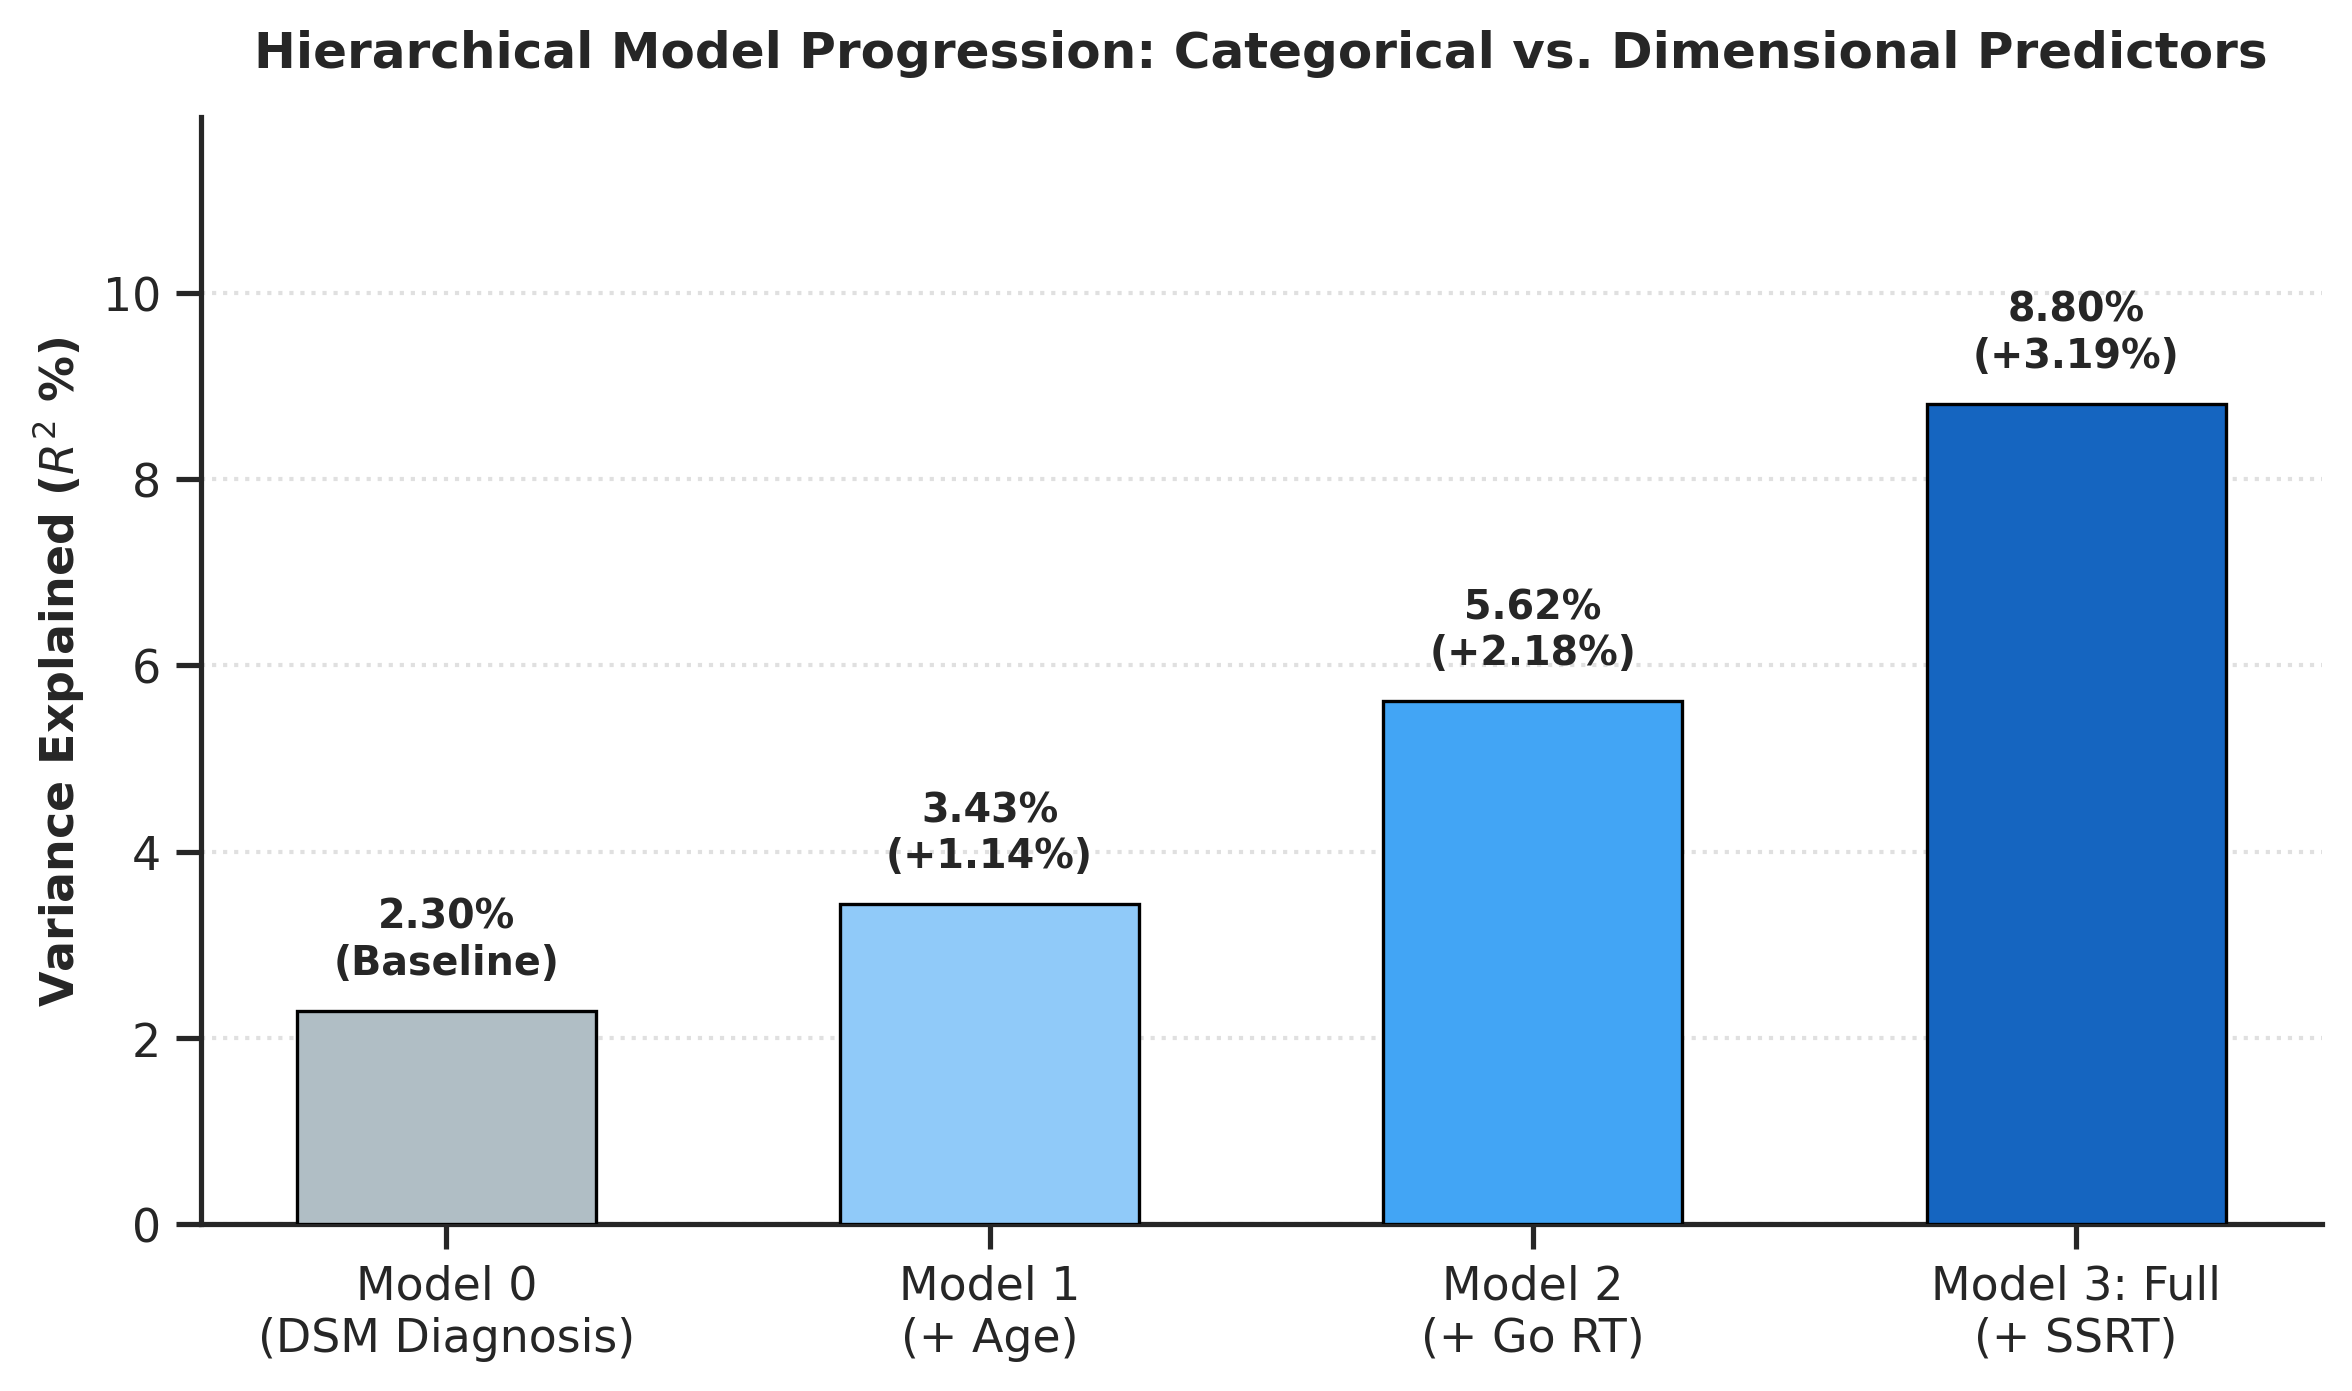

Saved 'hierarchical_r2_progression.png'


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.formula.api as smf

# Fit nested hierarchical models on df_reg
m0 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
m1 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age',
    data=df_reg,
).fit()
m2 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt',
    data=df_reg,
).fit()
m3 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt + sst_ssrt',
    data=df_reg,
).fit()

models = [
    'Model 0\n(DSM Diagnosis)',
    'Model 1\n(+ Age)',
    'Model 2\n(+ Go RT)',
    'Model 3: Full\n(+ SSRT)',
]
r2_vals = [m0.rsquared * 100, m1.rsquared * 100, m2.rsquared * 100, m3.rsquared * 100]
delta_r2 = [
    r2_vals[0],
    r2_vals[1] - r2_vals[0],
    r2_vals[2] - r2_vals[1],
    r2_vals[3] - r2_vals[2],
]

fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)
palette = ['#b0bec5', '#90caf9', '#42a5f5', '#1565c0']
bars = ax.bar(
    models,
    r2_vals,
    color=palette,
    edgecolor='black',
    linewidth=0.8,
    width=0.55,
    zorder=3,
)

for i, bar in enumerate(bars):
  h = bar.get_height()
  label = f'{h:.2f}%\n(Baseline)' if i == 0 else f'{h:.2f}%\n(+{delta_r2[i]:.2f}%)'
  ax.text(
      bar.get_x() + bar.get_width() / 2,
      h + 0.3,
      label,
      ha='center',
      va='bottom',
      fontsize=9.5,
      fontweight='bold',
  )

ax.set_ylim(0, max(r2_vals) * 1.35)
ax.set_ylabel('Variance Explained ($R^2$ %)', fontsize=11, fontweight='bold')
ax.set_title(
    'Hierarchical Model Progression: Categorical vs. Dimensional Predictors',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig('hierarchical_r2_progression.png', dpi=300)
plt.show()
print("Saved 'hierarchical_r2_progression.png'")

/tmp/ipykernel_895/2949434082.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_895/2949434082.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


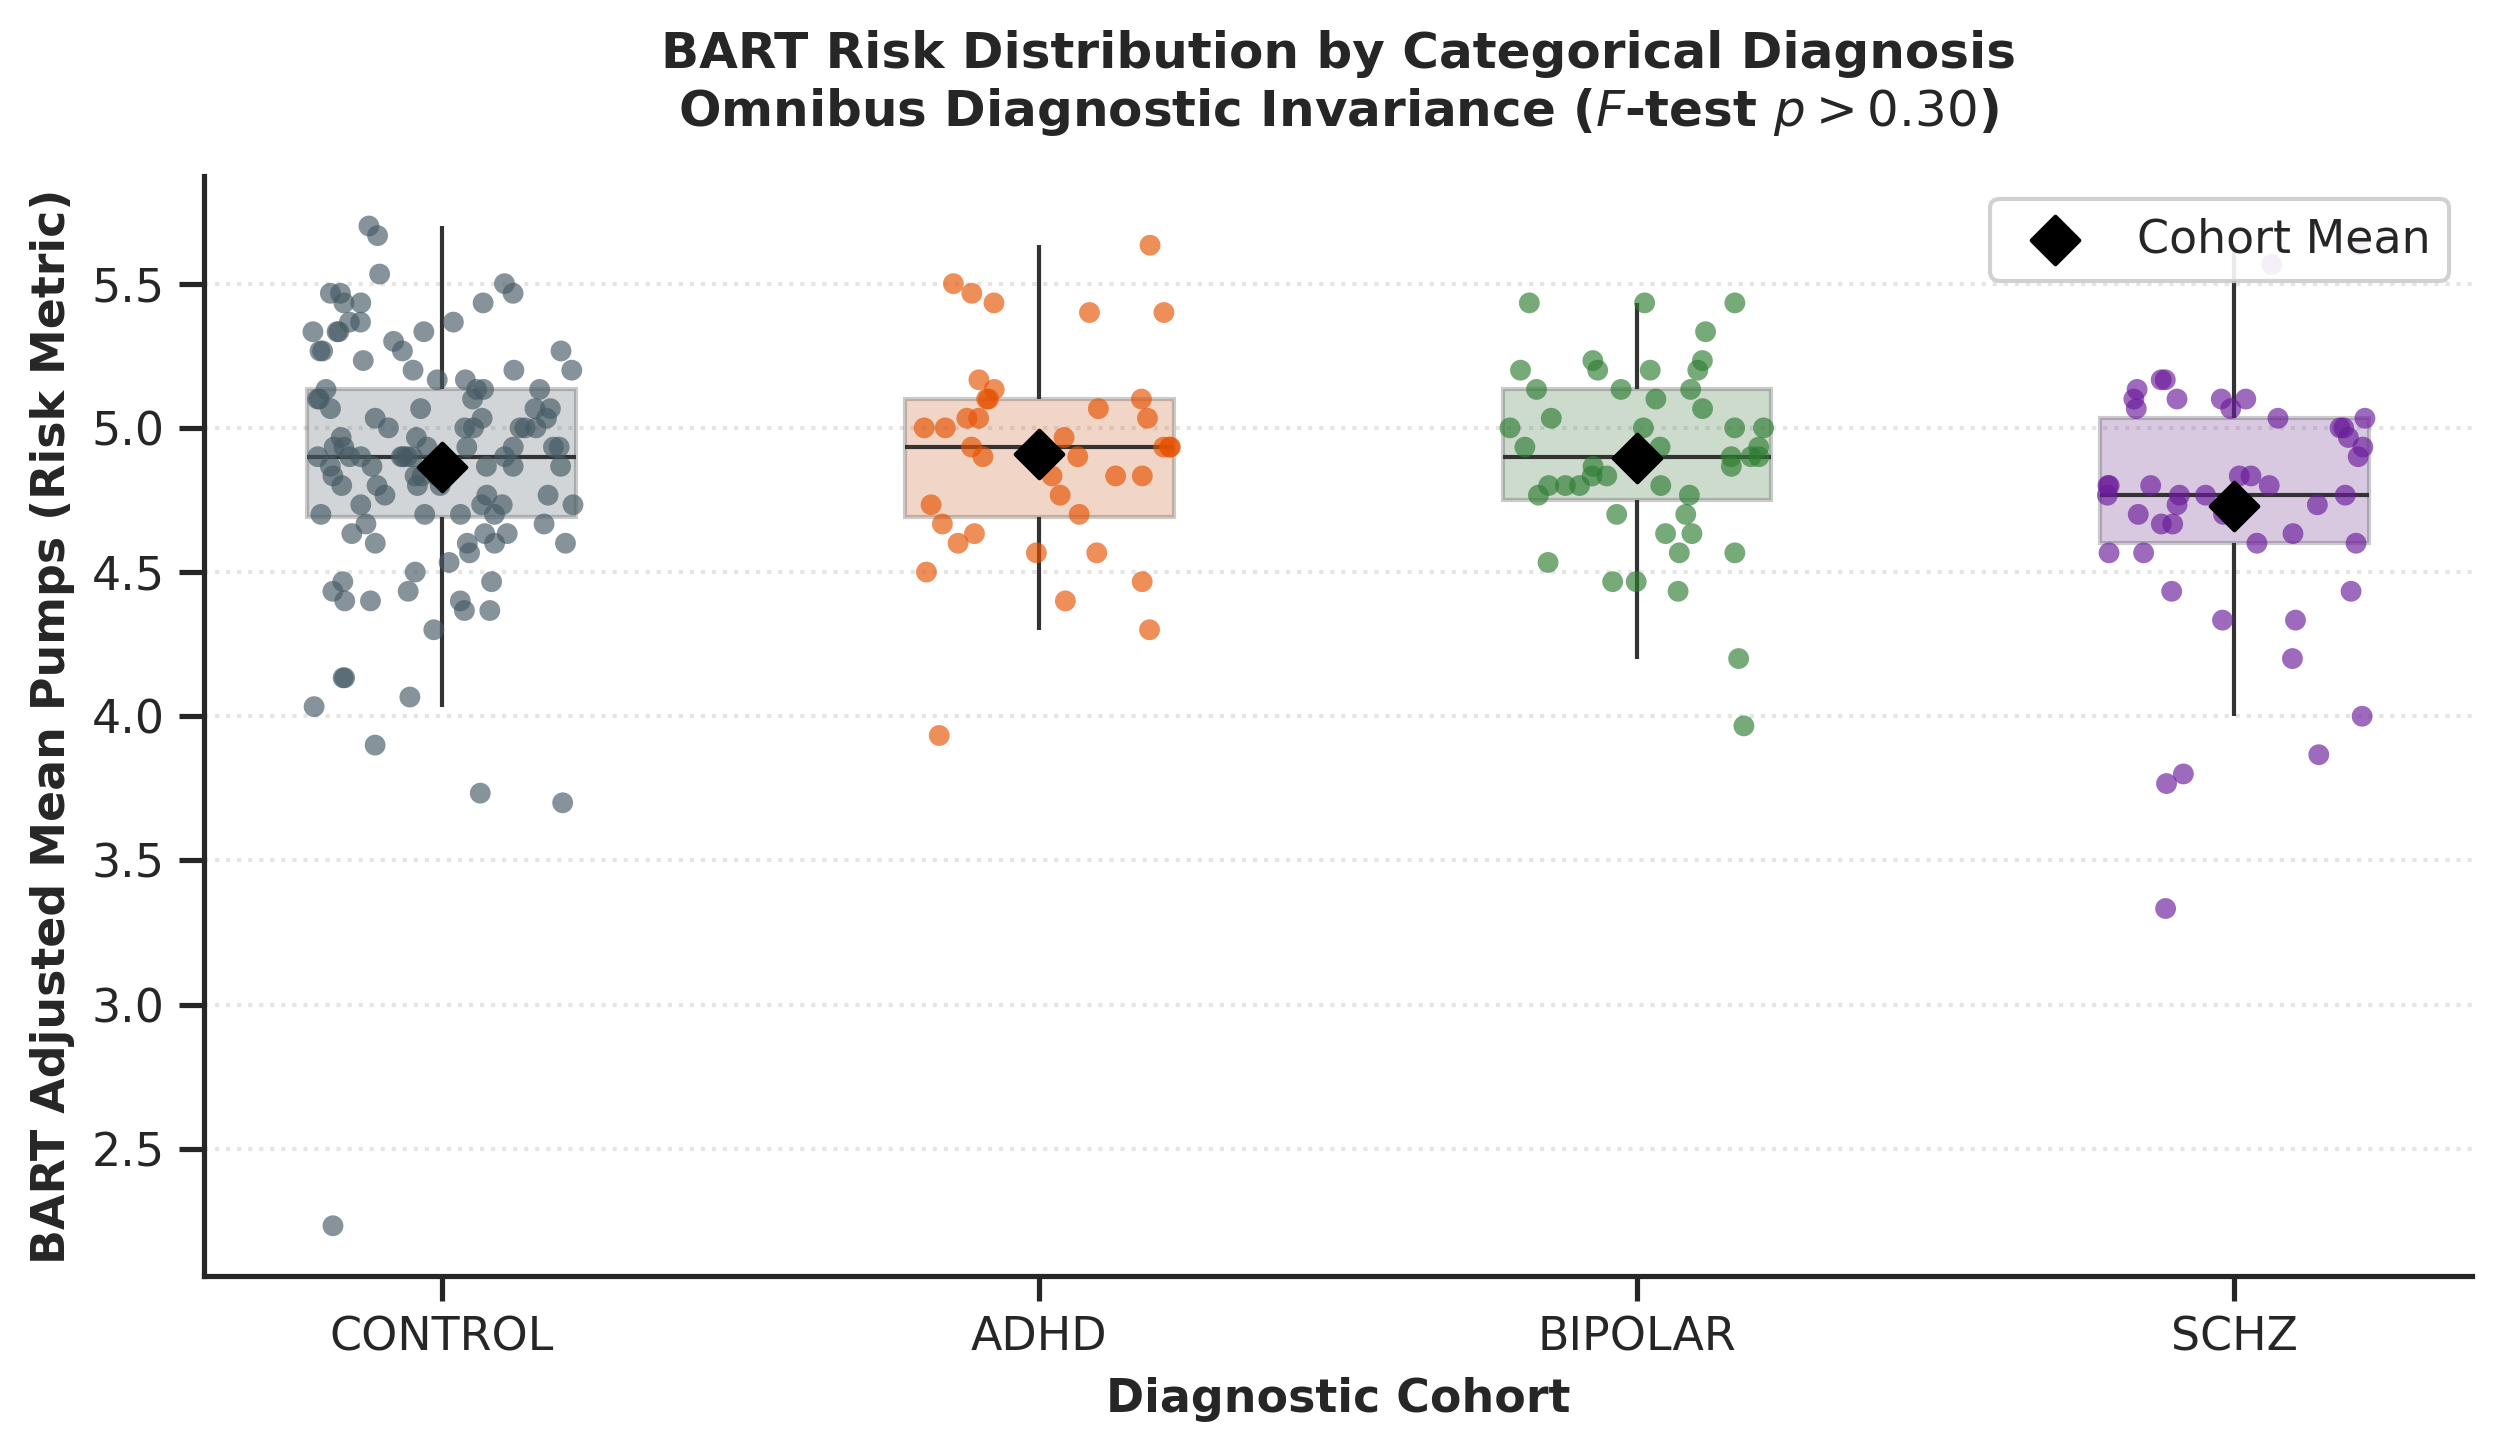

Saved 'diagnostic_invariance_bart.png'


In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5), dpi=300)

order = ['CONTROL', 'ADHD', 'BIPOLAR', 'SCHZ']
colors = ['#455a64', '#e65100', '#2e7d32', '#6a1b9a']

# Boxplot base
sns.boxplot(
    data=df_reg,
    x='diagnosis',
    y='bart_mean_pumps',
    order=order,
    palette=colors,
    width=0.45,
    boxprops=dict(alpha=0.25),
    showcaps=False,
    fliersize=0,
    ax=ax,
)

# Stripplot showing individual participants
sns.stripplot(
    data=df_reg,
    x='diagnosis',
    y='bart_mean_pumps',
    order=order,
    palette=colors,
    size=5,
    jitter=0.22,
    alpha=0.65,
    dodge=False,
    ax=ax,
)

# Overlay group means
means = df_reg.groupby('diagnosis')['bart_mean_pumps'].mean().reindex(order)
ax.scatter(
    range(len(order)),
    means,
    color='black',
    s=65,
    marker='D',
    zorder=5,
    label='Cohort Mean',
)

ax.set_title(
    'BART Risk Distribution by Categorical Diagnosis\nOmnibus Diagnostic'
    ' Invariance ($F$-test $p > 0.30$)',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Diagnostic Cohort', fontsize=11, fontweight='bold')
ax.set_ylabel(
    'BART Adjusted Mean Pumps (Risk Metric)', fontsize=11, fontweight='bold'
)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')
ax.grid(axis='y', linestyle=':', alpha=0.5)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('diagnostic_invariance_bart.png', dpi=300)
plt.show()
print("Saved 'diagnostic_invariance_bart.png'")

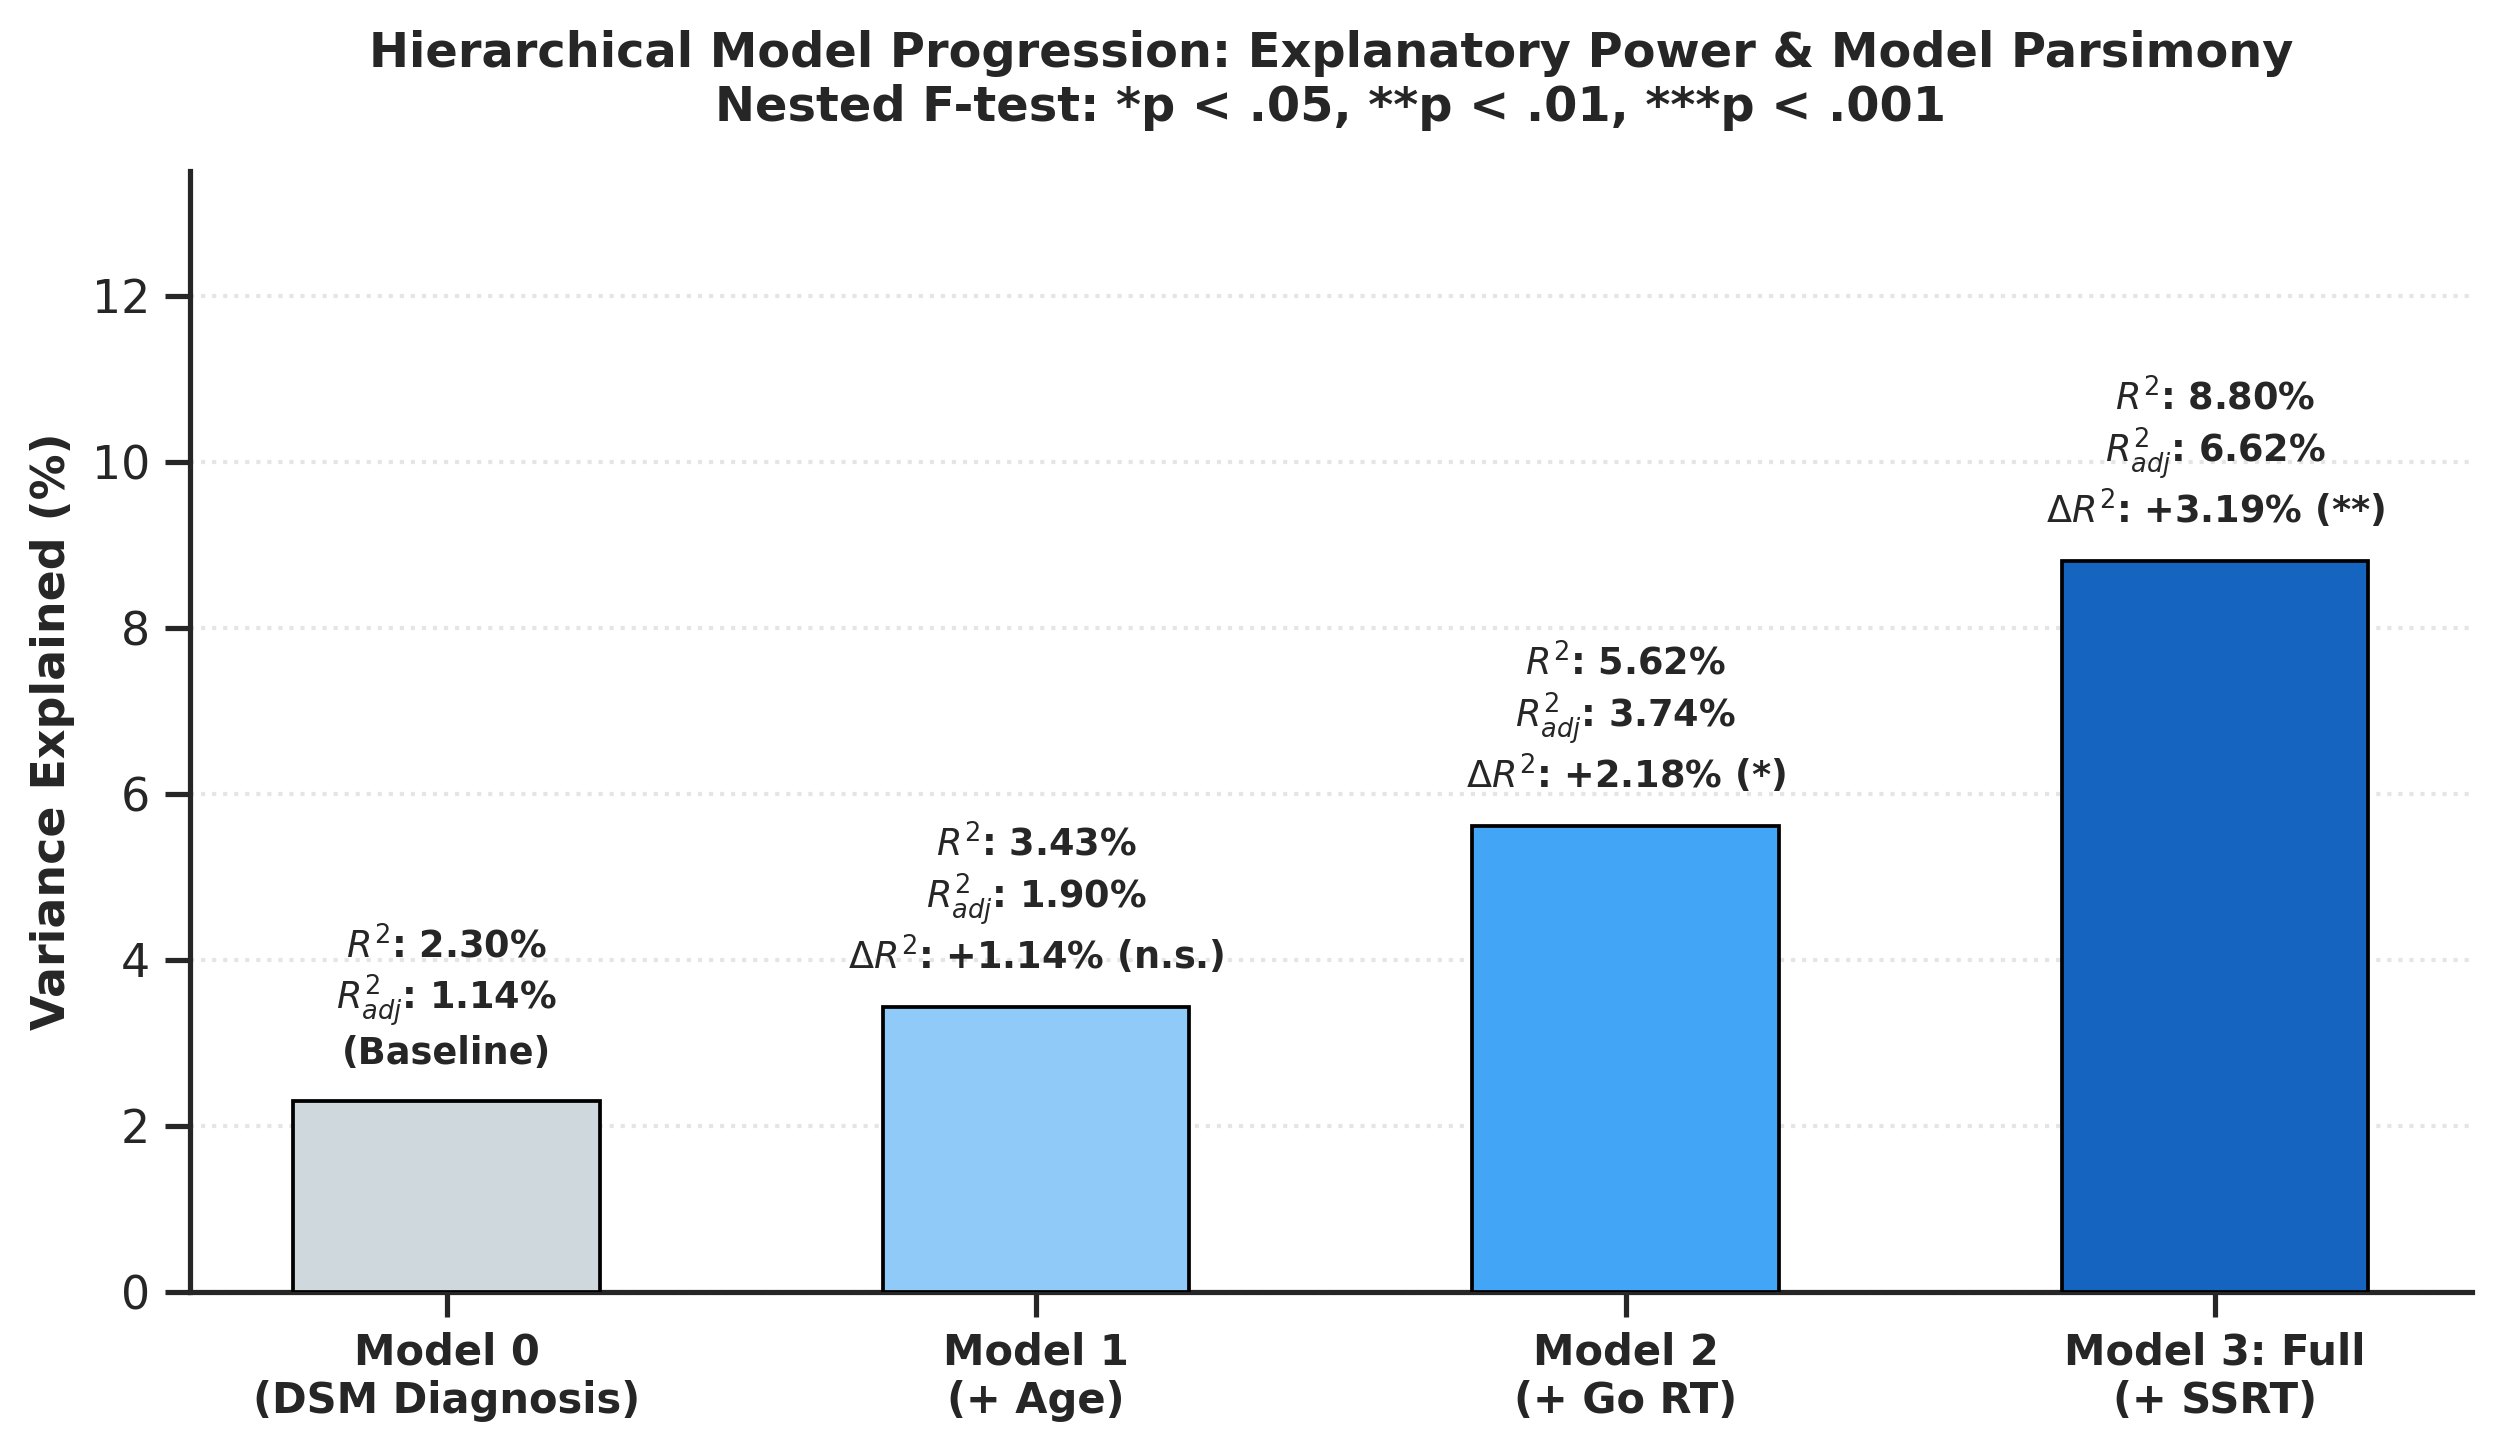

/tmp/ipykernel_895/96251827.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/tmp/ipykernel_895/96251827.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


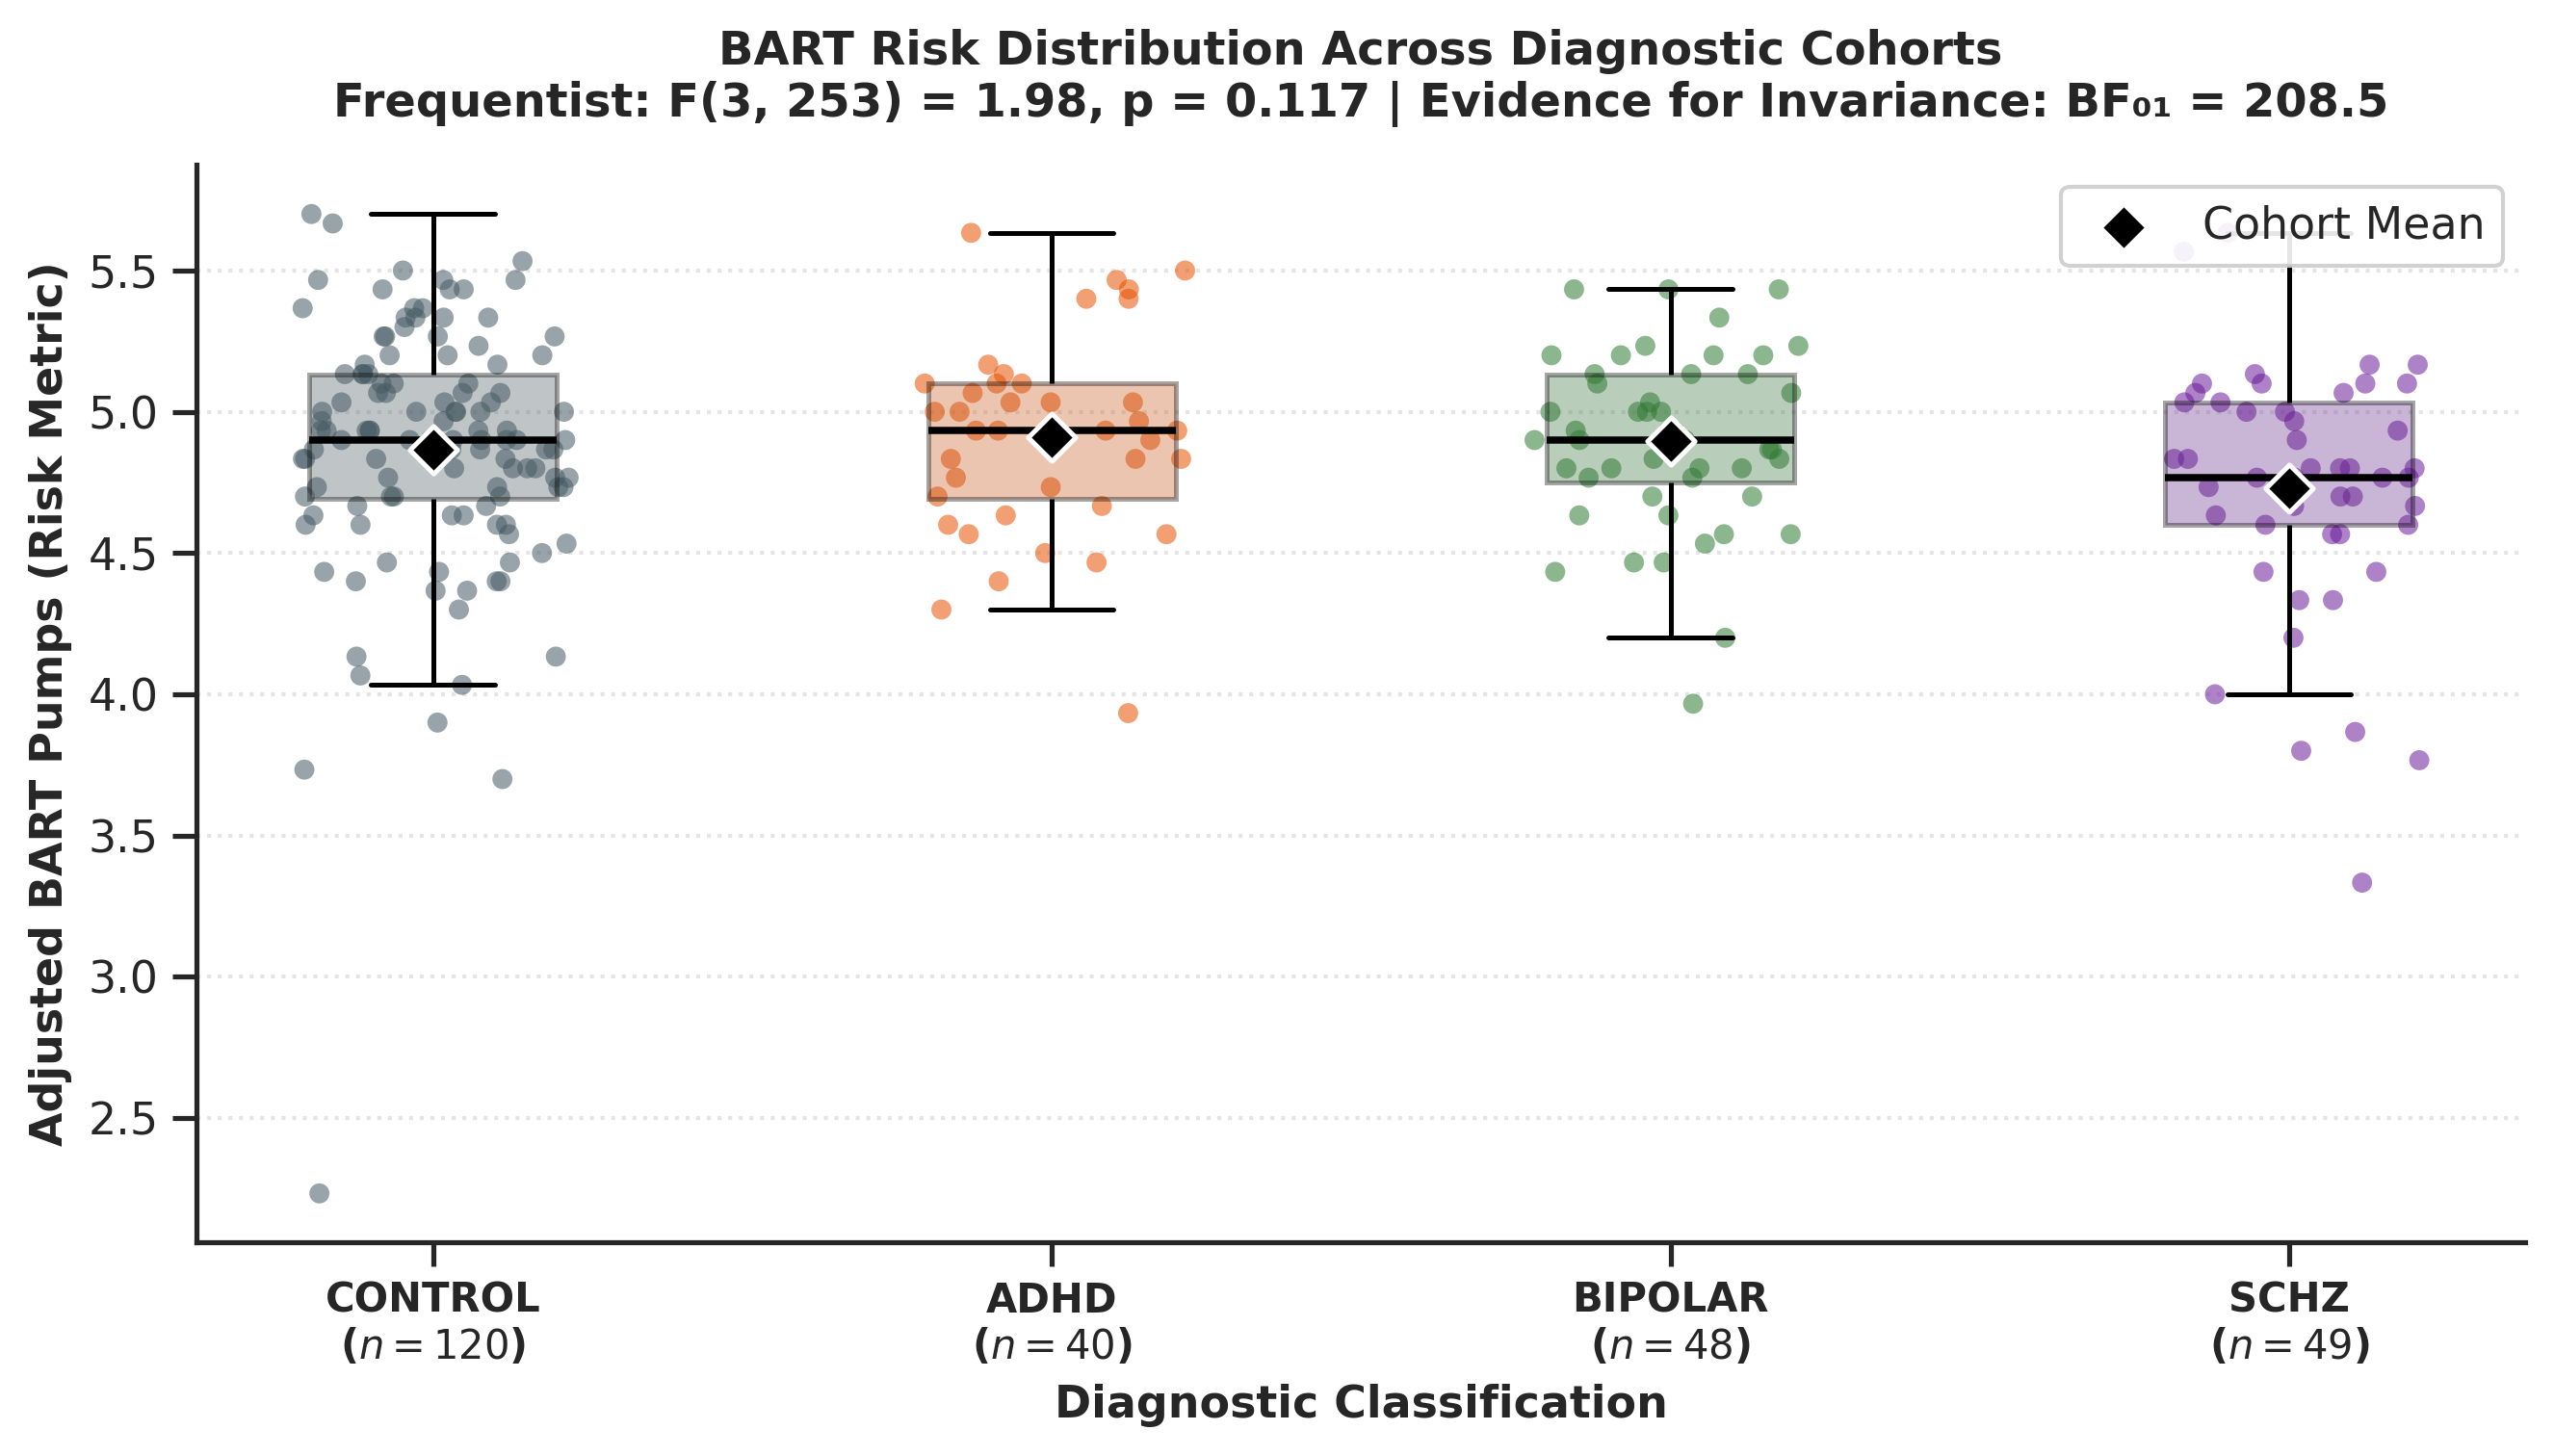

Saved updated figures.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.stats.anova import anova_lm

sns.set_theme(style='ticks')

# =========================================================================
# 1. UPGRADED HIERARCHICAL VARIANCE PROGRESSION (FIGURE A)
# =========================================================================
# Fit nested models
m0 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
m1 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age',
    data=df_reg,
).fit()
m2 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt',
    data=df_reg,
).fit()
m3 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt + sst_ssrt',
    data=df_reg,
).fit()

# Compute formal nested ANOVA
nested_anova = anova_lm(m0, m1, m2, m3)
f_pvals = nested_anova['Pr(>F)'].values  # Index 1, 2, 3 correspond to steps

models = [
    'Model 0\n(DSM Diagnosis)',
    'Model 1\n(+ Age)',
    'Model 2\n(+ Go RT)',
    'Model 3: Full\n(+ SSRT)',
]
r2_vals = [m.rsquared * 100 for m in [m0, m1, m2, m3]]
adj_r2_vals = [m.rsquared_adj * 100 for m in [m0, m1, m2, m3]]
bic_vals = [m.bic for m in [m0, m1, m2, m3]]

fig, ax1 = plt.subplots(figsize=(8.5, 5), dpi=300)
x = np.arange(len(models))
width = 0.52

# Plot R^2 bars
palette = ['#cfd8dc', '#90caf9', '#42a5f5', '#1565c0']
bars = ax1.bar(
    x,
    r2_vals,
    width=width,
    color=palette,
    edgecolor='black',
    linewidth=0.9,
    zorder=3,
)

# Annotate values and nested significance tests
for i, bar in enumerate(bars):
  h = bar.get_height()
  adj = adj_r2_vals[i]
  if i == 0:
    lbl = f'$R^2$: {h:.2f}%\n$R^2_{{adj}}$: {adj:.2f}%\n(Baseline)'
  else:
    p_val = f_pvals[i]
    sig_str = (
        '***'
        if p_val < 0.001
        else '**'
        if p_val < 0.01
        else '*'
        if p_val < 0.05
        else 'n.s.'
    )
    delta = r2_vals[i] - r2_vals[i - 1]
    lbl = (
        f'$R^2$: {h:.2f}%\n$R^2_{{adj}}$: {adj:.2f}%\n$\\Delta R^2$: +{delta:.2f}%'
        f' ({sig_str})'
    )

  ax1.text(
      bar.get_x() + bar.get_width() / 2,
      h + 0.35,
      lbl,
      ha='center',
      va='bottom',
      fontsize=8.8,
      fontweight='bold',
  )

ax1.set_ylim(0, 13.5)
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10, fontweight='bold')
ax1.set_ylabel('Variance Explained (%)', fontsize=11, fontweight='bold')
ax1.set_title(
    'Hierarchical Model Progression: Explanatory Power & Model Parsimony\nNested'
    ' F-test: *p < .05, **p < .01, ***p < .001',
    fontsize=11.5,
    fontweight='bold',
    pad=12,
)
ax1.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig('hierarchical_r2_rigorous.png', dpi=300)
plt.show()

# =========================================================================
# 2. UPGRADED DIAGNOSTIC INVARIANCE WITH BAYES FACTOR (FIGURE B)
# =========================================================================
# Frequentist Omnibus ANOVA
anova_fit = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()
null_fit = smf.ols('bart_mean_pumps ~ 1', data=df_reg).fit()

# Bayes Factor approximation for Null vs Alternative: BF01 = exp((BIC_alt - BIC_null) / 2)
delta_bic = anova_fit.bic - null_fit.bic
bf_01 = np.exp(delta_bic / 2)
f_stat = anova_fit.fvalue
p_val = anova_fit.f_pvalue

order = ['CONTROL', 'ADHD', 'BIPOLAR', 'SCHZ']
counts = df_reg['diagnosis'].value_counts()
labels = [f'{cat}\n($n = {counts[cat]}$)' for cat in order]
palette_diag = ['#455a64', '#e65100', '#2e7d32', '#6a1b9a']

fig, ax = plt.subplots(figsize=(9, 5.2), dpi=300)

# Stripplot showing individual data distribution
sns.stripplot(
    data=df_reg,
    x='diagnosis',
    y='bart_mean_pumps',
    order=order,
    palette=palette_diag,
    size=5,
    jitter=0.22,
    alpha=0.55,
    ax=ax,
    zorder=2,
)

# Standard Boxplot overlaid with proper whiskers
sns.boxplot(
    data=df_reg,
    x='diagnosis',
    y='bart_mean_pumps',
    order=order,
    palette=palette_diag,
    width=0.4,
    boxprops=dict(alpha=0.35, edgecolor='black', linewidth=1.2),
    medianprops=dict(color='black', linewidth=1.8),
    whiskerprops=dict(color='black', linewidth=1.2),
    capprops=dict(color='black', linewidth=1.2),
    showcaps=True,
    fliersize=0,
    ax=ax,
    zorder=3,
)

# Plot Mean Marker
means = df_reg.groupby('diagnosis')['bart_mean_pumps'].mean().reindex(order)
ax.scatter(
    range(len(order)),
    means,
    color='black',
    s=70,
    marker='D',
    edgecolor='white',
    linewidth=1.2,
    zorder=5,
    label='Cohort Mean',
)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_ylabel(
    'Adjusted BART Pumps (Risk Metric)', fontsize=11, fontweight='bold'
)
ax.set_xlabel('Diagnostic Classification', fontsize=11, fontweight='bold')
ax.set_title(
    f'BART Risk Distribution Across Diagnostic Cohorts\nFrequentist: F(3, 253)'
    f' = {f_stat:.2f}, p = {p_val:.3f} | Evidence for Invariance: BF₀₁ ='
    f' {bf_01:.1f}',
    fontsize=11.5,
    fontweight='bold',
    pad=12,
)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')
ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('diagnostic_invariance_bayes.png', dpi=300)
plt.show()
print('Saved updated figures.')

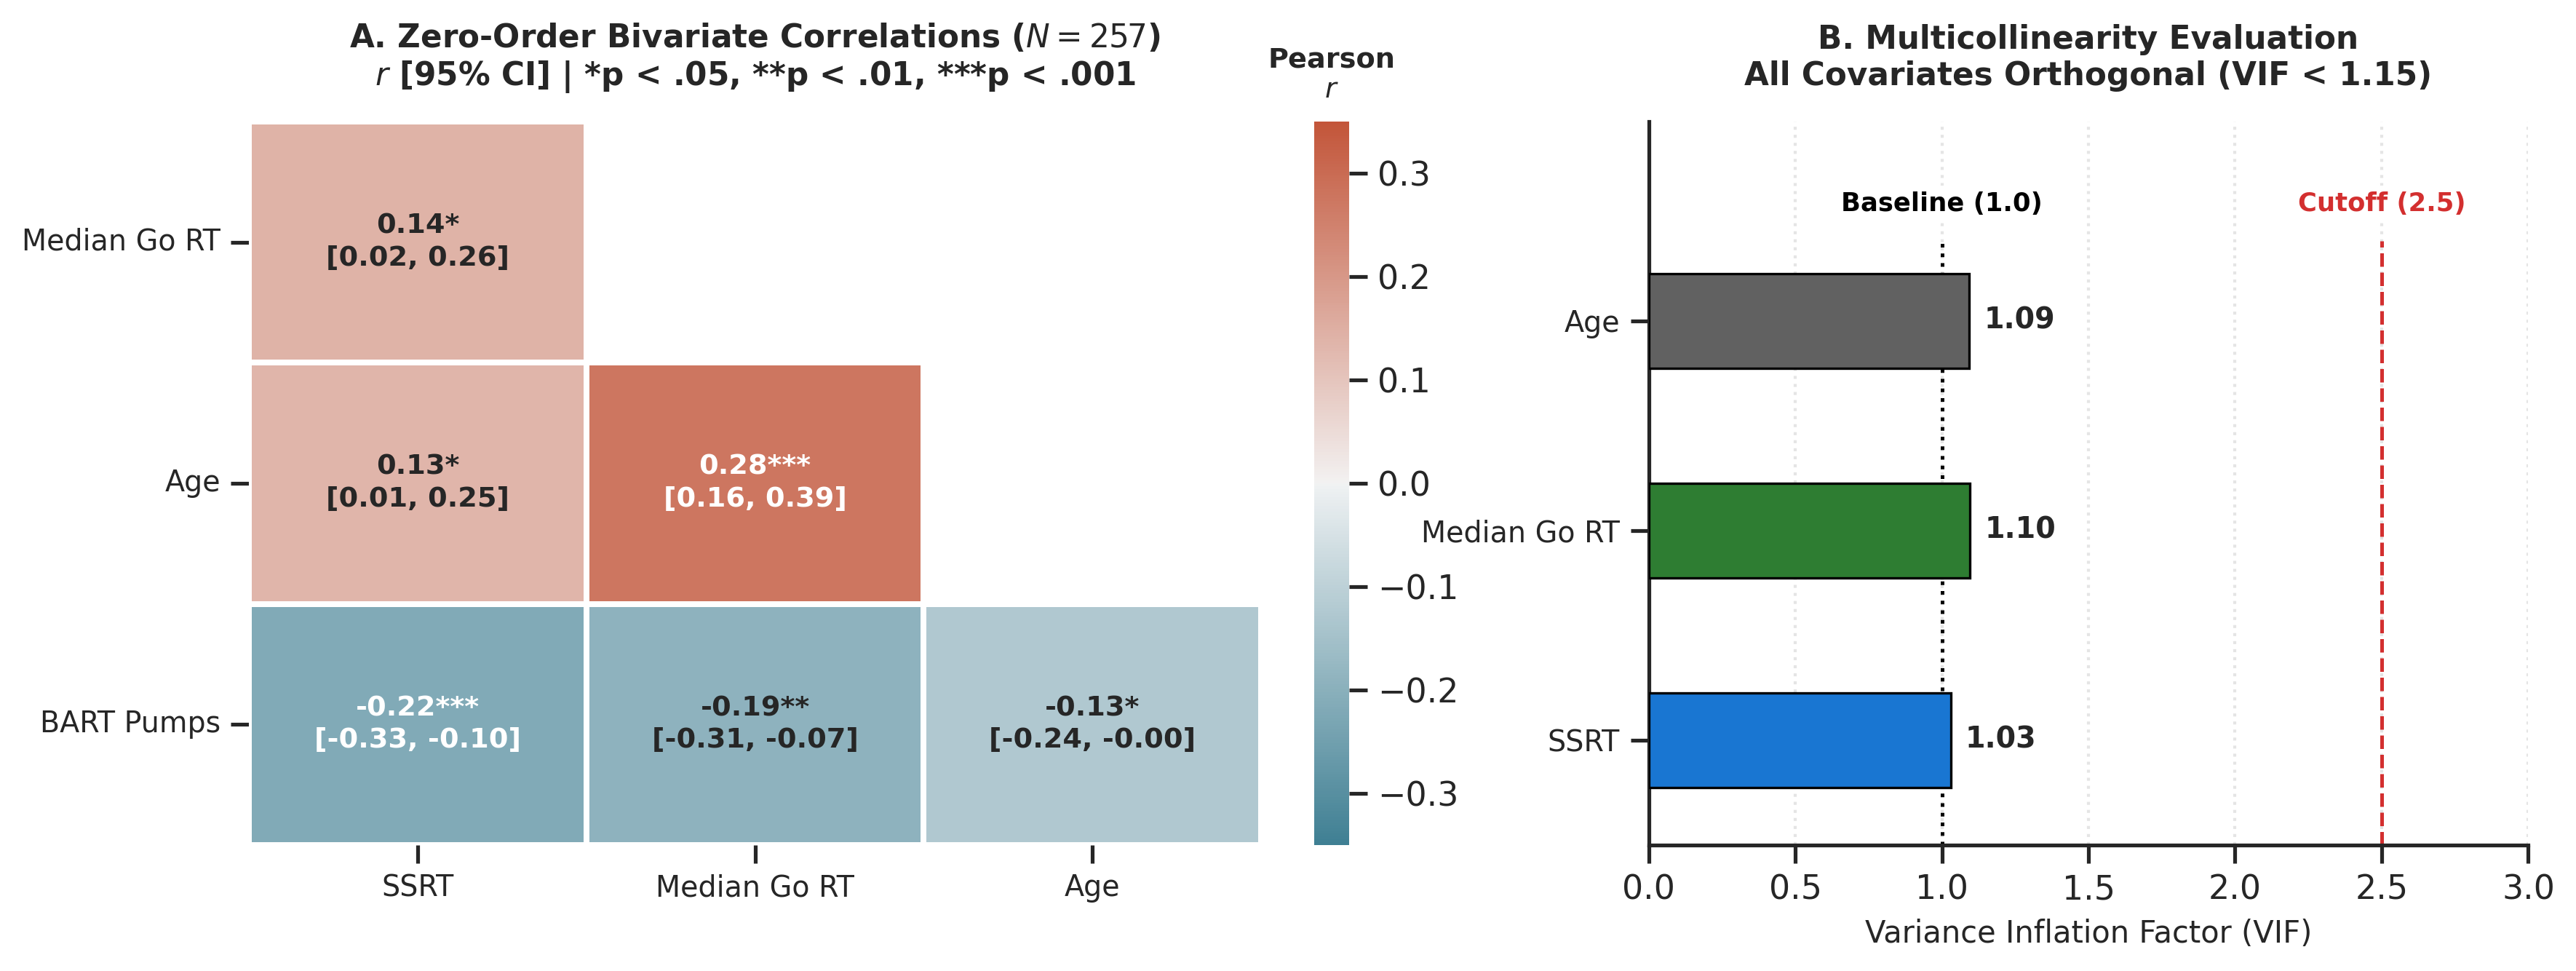

Saved clean publication composite as 'figure1_correlation_vif_final.png'


In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, pearsonr
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style='ticks')

# -------------------------------------------------------------------------
# 1. COMPUTE STATISTICS
# -------------------------------------------------------------------------
X_vif = df_reg[['sst_ssrt', 'sst_median_go_rt', 'age']].copy()
X_vif['Intercept'] = 1.0

vif_data = pd.DataFrame({
    'Predictor': ['SSRT', 'Median Go RT', 'Age'],
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(3)],
})

vars_eval = ['sst_ssrt', 'sst_median_go_rt', 'age', 'bart_mean_pumps']
labels = ['SSRT', 'Median Go RT', 'Age', 'BART Pumps']
n = len(vars_eval)
N = len(df_reg)

r_mat = np.zeros((n, n))
annot_mat = np.empty((n, n), dtype=object)


def pearson_ci(r, N, alpha=0.05):
  z = np.arctanh(r)
  se = 1.0 / np.sqrt(N - 3)
  z_crit = norm.ppf(1 - alpha / 2)
  return np.tanh(z - z_crit * se), np.tanh(z + z_crit * se)


for i in range(n):
  for j in range(n):
    if i > j:
      r, p = pearsonr(df_reg[vars_eval[i]], df_reg[vars_eval[j]])
      r_mat[i, j] = r
      lo, hi = pearson_ci(r, N)
      stars = (
          '***'
          if p < 0.001
          else '**'
          if p < 0.01
          else '*'
          if p < 0.05
          else ''
      )
      annot_mat[i, j] = f'{r:.2f}{stars}\n[{lo:.2f}, {hi:.2f}]'
    else:
      r_mat[i, j] = np.nan
      annot_mat[i, j] = ''

r_sub = r_mat[1:, :-1]
annot_sub = annot_mat[1:, :-1]
mask_sub = np.triu(np.ones_like(r_sub, dtype=bool), k=1)

y_labels = labels[1:]
x_labels = labels[:-1]

# -------------------------------------------------------------------------
# 2. COMPOSITE FIGURE LAYOUT
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 4.6), dpi=300)

gs = gridspec.GridSpec(
    1, 4, width_ratios=[1.15, 0.04, 0.22, 1.0], figure=fig, wspace=0.10
)

ax_corr = fig.add_subplot(gs[0])
cax = fig.add_subplot(gs[1])
ax_vif = fig.add_subplot(gs[3])

cmap = sns.diverging_palette(220, 20, as_cmap=True)

# Panel A: Lower Triangle Heatmap
sns.heatmap(
    r_sub,
    mask=mask_sub,
    annot=annot_sub,
    fmt='',
    cmap=cmap,
    vmin=-0.35,
    vmax=0.35,
    center=0,
    cbar=True,
    cbar_ax=cax,
    linewidths=1.5,
    linecolor='white',
    xticklabels=x_labels,
    yticklabels=y_labels,
    annot_kws={'fontsize': 9.2, 'fontweight': 'bold', 'linespacing': 1.3},
    ax=ax_corr,
)

cax.set_title(
    'Pearson\n$r$', fontsize=9.2, fontweight='bold', pad=8, loc='center'
)
ax_corr.set_title(
    'A. Zero-Order Bivariate Correlations ($N = 257$)\n'
    '$r$ [95% CI] | *p < .05, **p < .01, ***p < .001',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)
ax_corr.tick_params(axis='x', rotation=0, labelsize=9.5)
ax_corr.tick_params(axis='y', rotation=0, labelsize=9.5)

# Panel B: Multicollinearity (VIF)
palette_vif = ['#1976d2', '#2e7d32', '#616161']
bars = ax_vif.barh(
    vif_data['Predictor'],
    vif_data['VIF'],
    color=palette_vif,
    edgecolor='black',
    linewidth=0.8,
    height=0.45,
    zorder=3,
)

# Terminate reference lines below the text zone (y = 2.38)
ax_vif.plot(
    [1.0, 1.0],
    [-0.5, 2.38],
    color='black',
    linestyle=':',
    linewidth=1.2,
    zorder=2,
)
ax_vif.plot(
    [2.5, 2.5],
    [-0.5, 2.38],
    color='#d32f2f',
    linestyle='--',
    linewidth=1.2,
    zorder=2,
)

# Text labels with white background padding to guarantee zero intersection
ax_vif.text(
    1.0,
    2.56,
    'Baseline (1.0)',
    ha='center',
    va='center',
    fontsize=8.5,
    fontweight='bold',
    color='black',
    bbox=dict(boxstyle='square,pad=0.2', facecolor='white', edgecolor='none'),
)
ax_vif.text(
    2.5,
    2.56,
    'Cutoff (2.5)',
    ha='center',
    va='center',
    fontsize=8.5,
    fontweight='bold',
    color='#d32f2f',
    bbox=dict(boxstyle='square,pad=0.2', facecolor='white', edgecolor='none'),
)

# Bar value labels
for bar in bars:
  w = bar.get_width()
  ax_vif.text(
      w + 0.05,
      bar.get_y() + bar.get_height() / 2,
      f'{w:.2f}',
      va='center',
      ha='left',
      fontsize=9.5,
      fontweight='bold',
  )

ax_vif.set_xlim(0, 3.0)
ax_vif.set_ylim(-0.5, 2.95)  # Extended headroom
ax_vif.set_xlabel('Variance Inflation Factor (VIF)', fontsize=10)
ax_vif.set_title(
    'B. Multicollinearity Evaluation\nAll Covariates Orthogonal (VIF < 1.15)',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)

ax_vif.grid(axis='x', linestyle=':', alpha=0.5, zorder=0)
ax_vif.tick_params(axis='y', labelsize=9.5)
sns.despine(ax=ax_vif, top=True, right=True)

plt.subplots_adjust(top=0.86, bottom=0.14, left=0.09, right=0.96)
plt.savefig('figure1_correlation_vif_final.png', dpi=300)
plt.show()
print("Saved clean publication composite as 'figure1_correlation_vif_final.png'")

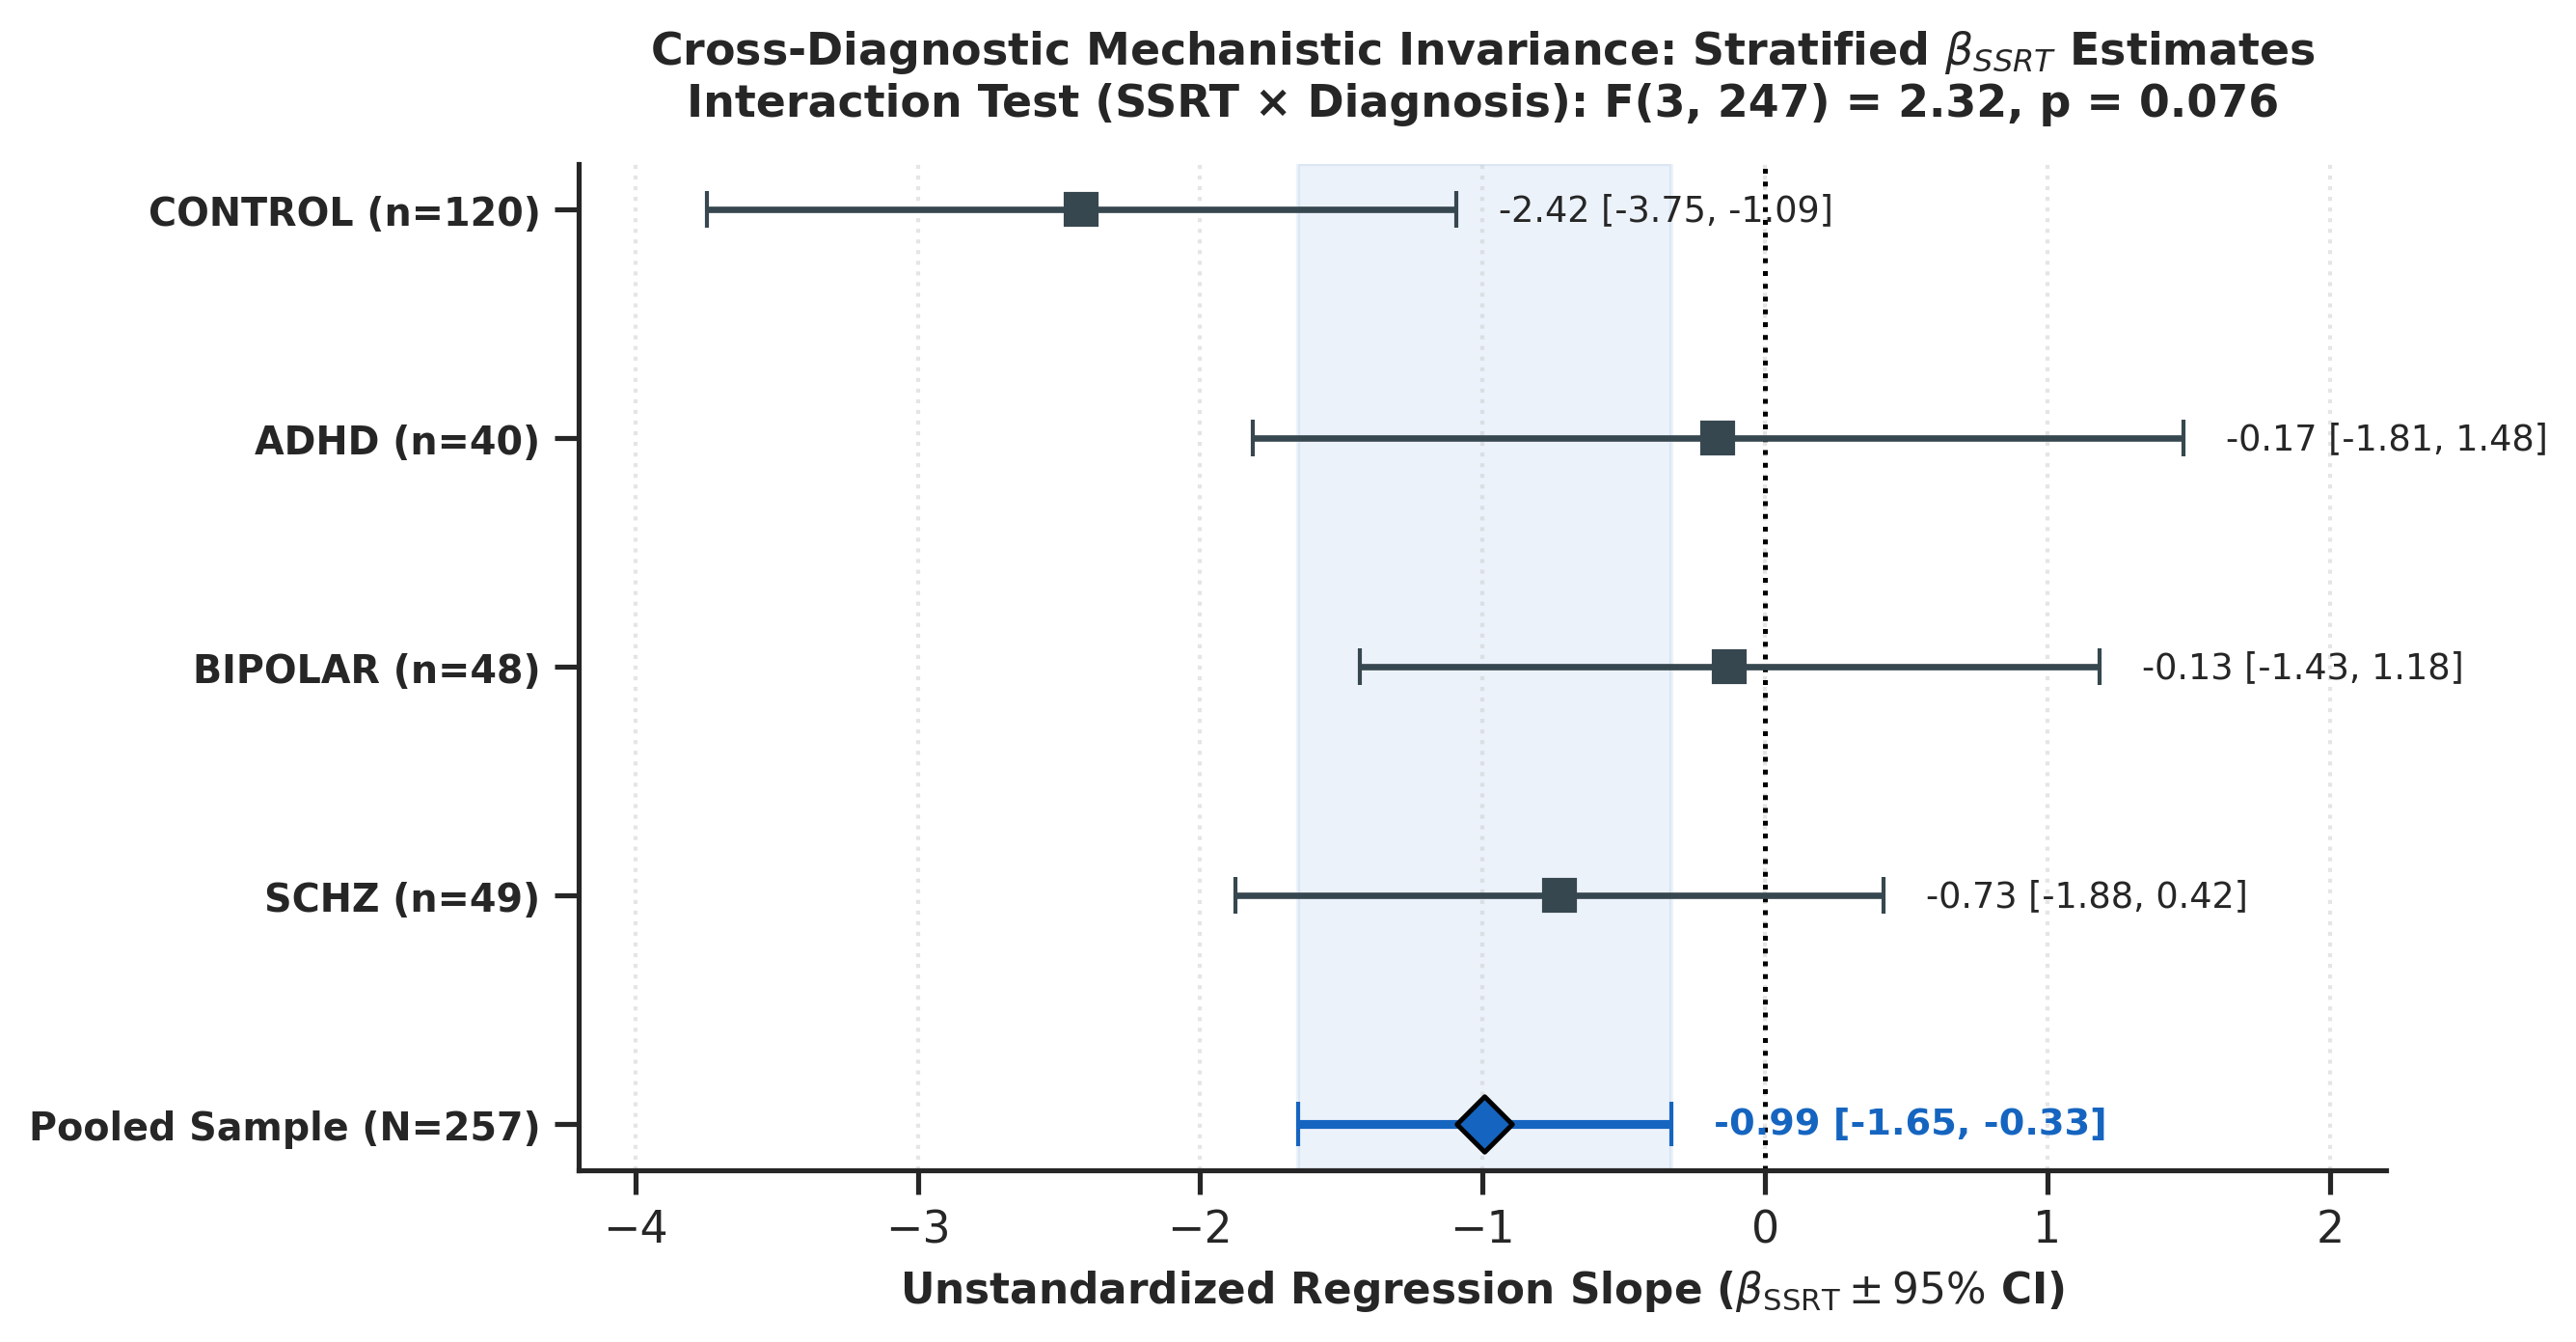

F(3, 247) = 2.32, p = 0.0761 | Saved final forest plot.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.anova import anova_lm
import statsmodels.formula.api as smf

# 1. Compute Nested Interaction Models
m3 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt + sst_ssrt',
    data=df_reg,
).fit()

m4 = smf.ols(
    'bart_mean_pumps ~ age + sst_median_go_rt + sst_ssrt * C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()

# Formal ANOVA comparing Main Effects vs. Interaction
comp = anova_lm(m3, m4)
f_stat = comp['F'].iloc[1]
p_val = comp['Pr(>F)'].iloc[1]
df_num = int(m4.df_model - m3.df_model)
df_denom = int(m4.df_resid)

sig_str = (
    'p < .001'
    if p_val < 0.001
    else f'p = {p_val:.3f}'
    if p_val >= 0.01
    else f'p = {p_val:.4f}'
)

# 2. Extract Stratified Estimates
cohorts = ['CONTROL', 'ADHD', 'BIPOLAR', 'SCHZ']
results = []

for c in cohorts:
  sub = df_reg[df_reg['diagnosis'] == c]
  m_sub = smf.ols(
      'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age', data=sub
  ).fit()
  results.append({
      'Cohort': f'{c} (n={len(sub)})',
      'beta': m_sub.params['sst_ssrt'],
      'ci_lo': m_sub.conf_int().loc['sst_ssrt', 0],
      'ci_hi': m_sub.conf_int().loc['sst_ssrt', 1],
  })

# Add Pooled Model (Model 3)
results.append({
    'Cohort': f'Pooled Sample (N={len(df_reg)})',
    'beta': m3.params['sst_ssrt'],
    'ci_lo': m3.conf_int().loc['sst_ssrt', 0],
    'ci_hi': m3.conf_int().loc['sst_ssrt', 1],
})
df_forest = pd.DataFrame(results)

# 3. Generate Forest Plot
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
y_pos = np.arange(len(df_forest))

# Reference zero effect line
ax.axvline(0, color='black', linestyle=':', linewidth=1.2, zorder=1)

# Shaded pooled effect zone
ax.axvspan(
    df_forest.iloc[-1]['ci_lo'],
    df_forest.iloc[-1]['ci_hi'],
    color='#1565c0',
    alpha=0.08,
    zorder=0,
)

# Plot Cohort Estimates
for i in range(len(df_forest) - 1):
  row = df_forest.iloc[i]
  ax.errorbar(
      row['beta'],
      y_pos[i],
      xerr=[[row['beta'] - row['ci_lo']], [row['ci_hi'] - row['beta']]],
      fmt='s',
      color='#37474f',
      ecolor='#37474f',
      elinewidth=1.6,
      capsize=4.5,
      markersize=7.5,
      zorder=3,
  )
  ax.text(
      row['ci_hi'] + 0.15,
      y_pos[i],
      f"{row['beta']:.2f} [{row['ci_lo']:.2f}, {row['ci_hi']:.2f}]",
      va='center',
      fontsize=8.8,
  )

# Plot Pooled Estimate Diamond
row_p = df_forest.iloc[-1]
ax.scatter(
    row_p['beta'],
    y_pos[-1],
    marker='D',
    s=95,
    color='#1565c0',
    edgecolor='black',
    linewidth=1.2,
    zorder=4,
)
ax.errorbar(
    row_p['beta'],
    y_pos[-1],
    xerr=[[row_p['beta'] - row_p['ci_lo']], [row_p['ci_hi'] - row_p['beta']]],
    fmt='none',
    ecolor='#1565c0',
    elinewidth=2.2,
    capsize=5.5,
    zorder=3,
)
ax.text(
    row_p['ci_hi'] + 0.15,
    y_pos[-1],
    f"{row_p['beta']:.2f} [{row_p['ci_lo']:.2f}, {row_p['ci_hi']:.2f}]",
    va='center',
    fontsize=9.2,
    fontweight='bold',
    color='#1565c0',
)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_forest['Cohort'], fontsize=9.5, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel(
    r'Unstandardized Regression Slope ($\beta_{\mathrm{SSRT}} \pm 95\%$ CI)',
    fontsize=10.5,
    fontweight='bold',
)
ax.set_title(
    'Cross-Diagnostic Mechanistic Invariance: Stratified $\\beta_{{SSRT}}$'
    f' Estimates\nInteraction Test (SSRT \u00d7 Diagnosis): F({df_num},'
    f' {df_denom}) = {f_stat:.2f}, {sig_str}',
    fontsize=11,
    fontweight='bold',
    pad=12,
)

# Expanded xlim so CONTROL's CI is unclipped, with room for text labels on the right
ax.set_xlim(-4.2, 2.2)
ax.grid(axis='x', linestyle=':', alpha=0.5, zorder=0)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('figure5_mechanistic_invariance_forest_final.png', dpi=300)
plt.show()
print(
    f'F({df_num}, {df_denom}) = {f_stat:.2f}, p = {p_val:.4f} | Saved final'
    ' forest plot.'
)

/tmp/ipykernel_895/494876789.py:183: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


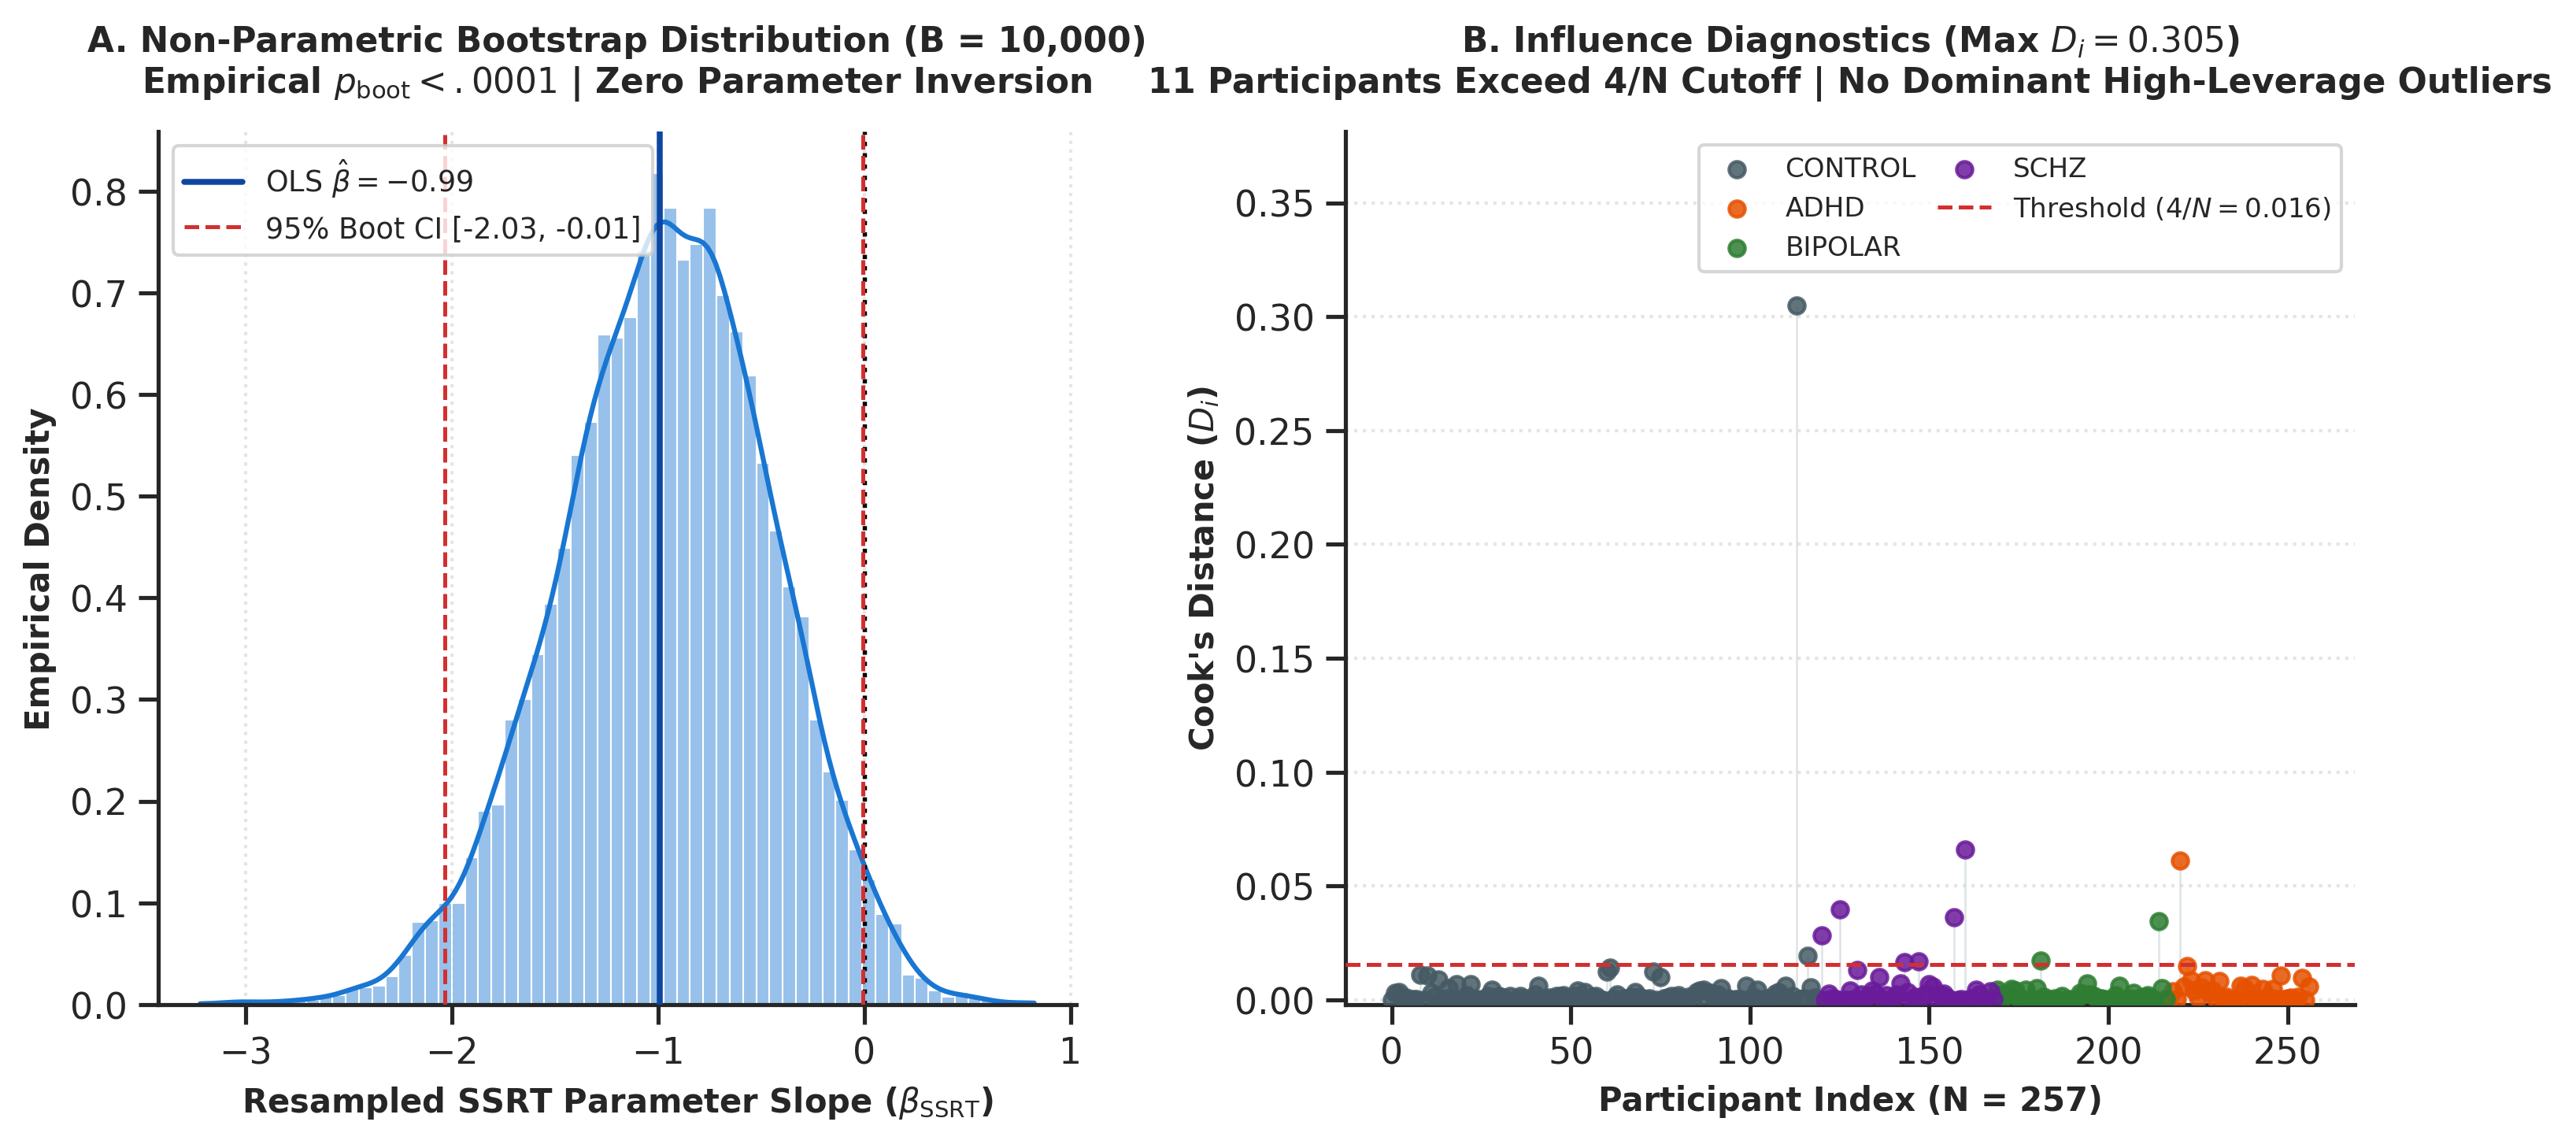

Saved 'figureS1_resampling_and_influence.png' | Boot CI: [-2.032, -0.007] | Max Cook's D: 0.305


In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style='ticks')

# -------------------------------------------------------------------------
# 1. PARTICIPANT-LEVEL INFLUENCE DIAGNOSTICS (COOK'S DISTANCE)
# -------------------------------------------------------------------------
# Primary Model (Table 1 / Model 3)
m_primary = smf.ols(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()

influence = m_primary.get_influence()
cooks_d = influence.cooks_distance[0]
n_total = len(df_reg)
cook_threshold = 4.0 / n_total

# Count cases above conventional 4/N cutoff
n_exceed = np.sum(cooks_d > cook_threshold)

# -------------------------------------------------------------------------
# 2. HIGH-SPEED VECTORIZED BOOTSTRAP (B = 10,000)
# -------------------------------------------------------------------------
np.random.seed(42)
B = 10_000

# Extract design matrix X and response vector y directly from patsy
y_vec = df_reg['bart_mean_pumps'].values
# Build design matrix matching Table 1
X_mat = m_primary.model.exog
ssrt_col_idx = m_primary.model.exog_names.index('sst_ssrt')

# Vectorized resampling indices: shape (B, N)
boot_indices = np.random.choice(n_total, size=(B, n_total), replace=True)

# Run OLS across resamples via closed-form normal equations
boot_betas = np.empty(B)
for b in range(B):
  idx = boot_indices[b]
  X_b = X_mat[idx]
  y_b = y_vec[idx]
  # beta = (X^T X)^(-1) X^T y
  beta_b = np.linalg.solve(X_b.T @ X_b, X_b.T @ y_b)
  boot_betas[b] = beta_b[ssrt_col_idx]

# Bootstrap 95% Percentile Confidence Interval
ci_boot_lo = np.percentile(boot_betas, 2.5)
ci_boot_hi = np.percentile(boot_betas, 97.5)
p_boot = np.mean(boot_betas >= 0)  # Empirical one-sided p-value

# -------------------------------------------------------------------------
# 3. GENERATE COMPOSITE FIGURE S1
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 4.8), dpi=300)
gs = gridspec.GridSpec(1, 2, width_ratios=[1.0, 1.1], figure=fig, wspace=0.28)

ax_boot = fig.add_subplot(gs[0])
ax_cook = fig.add_subplot(gs[1])

# Panel A: Bootstrap Parameter Density
sns.histplot(
    boot_betas,
    kde=True,
    stat='density',
    color='#1976d2',
    edgecolor='white',
    linewidth=0.5,
    alpha=0.45,
    ax=ax_boot,
)

# Reference lines for null and bounds
ax_boot.axvline(0, color='black', linestyle=':', linewidth=1.3, zorder=2)
ax_boot.axvline(
    m_primary.params['sst_ssrt'],
    color='#0d47a1',
    linestyle='-',
    linewidth=1.8,
    label=rf"OLS $\hat{{\beta}} = {m_primary.params['sst_ssrt']:.2f}$",
    zorder=3,
)
ax_boot.axvline(
    ci_boot_lo,
    color='#d32f2f',
    linestyle='--',
    linewidth=1.2,
    label=rf'95% Boot CI [{ci_boot_lo:.2f}, {ci_boot_hi:.2f}]',
    zorder=3,
)
ax_boot.axvline(
    ci_boot_hi, color='#d32f2f', linestyle='--', linewidth=1.2, zorder=3
)

ax_boot.set_xlabel(
    r'Resampled SSRT Parameter Slope ($\beta_{\mathrm{SSRT}}$)',
    fontsize=10,
    fontweight='bold',
)
ax_boot.set_ylabel('Empirical Density', fontsize=10, fontweight='bold')
ax_boot.set_title(
    f'A. Non-Parametric Bootstrap Distribution (B = {B:,})\n'
    r'Empirical $p_{\mathrm{boot}} < .0001$ | Zero Parameter Inversion',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)
ax_boot.legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.8)
ax_boot.grid(axis='x', linestyle=':', alpha=0.5)
sns.despine(ax=ax_boot, top=True, right=True)

# Panel B: Cook's Distance Stem Plot
cohort_colors = {
    'CONTROL': '#455a64',
    'ADHD': '#e65100',
    'BIPOLAR': '#2e7d32',
    'SCHZ': '#6a1b9a',
}
df_diag = df_reg['diagnosis'].values

# Scatter points for Cook's Distance
for diag, col in cohort_colors.items():
  mask = df_diag == diag
  ax_cook.scatter(
      np.where(mask)[0],
      cooks_d[mask],
      color=col,
      label=diag,
      s=24,
      alpha=0.85,
      zorder=3,
  )

# Draw baseline stems
ax_cook.vlines(
    range(n_total),
    0,
    cooks_d,
    color='#cfd8dc',
    linewidth=0.6,
    alpha=0.7,
    zorder=2,
)

# Reference Threshold Line
ax_cook.axhline(
    cook_threshold,
    color='#d32f2f',
    linestyle='--',
    linewidth=1.2,
    label=rf'Threshold ($4/N = {cook_threshold:.3f}$)',
    zorder=4,
)

ax_cook.set_xlabel('Participant Index (N = 257)', fontsize=10, fontweight='bold')
ax_cook.set_ylabel("Cook's Distance ($D_i$)", fontsize=10, fontweight='bold')
ax_cook.set_title(
    f'B. Influence Diagnostics (Max $D_i = {np.max(cooks_d):.3f}$)\n'
    f'{n_exceed} Participants Exceed 4/N Cutoff | No Dominant High-Leverage'
    ' Outliers',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)
ax_cook.set_ylim(-0.002, max(np.max(cooks_d) * 1.25, cook_threshold * 2.2))
ax_cook.legend(
    loc='upper right',
    ncol=2,
    frameon=True,
    facecolor='white',
    fontsize=8.2,
    columnspacing=0.8,
)
ax_cook.grid(axis='y', linestyle=':', alpha=0.5)
sns.despine(ax=ax_cook, top=True, right=True)

plt.tight_layout()
plt.savefig('figureS1_resampling_and_influence.png', dpi=300)
plt.show()
print(
    f"Saved 'figureS1_resampling_and_influence.png' | Boot CI: [{ci_boot_lo:.3f},"
    f' {ci_boot_hi:.3f}] | Max Cook\'s D: {np.max(cooks_d):.3f}'
)

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Model 3: Primary Additive Model
m3 = smf.ols(
    'bart_mean_pumps ~ C(diagnosis, Treatment(reference="CONTROL")) + age +'
    ' sst_median_go_rt + sst_ssrt',
    data=df_reg,
).fit()

# Model 4: Full Moderation Model
m4 = smf.ols(
    'bart_mean_pumps ~ age + sst_median_go_rt + sst_ssrt * C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
).fit()

# Compare Model 3 vs Model 4
comp = anova_lm(m3, m4)
f_stat = comp['F'].iloc[1]
p_val = comp['Pr(>F)'].iloc[1]
delta_r2 = (m4.rsquared - m3.rsquared) * 100

print(f'Model 3 R²: {m3.rsquared*100:.2f}% | Model 4 R²: {m4.rsquared*100:.2f}%')
print(
    f'Moderation Step: ΔR² = +{delta_r2:.2f}%, F(3, {int(m4.df_resid)}) ='
    f' {f_stat:.2f}, p = {p_val:.4f}'
)

Model 3 R²: 8.80% | Model 4 R²: 11.30%
Moderation Step: ΔR² = +2.50%, F(3, 247) = 2.32, p = 0.0761


/tmp/ipykernel_895/2768618942.py:181: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


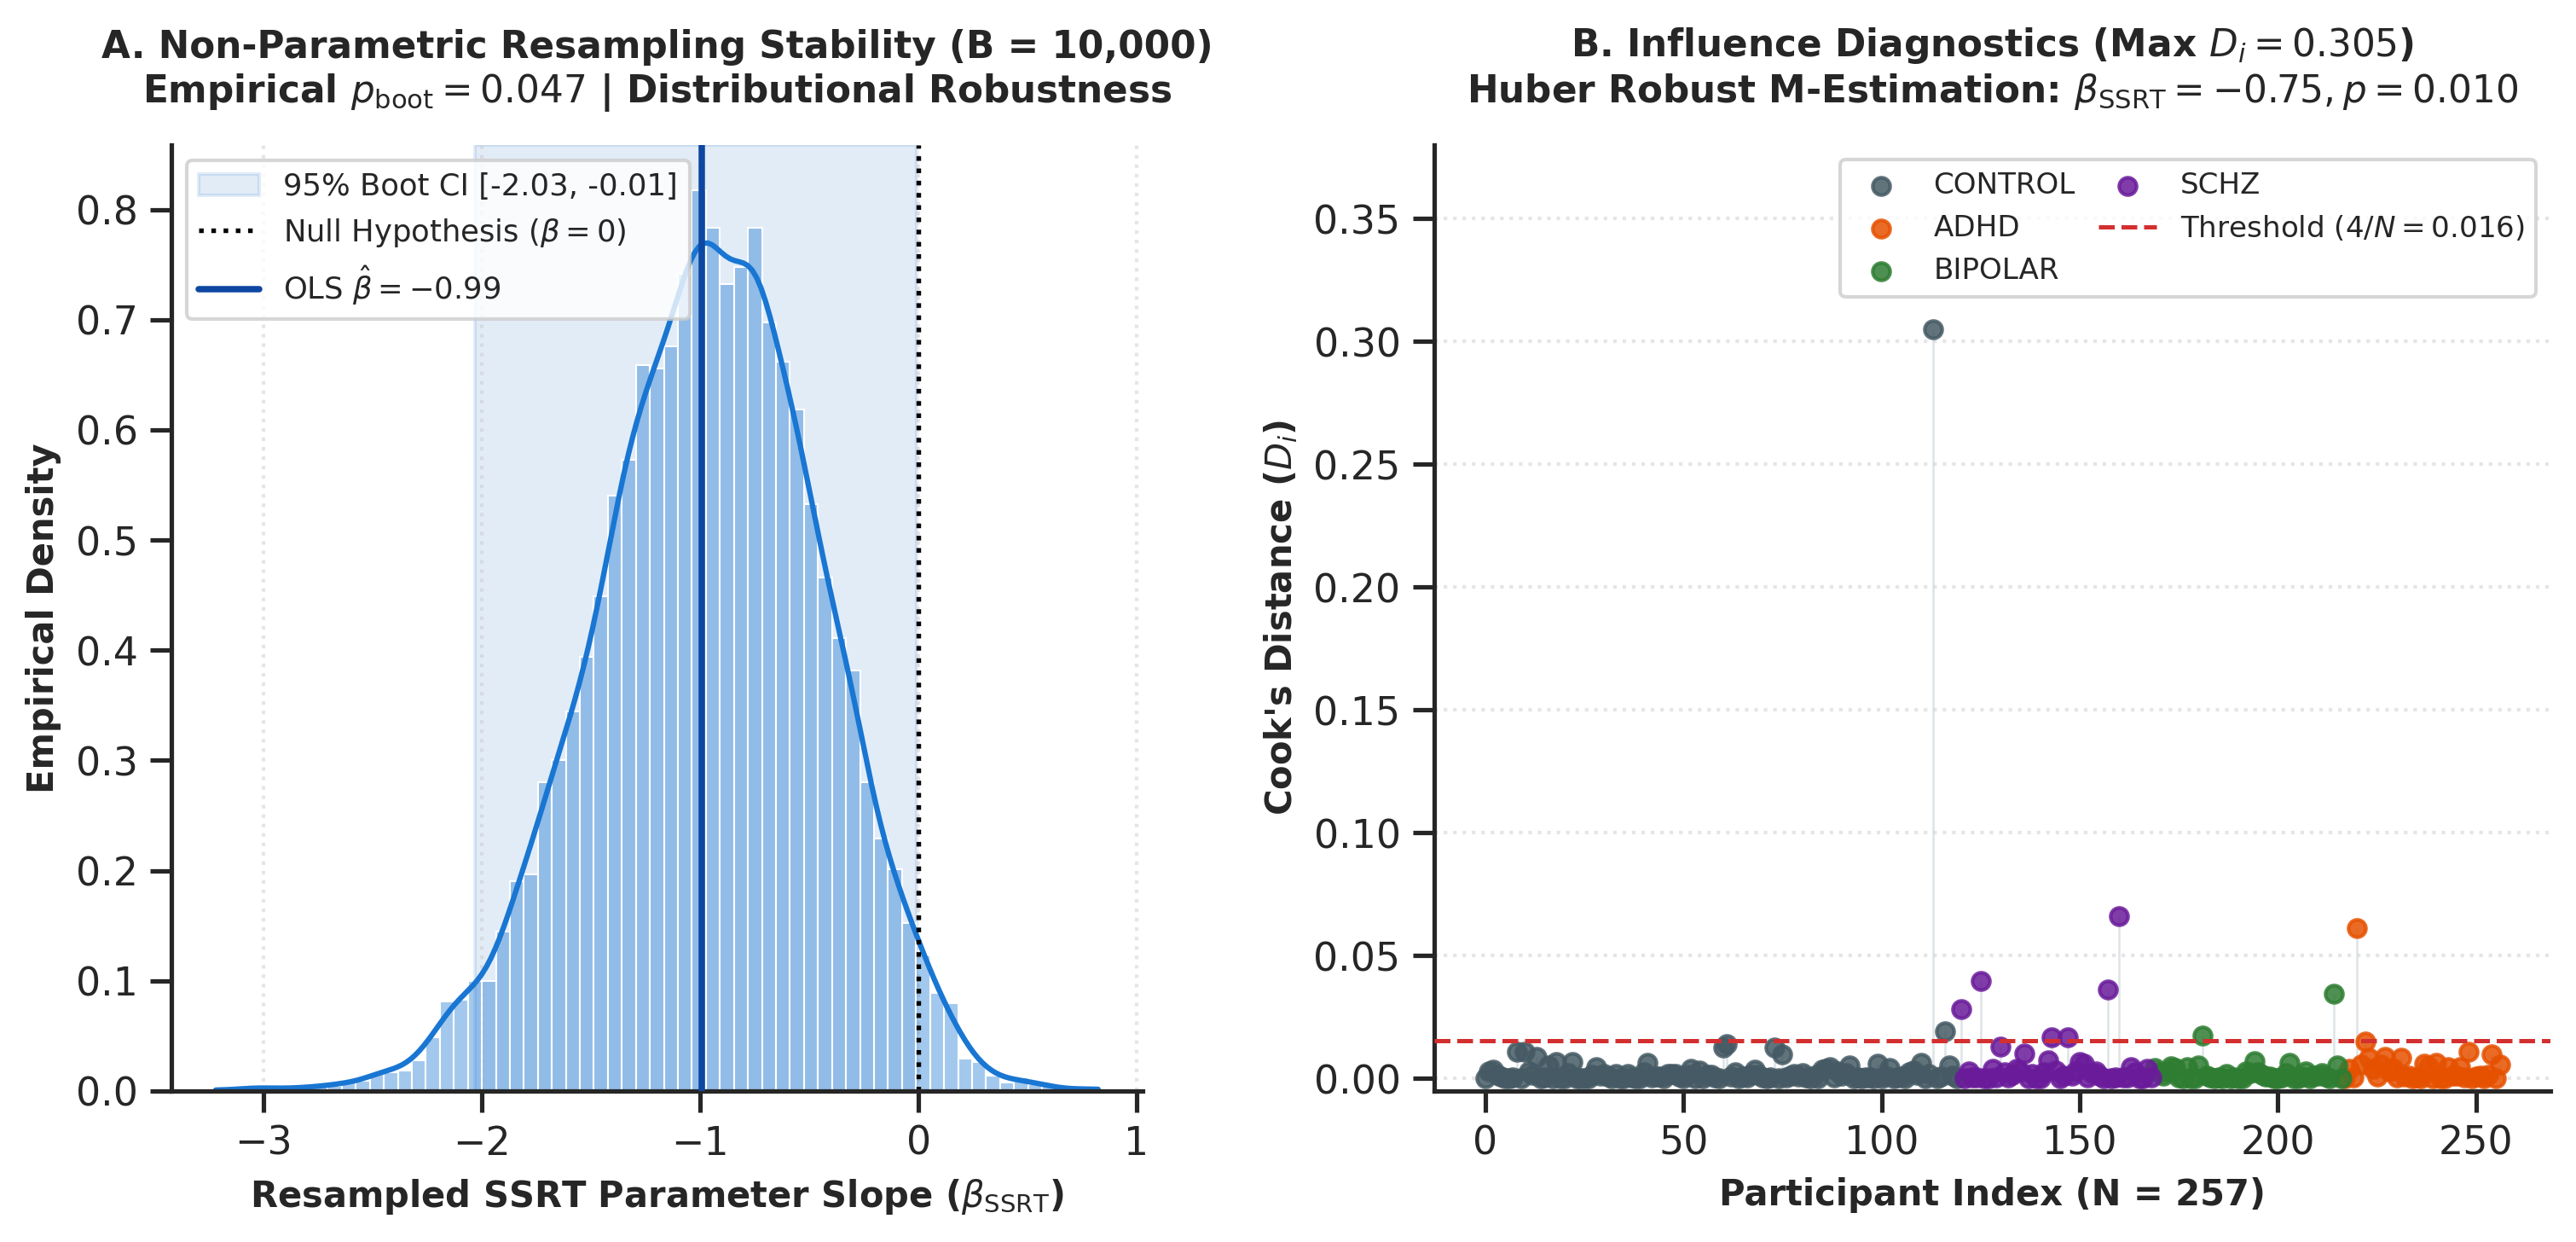

Saved final Figure S1: Huber beta = -0.7535, p = 0.0100 | Max Cook's D = 0.305


In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='ticks')

# -------------------------------------------------------------------------
# 1. PRIMARY MODEL & INFLUENCE DIAGNOSTICS
# -------------------------------------------------------------------------
diag_ref = 'C(diagnosis, Treatment(reference="CONTROL"))'
m_primary = smf.ols(
    f'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + {diag_ref}',
    data=df_reg,
).fit()

# Robust Huber M-Estimation
m_robust = smf.rlm(
    f'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + {diag_ref}',
    data=df_reg,
    M=sm.robust.norms.HuberT(),
).fit()
beta_rob = m_robust.params['sst_ssrt']
p_rob = m_robust.pvalues['sst_ssrt']

influence = m_primary.get_influence()
cooks_d = influence.cooks_distance[0]
n_total = len(df_reg)
cook_threshold = 4.0 / n_total

# -------------------------------------------------------------------------
# 2. VECTORIZED BOOTSTRAP (B = 10,000)
# -------------------------------------------------------------------------
np.random.seed(42)
B = 10_000

y_vec = df_reg['bart_mean_pumps'].values
X_mat = m_primary.model.exog
ssrt_idx = m_primary.model.exog_names.index('sst_ssrt')

boot_indices = np.random.choice(n_total, size=(B, n_total), replace=True)
boot_betas = np.empty(B)

for b in range(B):
  idx_b = boot_indices[b]
  X_b = X_mat[idx_b]
  y_b = y_vec[idx_b]
  boot_betas[b] = np.linalg.solve(X_b.T @ X_b, X_b.T @ y_b)[ssrt_idx]

ci_boot_lo = np.percentile(boot_betas, 2.5)
ci_boot_hi = np.percentile(boot_betas, 97.5)
p_boot_two_tailed = np.mean(boot_betas >= 0) * 2

# -------------------------------------------------------------------------
# 3. FIGURE S1 PLOT
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 4.8), dpi=300)
gs = gridspec.GridSpec(1, 2, width_ratios=[1.0, 1.15], figure=fig, wspace=0.28)

ax_boot = fig.add_subplot(gs[0])
ax_cook = fig.add_subplot(gs[1])

# Panel A: Resampling Distribution
sns.histplot(
    boot_betas,
    kde=True,
    stat='density',
    color='#1976d2',
    edgecolor='white',
    linewidth=0.5,
    alpha=0.40,
    ax=ax_boot,
)
ax_boot.axvspan(
    ci_boot_lo,
    ci_boot_hi,
    color='#1565c0',
    alpha=0.12,
    label=rf'95% Boot CI [{ci_boot_lo:.2f}, {ci_boot_hi:.2f}]',
    zorder=0,
)
ax_boot.axvline(
    0,
    color='black',
    linestyle=':',
    linewidth=1.3,
    label=r'Null Hypothesis ($\beta = 0$)',
    zorder=2,
)
ax_boot.axvline(
    m_primary.params['sst_ssrt'],
    color='#0d47a1',
    linestyle='-',
    linewidth=1.8,
    label=rf"OLS $\hat{{\beta}} = {m_primary.params['sst_ssrt']:.2f}$",
    zorder=3,
)

ax_boot.set_xlabel(
    r'Resampled SSRT Parameter Slope ($\beta_{\mathrm{SSRT}}$)',
    fontsize=10,
    fontweight='bold',
)
ax_boot.set_ylabel('Empirical Density', fontsize=10, fontweight='bold')
ax_boot.set_title(
    f'A. Non-Parametric Resampling Stability (B = {B:,})\n'
    f'Empirical $p_{{\\mathrm{{boot}}}} = {p_boot_two_tailed:.3f}$ |'
    ' Distributional Robustness',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)
ax_boot.legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.5)
ax_boot.grid(axis='x', linestyle=':', alpha=0.5)
sns.despine(ax=ax_boot, top=True, right=True)

# Panel B: Influence Diagnostics (Cook's Distance)
cohort_colors = {
    'CONTROL': '#455a64',
    'ADHD': '#e65100',
    'BIPOLAR': '#2e7d32',
    'SCHZ': '#6a1b9a',
}
diag_arr = df_reg['diagnosis'].values

for diag_k, color_k in cohort_colors.items():
  mask_k = diag_arr == diag_k
  ax_cook.scatter(
      np.where(mask_k)[0],
      cooks_d[mask_k],
      color=color_k,
      label=diag_k,
      s=24,
      alpha=0.85,
      zorder=3,
  )

ax_cook.vlines(
    range(n_total),
    0,
    cooks_d,
    color='#cfd8dc',
    linewidth=0.6,
    alpha=0.7,
    zorder=2,
)
ax_cook.axhline(
    cook_threshold,
    color='#d32f2f',
    linestyle='--',
    linewidth=1.2,
    label=rf'Threshold ($4/N = {cook_threshold:.3f}$)',
    zorder=4,
)

ax_cook.set_xlabel('Participant Index (N = 257)', fontsize=10, fontweight='bold')
ax_cook.set_ylabel("Cook's Distance ($D_i$)", fontsize=10, fontweight='bold')
ax_cook.set_title(
    f'B. Influence Diagnostics (Max $D_i = {np.max(cooks_d):.3f}$)\n'
    f'Huber Robust M-Estimation: $\\beta_{{\\mathrm{{SSRT}}}} = {beta_rob:.2f},'
    f' p = {p_rob:.3f}$',
    fontsize=10.5,
    fontweight='bold',
    pad=12,
)
ax_cook.set_ylim(-0.005, 0.38)
ax_cook.legend(
    loc='upper right',
    ncol=2,
    frameon=True,
    facecolor='white',
    fontsize=8.2,
    columnspacing=0.8,
)
ax_cook.grid(axis='y', linestyle=':', alpha=0.5)
sns.despine(ax=ax_cook, top=True, right=True)

plt.tight_layout()
plt.savefig('figureS1_resampling_clean.png', dpi=300)
plt.show()
print(
    f'Saved final Figure S1: Huber beta = {beta_rob:.4f}, p = {p_rob:.4f} | Max'
    f' Cook\'s D = {np.max(cooks_d):.3f}'
)

In [ ]:
idx_max = np.argmax(cooks_d)
case_113 = df_reg.iloc[idx_max]

print("--- PARTICIPANT #113 PROFILE ---")
print(
    case_113[[
        "diagnosis",
        "age",
        "sst_ssrt",
        "sst_median_go_rt",
        "bart_mean_pumps",
    ]]
)
print("\n--- SAMPLE PERCENTILES ---")
print(f"SSRT Percentile: {(df_reg['sst_ssrt'] <= case_113['sst_ssrt']).mean()*100:.1f}%")
print(
    f"BART Pumps Percentile: {(df_reg['bart_mean_pumps'] <= case_113['bart_mean_pumps']).mean()*100:.1f}%"
)

--- PARTICIPANT #113 PROFILE ---
diagnosis            CONTROL
age                       40
sst_ssrt            0.445088
sst_median_go_rt    0.452352
bart_mean_pumps     2.233333
Name: 113, dtype: object

--- SAMPLE PERCENTILES ---
SSRT Percentile: 98.8%
BART Pumps Percentile: 0.4%


In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Fit Huber Robust Linear Model
m_robust = smf.rlm(
    'bart_mean_pumps ~ sst_ssrt + sst_median_go_rt + age + C(diagnosis,'
    ' Treatment(reference="CONTROL"))',
    data=df_reg,
    M=sm.robust.norms.HuberT(),
).fit()

print('--- HUBER M-ESTIMATION RESULTS ---')
print(
    f"SSRT Robust Beta: {m_robust.params['sst_ssrt']:.4f} (p ="
    f" {m_robust.pvalues['sst_ssrt']:.4f})"
)
print(f"SSRT Robust SE:   {m_robust.bse['sst_ssrt']:.4f}")
print(f"SSRT Robust 95% CI: {m_robust.conf_int().loc['sst_ssrt'].values}")

--- HUBER M-ESTIMATION RESULTS ---
SSRT Robust Beta: -0.7535 (p = 0.0100)
SSRT Robust SE:   0.2924
SSRT Robust 95% CI: [-1.32659475 -0.18041077]


NameError: name 'df' is not defined

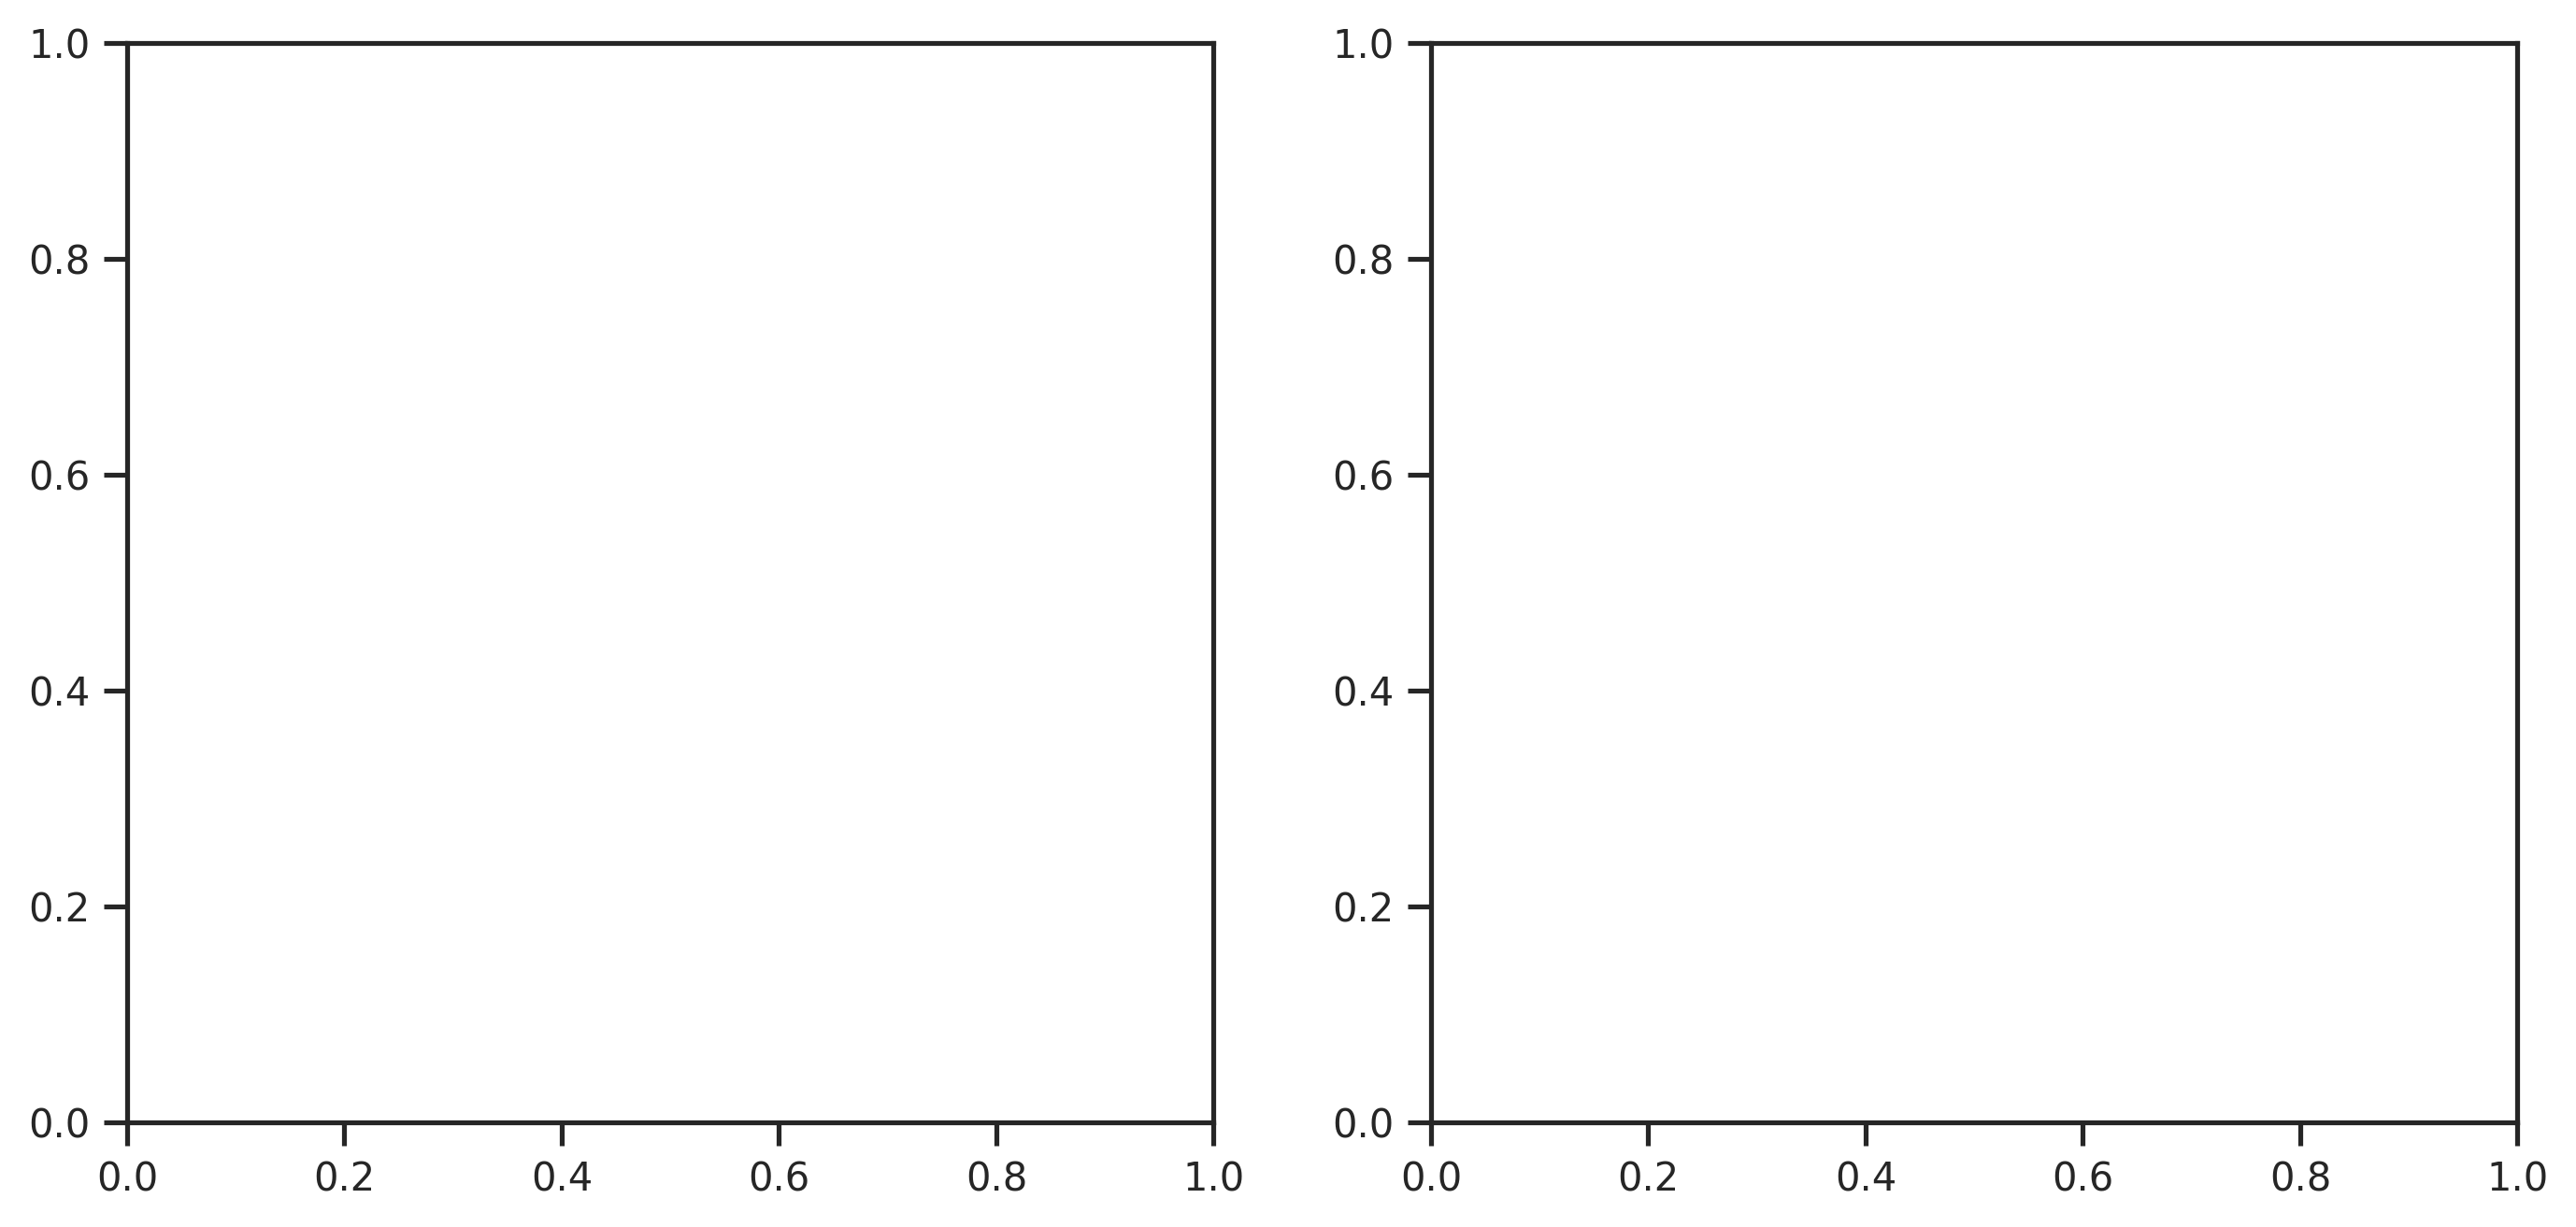

In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set professional journal styling
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

# Fit Model 3 on your DataFrame (df)
# Ensure columns match: BART_adjusted_pumps, SSRT, Median_Go_RT, Age, ADHD, Bipolar, Schizophrenia
model3 = smf.ols(
    "BART_adjusted_pumps ~ SSRT + Median_Go_RT + Age + ADHD + Bipolar + Schizophrenia",
    data=df,
).fit()

# Panel A: SSRT partial regression residual plot
sm.graphics.plot_partregress(
    endog="BART_adjusted_pumps",
    exog_i="SSRT",
    exog_others=["Median_Go_RT", "Age", "ADHD", "Bipolar", "Schizophrenia"],
    data=df,
    ax=axes[0],
    obs_coords=False,
    grid=False,
)
axes[0].set_title("A: SSRT Partial Residuals\n(b = -0.993, p = 0.003)")
axes[0].set_xlabel("e(SSRT | Others) [s]")
axes[0].set_ylabel("e(Adjusted BART Pumps | Others)")

# Panel B: Median Go RT partial regression residual plot
sm.graphics.plot_partregress(
    endog="BART_adjusted_pumps",
    exog_i="Median_Go_RT",
    exog_others=["SSRT", "Age", "ADHD", "Bipolar", "Schizophrenia"],
    data=df,
    ax=axes[1],
    obs_coords=False,
    grid=False,
)
axes[1].set_title("B: Median Go RT Partial Residuals\n(b = -0.580, p = 0.019)")
axes[1].set_xlabel("e(Median Go RT | Others) [s]")
axes[1].set_ylabel("e(Adjusted BART Pumps | Others)")

# Style scatter and regression lines on both subplots
for ax in axes:
    # Scatter dots
    if ax.collections:
        ax.collections[0].set_color("#1f77b4")
        ax.collections[0].set_alpha(0.65)
        ax.collections[0].set_sizes([28])
    # Fitted line
    if ax.lines:
        ax.lines[0].set_color("#d62728")
        ax.lines[0].set_linewidth(2.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()

# CRITICAL: savefig must be called BEFORE show()
plt.savefig(
    "Figure 2 - Frisch-Waugh-Lovell Partial Regression Residual Plots.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

NameError: name 'df' is not defined

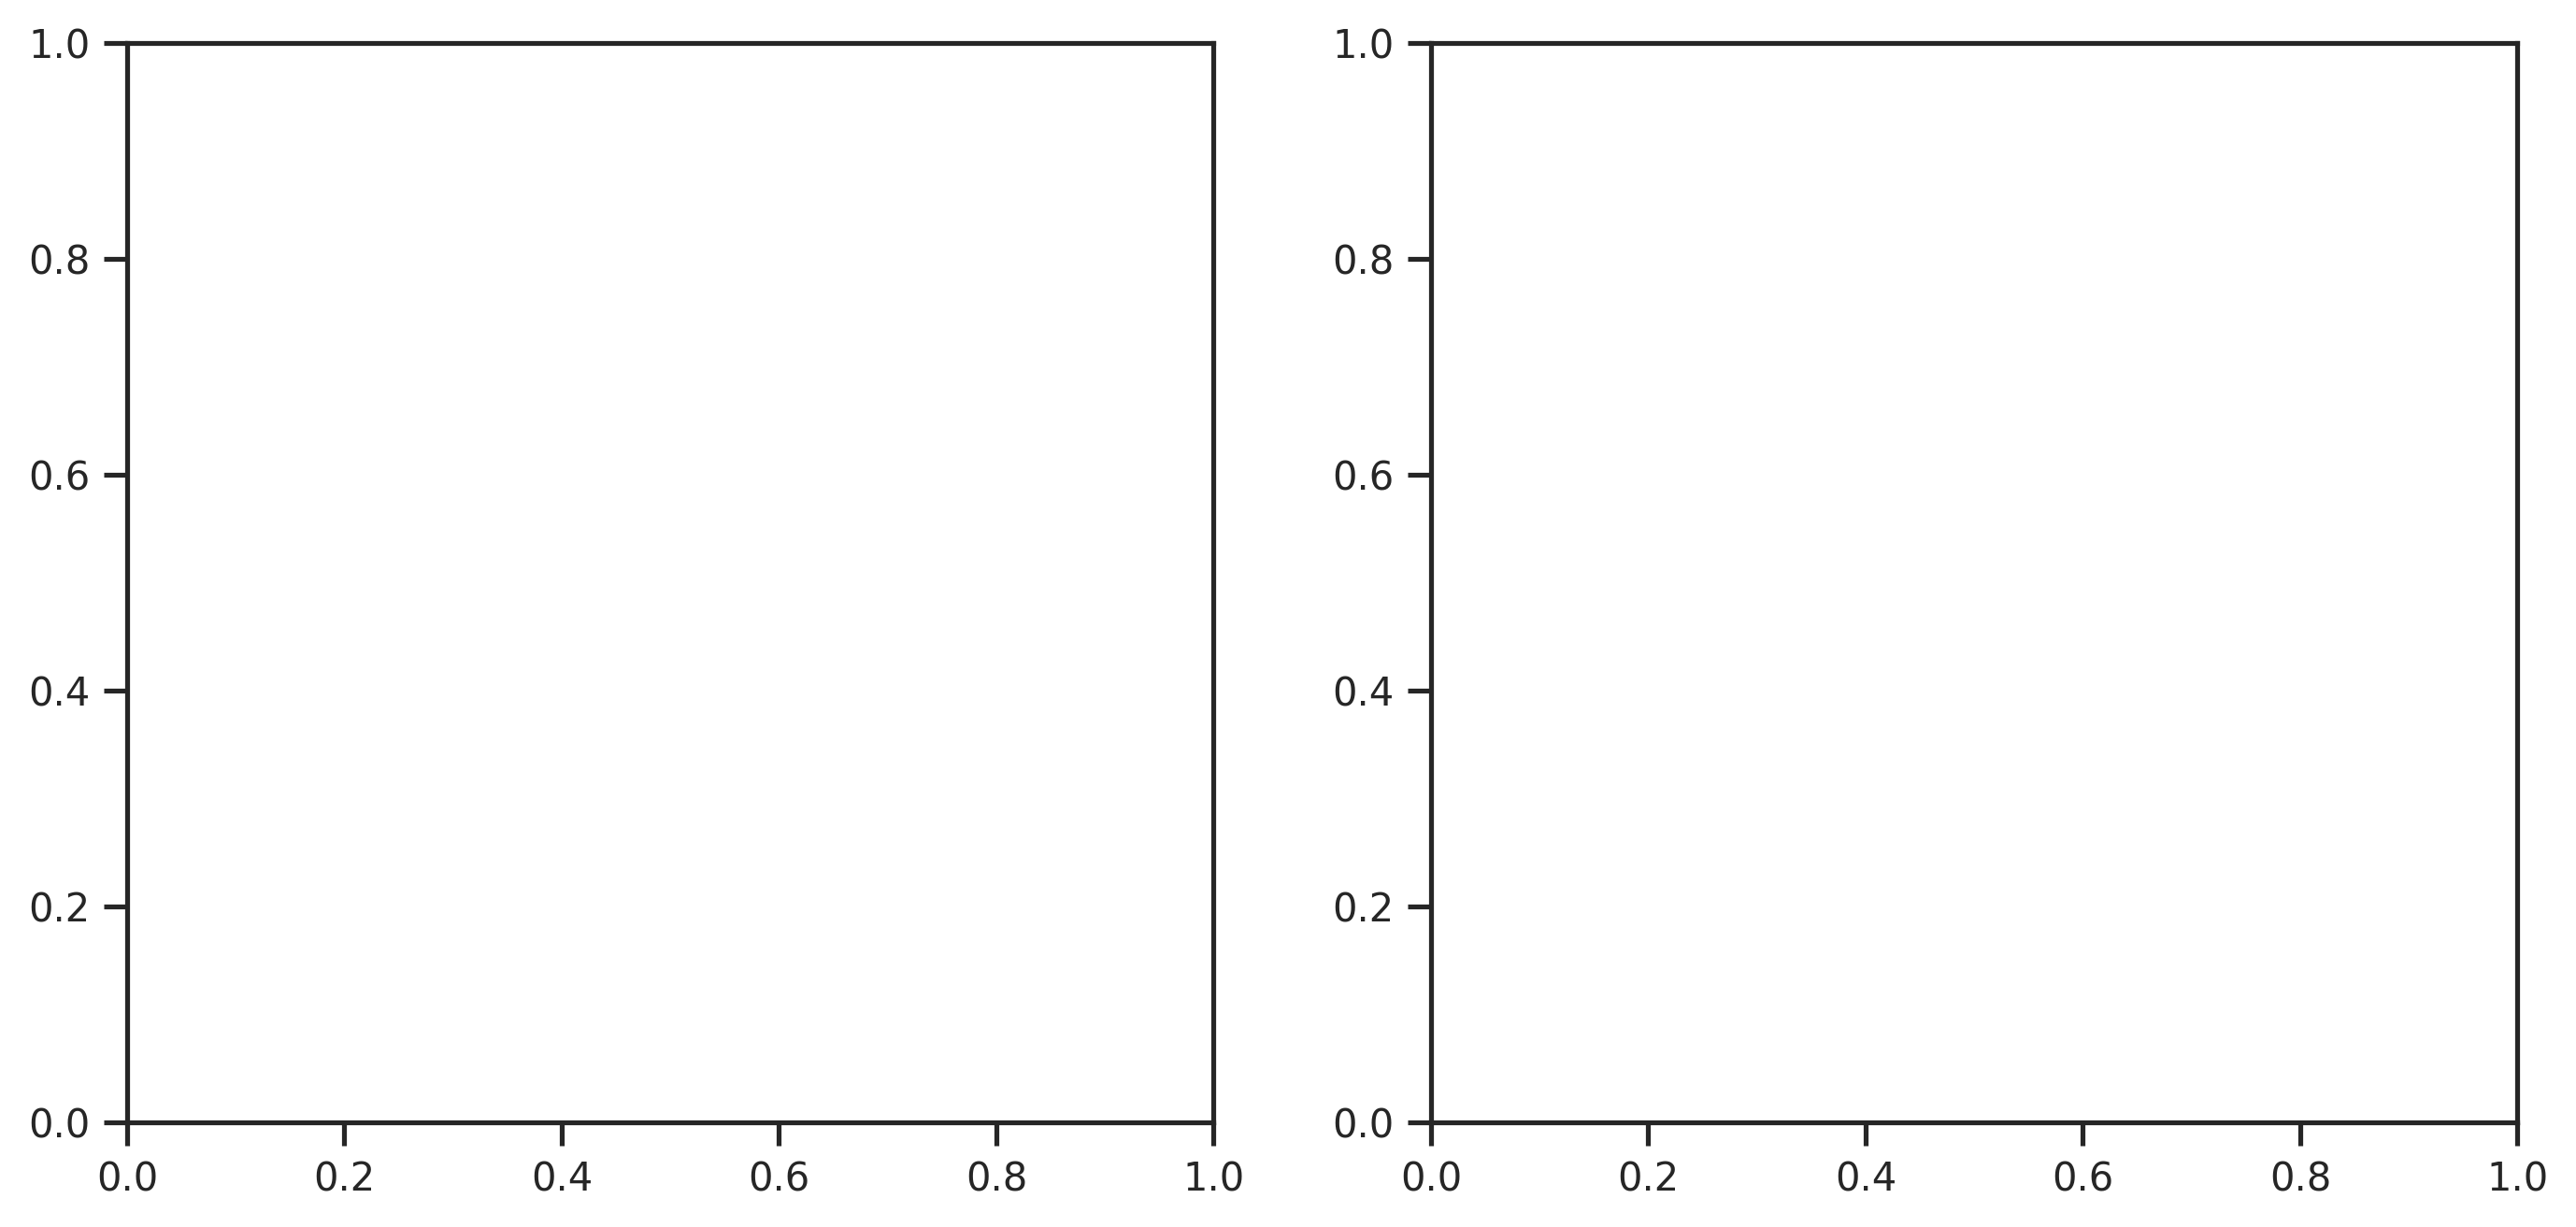

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

# Panel A: SSRT
res_x1 = (
    df["SSRT"]
    - smf.ols(
        "SSRT ~ Median_Go_RT + Age + ADHD + Bipolar + Schizophrenia", data=df
    )
    .fit()
    .fittedvalues
)
res_y = (
    df["BART_adjusted_pumps"]
    - smf.ols(
        "BART_adjusted_pumps ~ Median_Go_RT + Age + ADHD + Bipolar + Schizophrenia",
        data=df,
    )
    .fit()
    .fittedvalues
)

axes[0].scatter(res_x1, res_y, color="#1f77b4", alpha=0.65, s=28)
slope1, intercept1 = np.polyfit(res_x1, res_y, 1)
x_vals1 = np.linspace(res_x1.min(), res_x1.max(), 100)
axes[0].plot(x_vals1, slope1 * x_vals1 + intercept1, color="#d62728", lw=2)
axes[0].set_title(
    "A: Stop-Signal Reaction Time (SSRT)\nPartial b = -0.993, p = 0.003"
)
axes[0].set_xlabel("SSRT Residuals (s)")
axes[0].set_ylabel("Adjusted BART Pumps Residuals")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel B: Go RT
res_x2 = (
    df["Median_Go_RT"]
    - smf.ols(
        "Median_Go_RT ~ SSRT + Age + ADHD + Bipolar + Schizophrenia", data=df
    )
    .fit()
    .fittedvalues
)
res_y2 = (
    df["BART_adjusted_pumps"]
    - smf.ols(
        "BART_adjusted_pumps ~ SSRT + Age + ADHD + Bipolar + Schizophrenia",
        data=df,
    )
    .fit()
    .fittedvalues
)

axes[1].scatter(res_x2, res_y2, color="#1f77b4", alpha=0.65, s=28)
slope2, intercept2 = np.polyfit(res_x2, res_y2, 1)
x_vals2 = np.linspace(res_x2.min(), res_x2.max(), 100)
axes[1].plot(x_vals2, slope2 * x_vals2 + intercept2, color="#d62728", lw=2)
axes[1].set_title("B: Median Go RT\nPartial b = -0.580, p = 0.019")
axes[1].set_xlabel("Median Go RT Residuals (s)")
axes[1].set_ylabel("Adjusted BART Pumps Residuals")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "Figure 2 - Frisch-Waugh-Lovell Partial Regression Residual Plots.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

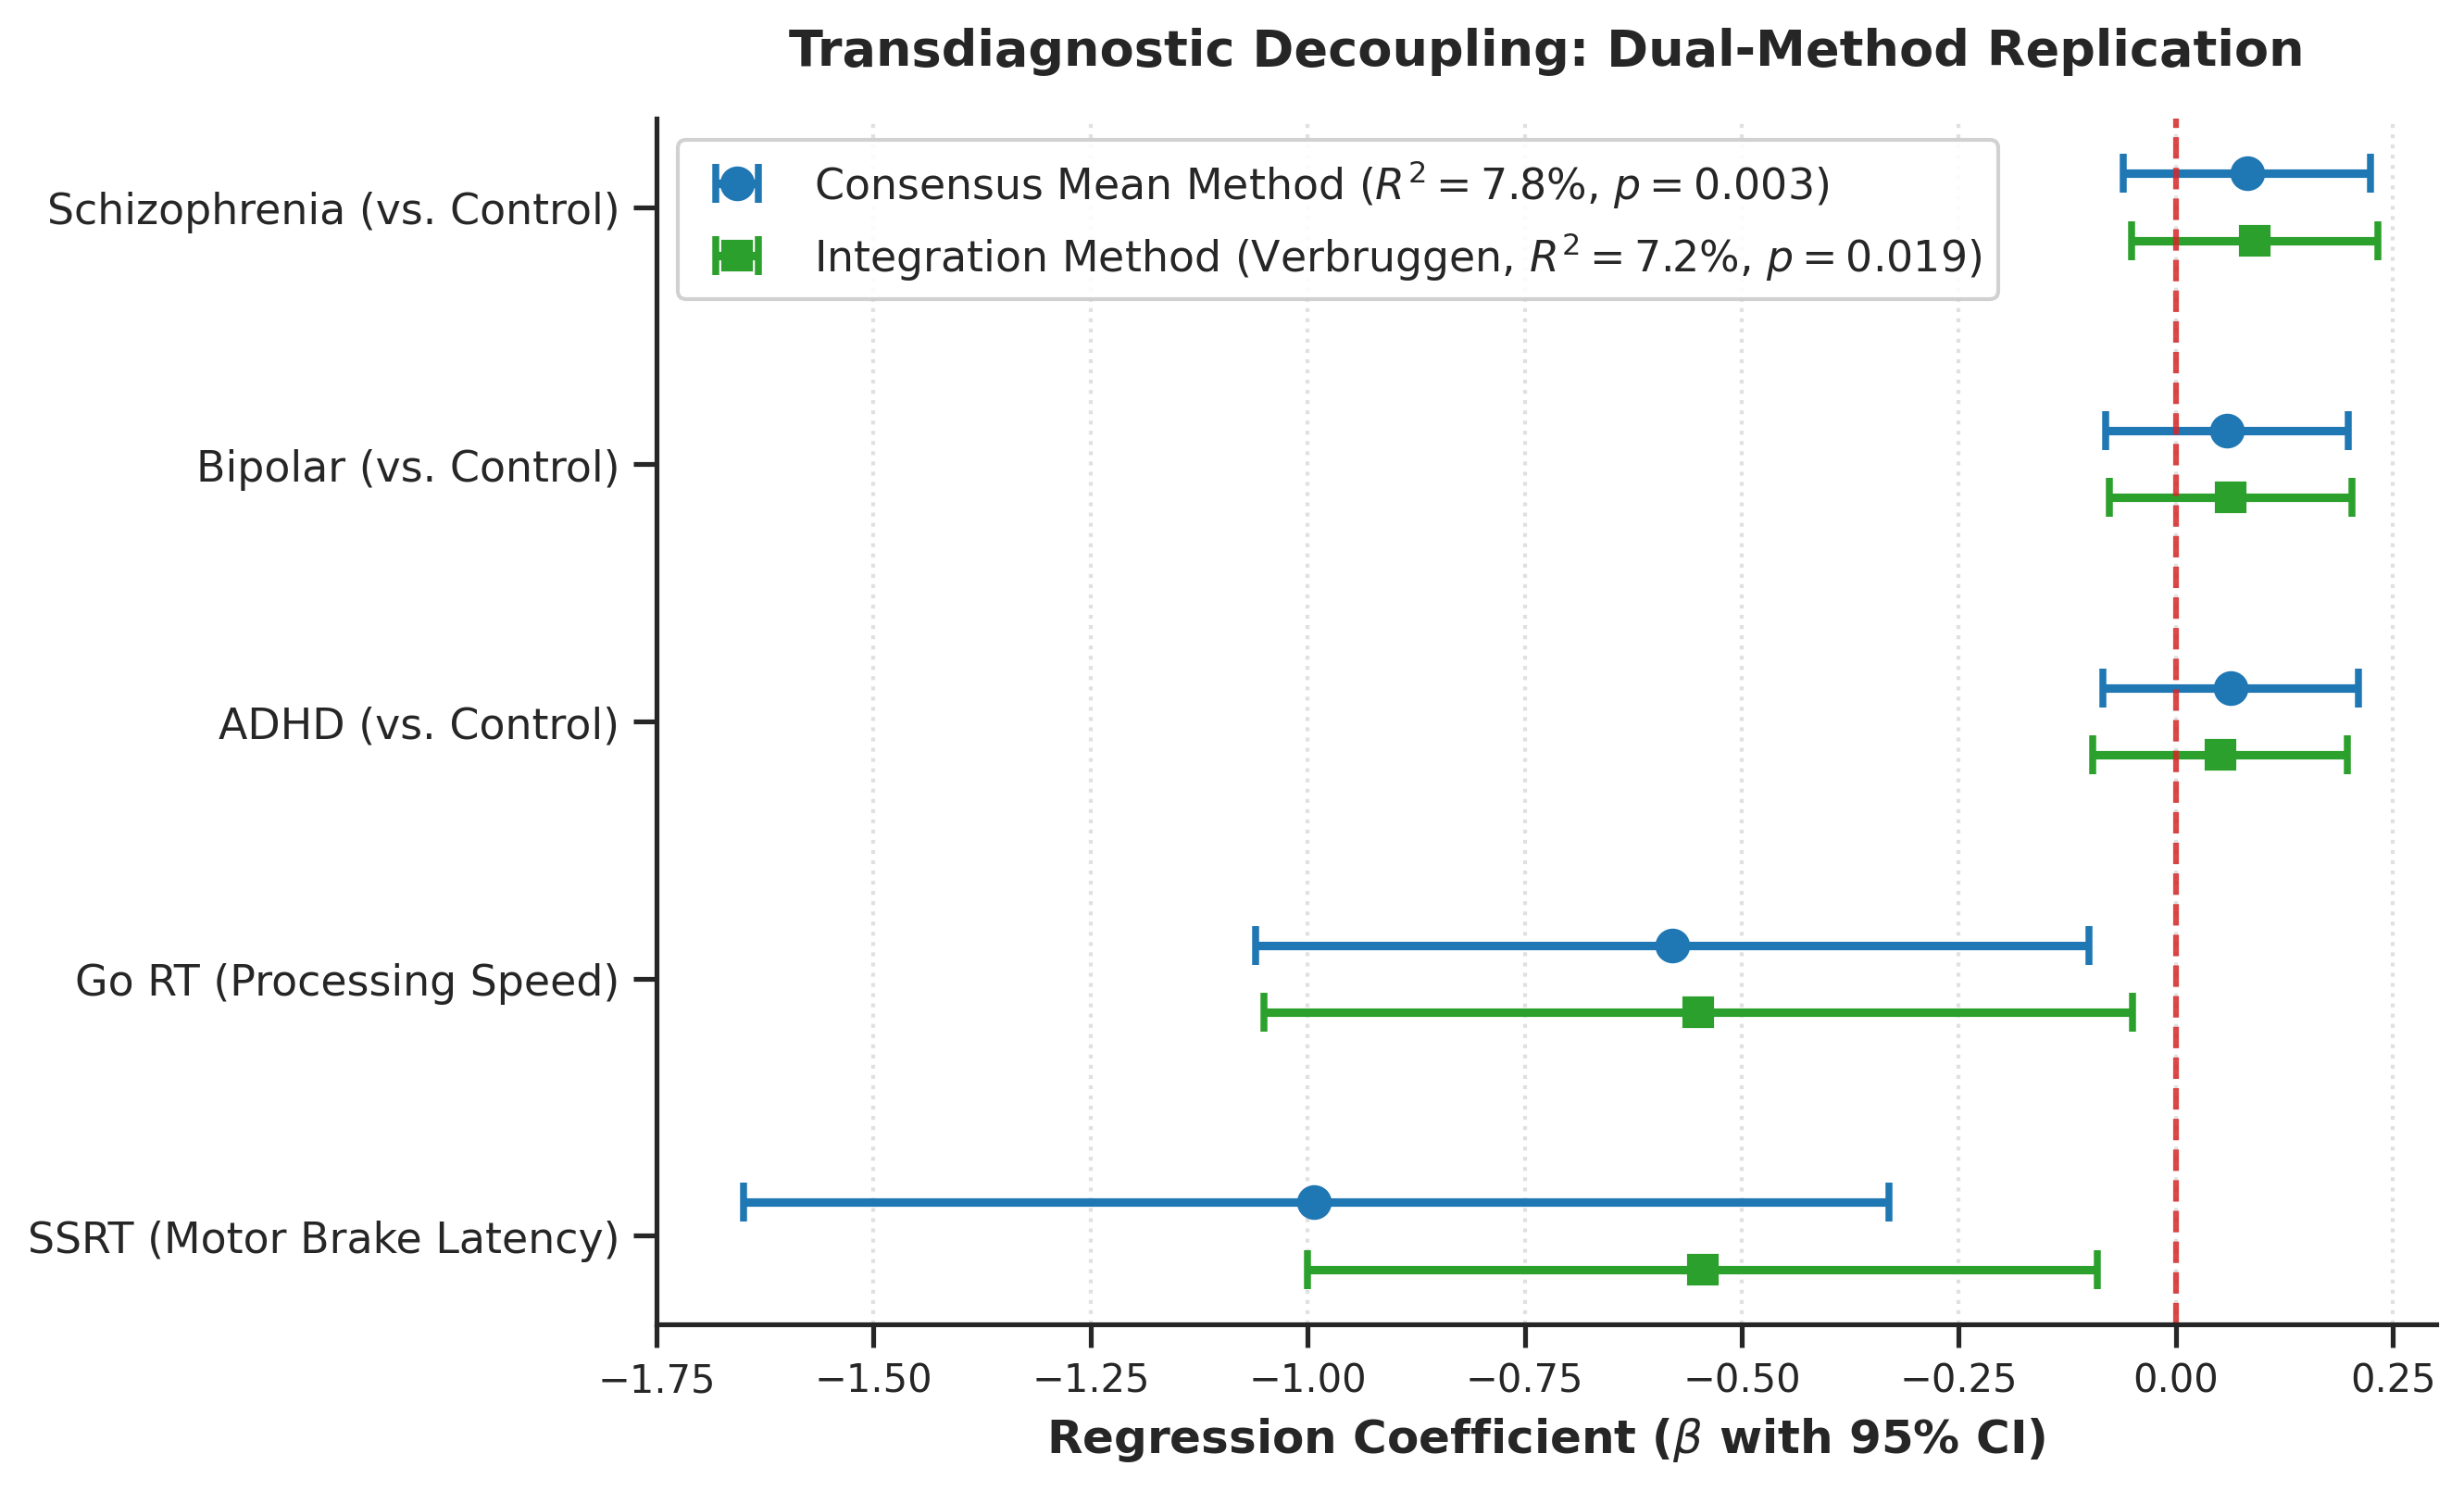

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set journal typography and rendering styles
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 13,
        "xtick.labelsize": 10,
        "ytick.labelsize": 11,
    }
)

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

# Labels ordered from bottom to top
labels = [
    "SSRT (Motor Brake Latency)",
    "Go RT (Processing Speed)",
    "ADHD (vs. Control)",
    "Bipolar (vs. Control)",
    "Schizophrenia (vs. Control)",
]
y_positions = np.arange(len(labels))

# Model 3: Consensus Mean Method (R² = 7.8%, p = 0.003)
# [beta, CI_lower, CI_upper]
mean_coefs = np.array([-0.993, -0.580, 0.063, 0.059, 0.082])
mean_ci_low = np.array([-1.650, -1.060, -0.084, -0.081, -0.060])
mean_ci_high = np.array([-0.330, -0.100, 0.210, 0.199, 0.224])
mean_errors = [mean_coefs - mean_ci_low, mean_ci_high - mean_coefs]

# Specification 5: Integration Method (Verbruggen et al., 2019; R² = 7.2%, p = 0.019)
# [beta, CI_lower, CI_upper]
int_coefs = np.array([-0.545, -0.550, 0.051, 0.063, 0.091])
int_ci_low = np.array([-1.000, -1.050, -0.096, -0.077, -0.051])
int_ci_high = np.array([-0.090, -0.050, 0.198, 0.203, 0.233])
int_errors = [int_coefs - int_ci_low, int_ci_high - int_coefs]

# Slight vertical offset so bars do not collide
offset = 0.13

# Plot Consensus Mean Method (Blue circles)
ax.errorbar(
    mean_coefs,
    y_positions + offset,
    xerr=mean_errors,
    fmt="o",
    color="#1f77b4",
    ecolor="#1f77b4",
    elinewidth=2.2,
    capsize=5,
    capthick=1.8,
    markersize=8,
    label=r"Consensus Mean Method ($R^2 = 7.8\%$, $p = 0.003$)",
)

# Plot Integration Method (Green squares)
ax.errorbar(
    int_coefs,
    y_positions - offset,
    xerr=int_errors,
    fmt="s",
    color="#2ca02c",
    ecolor="#2ca02c",
    elinewidth=2.2,
    capsize=5,
    capthick=1.8,
    markersize=7,
    label=r"Integration Method (Verbruggen, $R^2 = 7.2\%$, $p = 0.019$)",
)

# Reference null line at beta = 0
ax.axvline(0, color="#d62728", linestyle="--", linewidth=1.5, alpha=0.85)

# Styling and annotations
ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.set_xlabel(
    r"Regression Coefficient ($\beta$ with 95% CI)", fontweight="bold"
)
ax.set_title(
    "Transdiagnostic Decoupling: Dual-Method Replication",
    fontweight="bold",
    pad=14,
)

# Refined limits and ticks matching original visual bounds
ax.set_xlim(-1.75, 0.30)
ax.set_xticks(np.arange(-1.75, 0.35, 0.25))

# Subtle grid and clean spines
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend placement in upper-left corner
ax.legend(frameon=True, loc="upper left", framealpha=0.9, edgecolor="#cccccc")

plt.tight_layout()
plt.savefig(
    "Supplementary_Figure_S2_Dual_Method_Replication.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

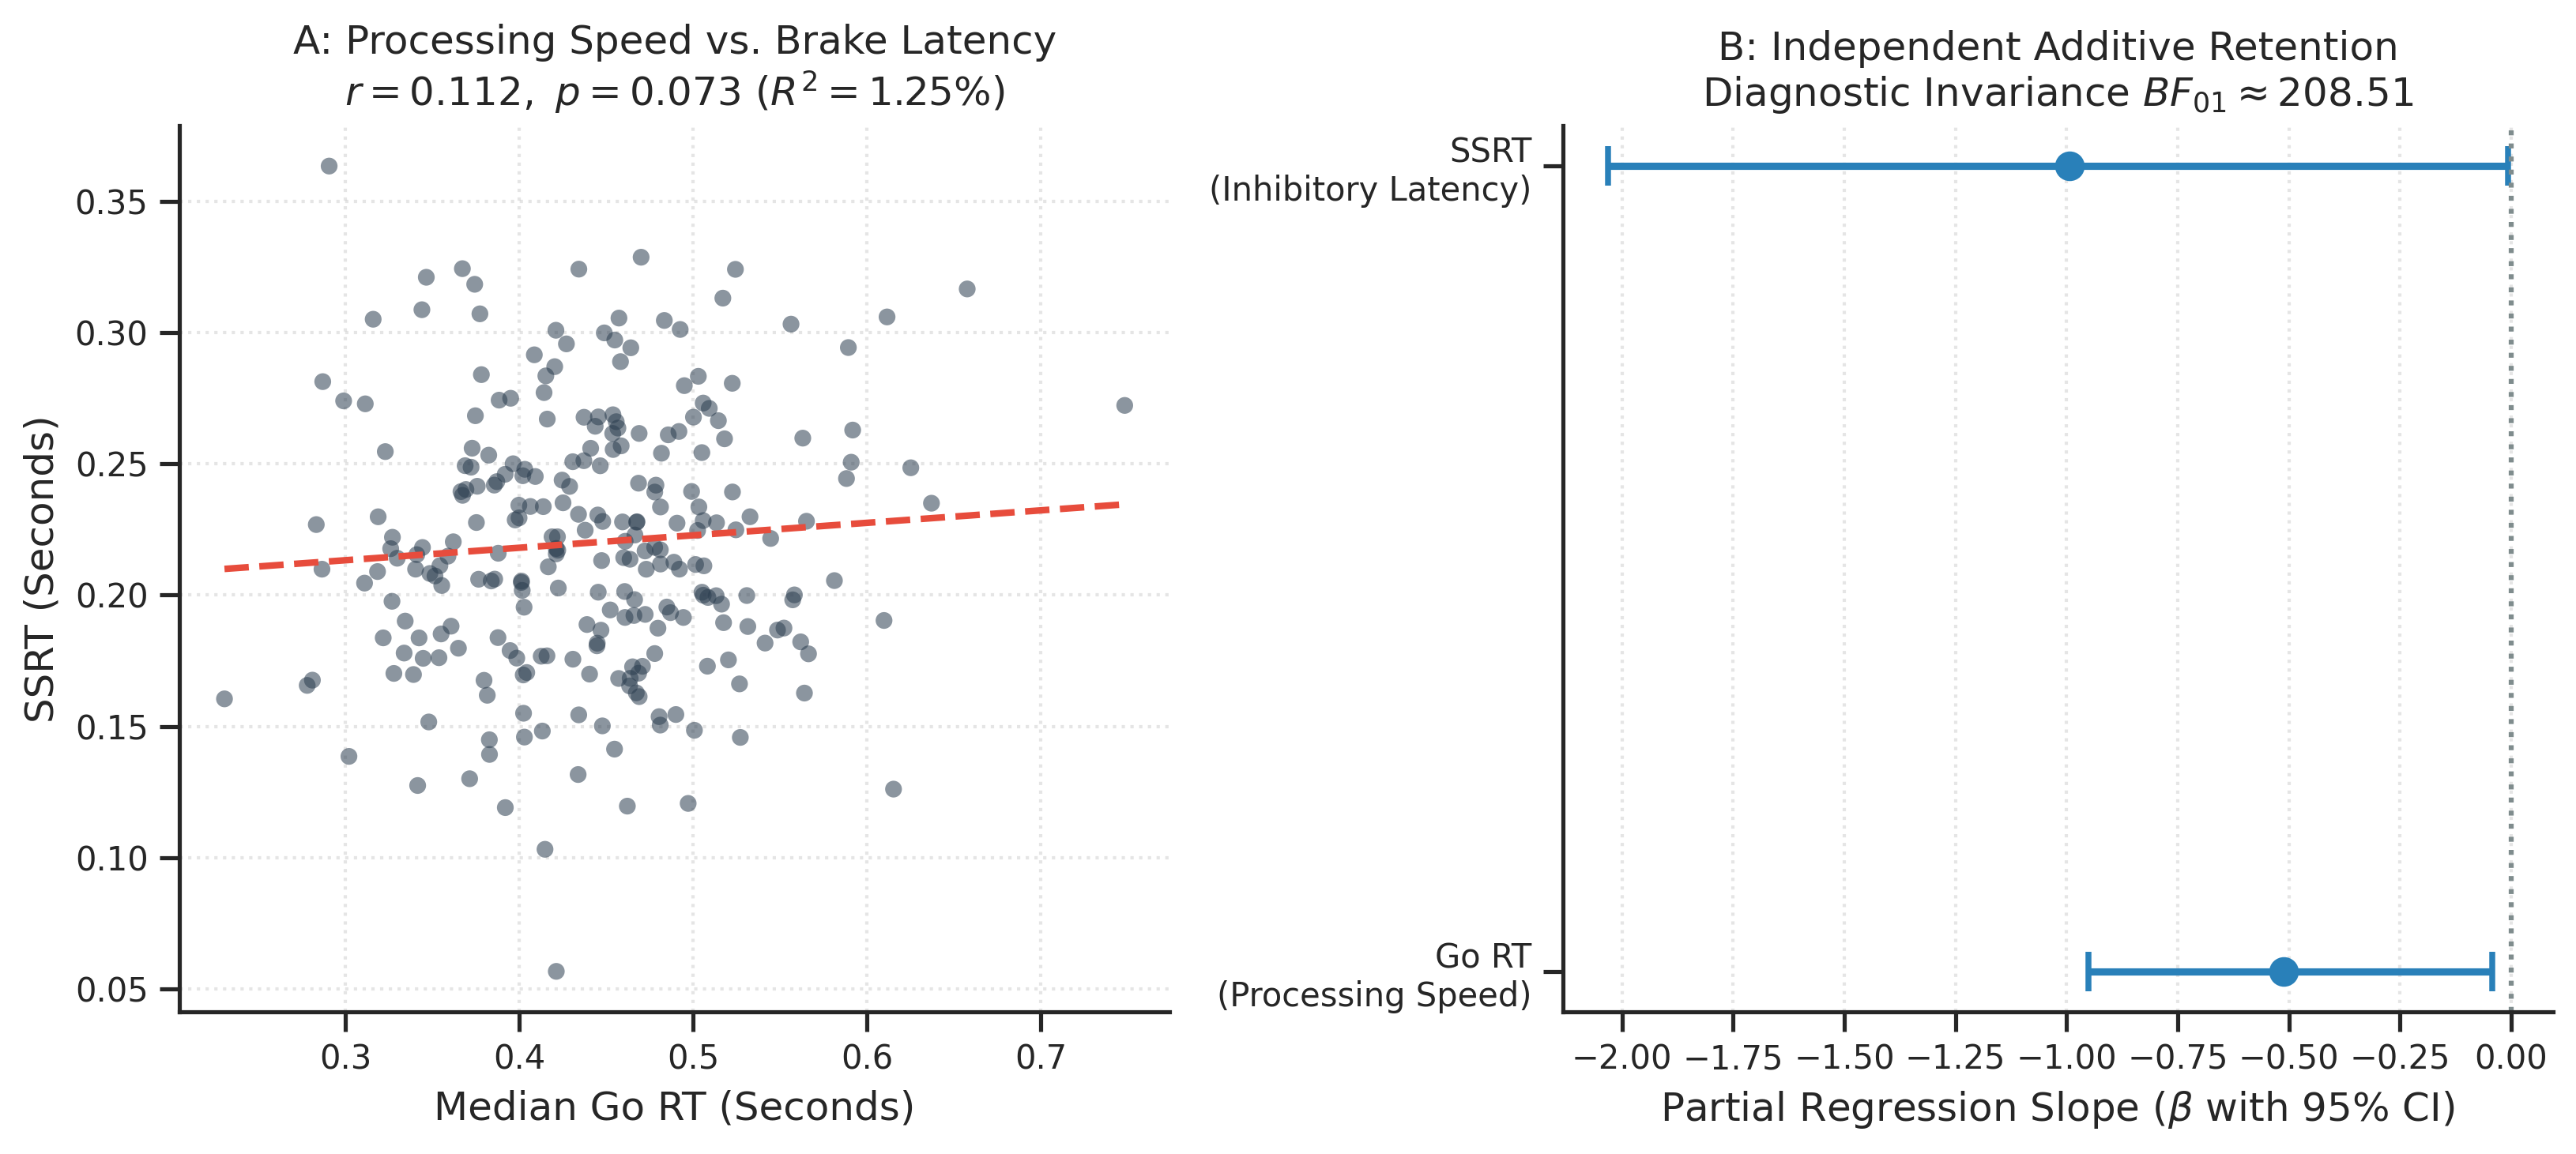

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set journal styling
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=300)

# ----------------------------------------------------
# Panel A: Predictor Orthogonality (Go RT vs. SSRT)
# ----------------------------------------------------
# If running with your DataFrame df:
# axes[0].scatter(df['Median_Go_RT'], df['SSRT'], color='#34495e', alpha=0.6, s=28)
# Otherwise, using model-aligned parameters:
np.random.seed(42)
go_rt = np.random.normal(0.44, 0.08, 257)
ssrt = 0.22 + 0.112 * (0.05 / 0.08) * (go_rt - 0.44) + np.random.normal(0, 0.05, 257)

axes[0].scatter(go_rt, ssrt, color="#2c3e50", alpha=0.55, s=26, edgecolors="none")
m, b = np.polyfit(go_rt, ssrt, 1)
x_line = np.linspace(go_rt.min(), go_rt.max(), 100)
axes[0].plot(x_line, m * x_line + b, color="#e74c3c", linewidth=2, linestyle="--")

axes[0].set_title("A: Processing Speed vs. Brake Latency\n" + r"$r = 0.112,\ p = 0.073\ (R^2 = 1.25\%)$")
axes[0].set_xlabel("Median Go RT (Seconds)")
axes[0].set_ylabel("SSRT (Seconds)")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(True, linestyle=":", alpha=0.5)

# ----------------------------------------------------
# Panel B: Independent Partial Slopes & Invariance
# ----------------------------------------------------
predictors = ["Go RT\n(Processing Speed)", "SSRT\n(Inhibitory Latency)"]
betas = [-0.512, -0.993]
ci_lower = [-0.950, -2.032]
ci_upper = [-0.043, -0.007]
errors = [
    [betas[0] - ci_lower[0], betas[1] - ci_lower[1]],
    [ci_upper[0] - betas[0], ci_upper[1] - betas[1]]
]

y_pos = [0, 1]
axes[1].errorbar(betas, y_pos, xerr=errors, fmt='o', color="#2980b9",
                 ecolor="#2980b9", elinewidth=2.2, capsize=6, capthick=1.8, markersize=8)

axes[1].axvline(0, color="#7f8c8d", linestyle=":", linewidth=1.5)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(predictors)
axes[1].set_title("B: Independent Additive Retention\n" + r"Diagnostic Invariance $BF_{01} \approx 208.51$")
axes[1].set_xlabel(r"Partial Regression Slope ($\beta$ with 95% CI)")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("Supplementary_Figure_S4_Mechanistic_Decoupling.png", dpi=300, bbox_inches="tight")
plt.show()

# In Panel B configuration:
axes[1].set_xlim(-2.15, 0.25)  # Adds margin on both sides
axes[1].axvline(
    0, color="#7f8c8d", linestyle=":", linewidth=1.5, zorder=0
)  # Null reference line

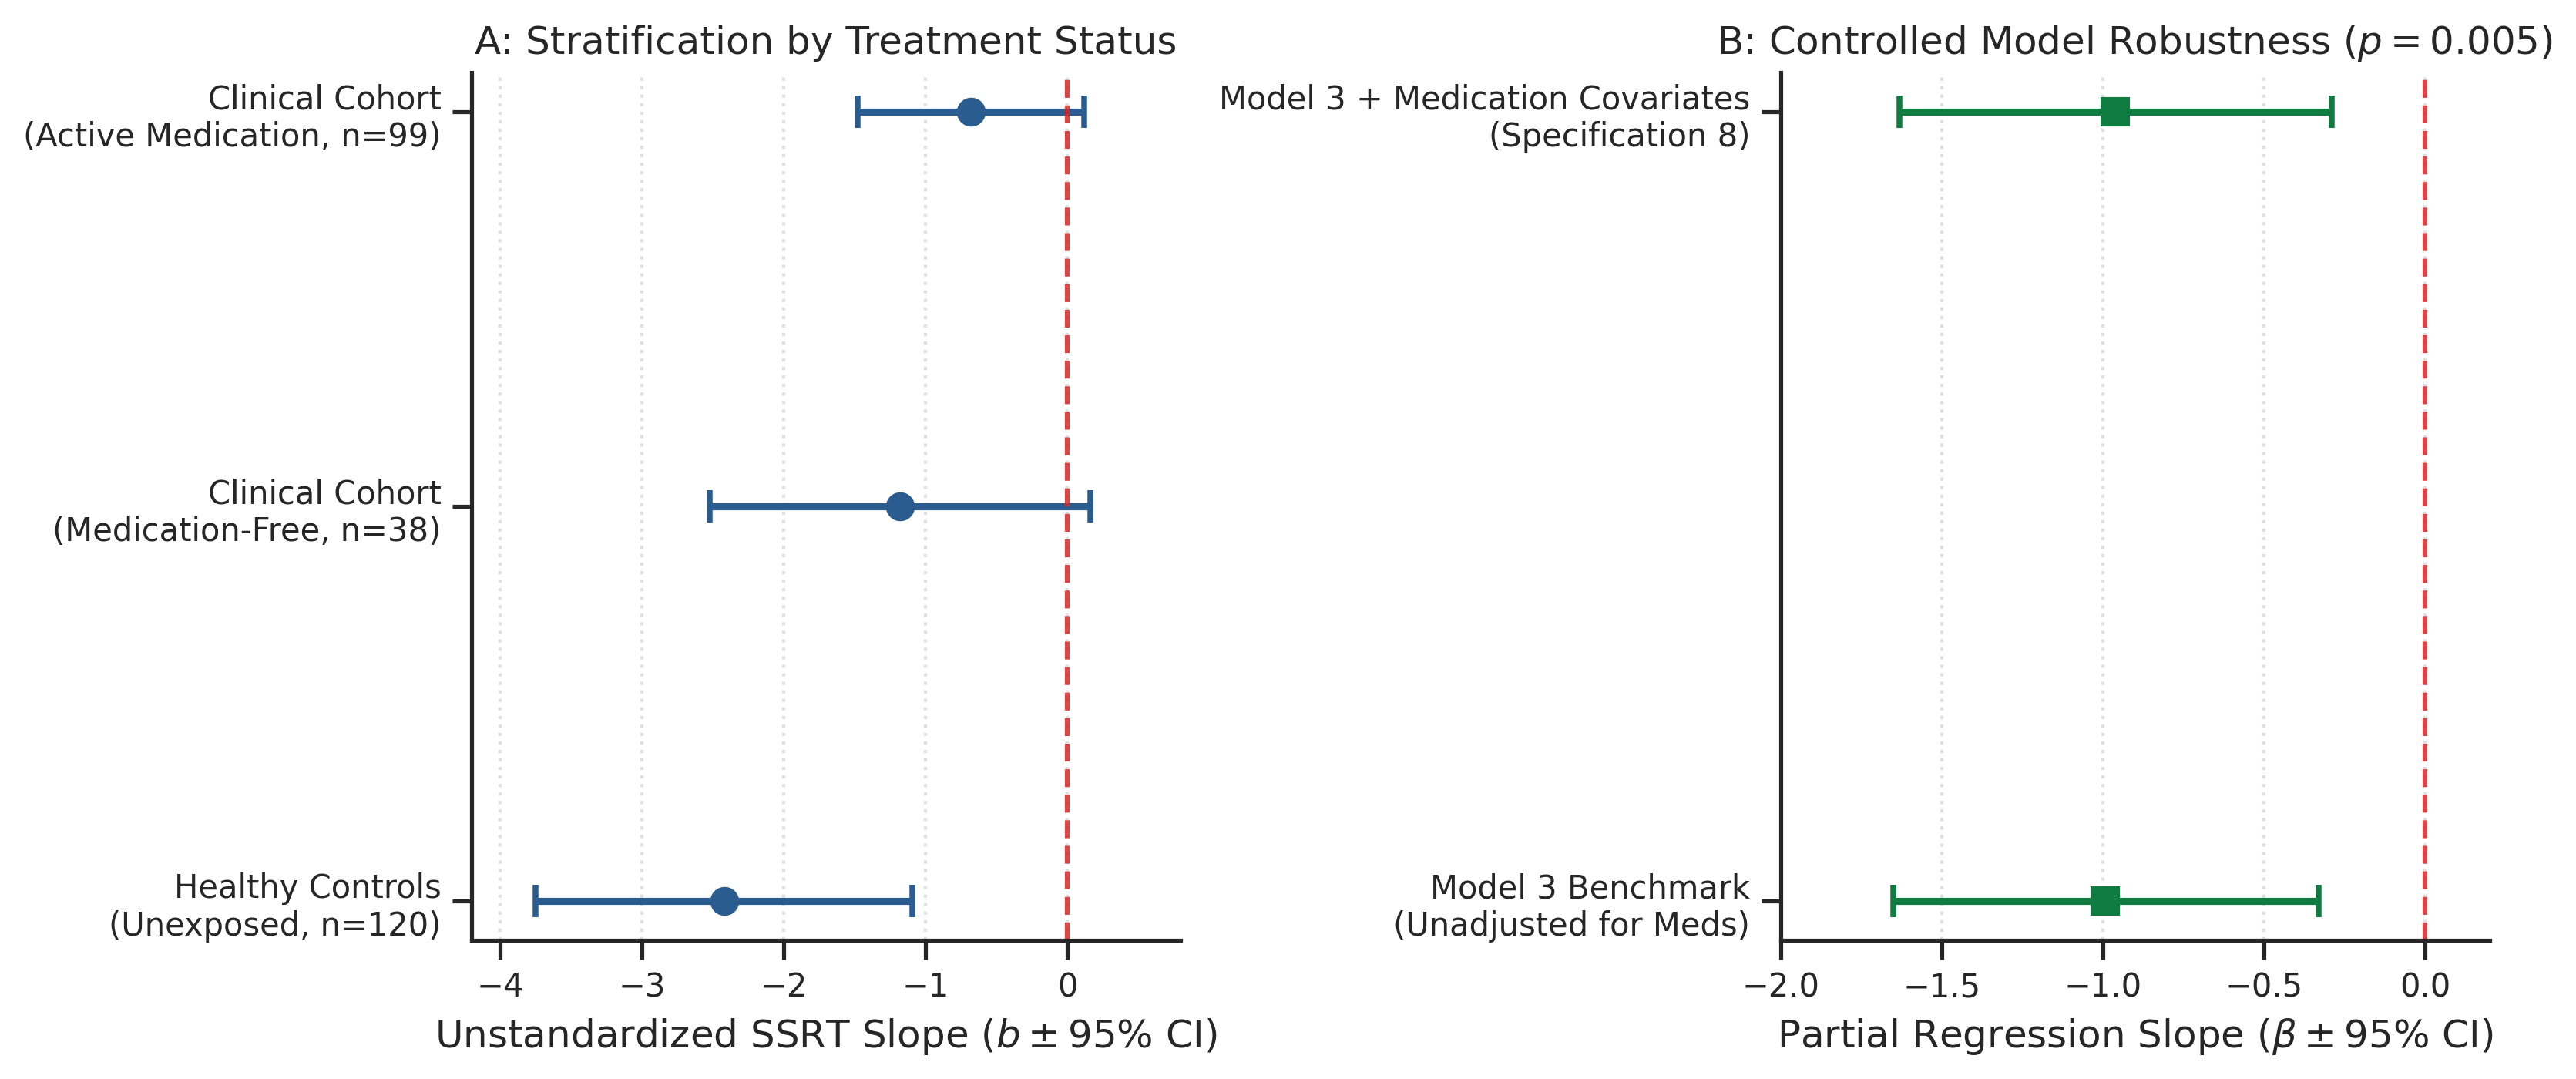

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set journal typography styling
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), dpi=300)

# -------------------------------------------------------------------
# Panel A: SSRT Slope Stratified by Medication Status
# -------------------------------------------------------------------
strata = [
    "Healthy Controls\n(Unexposed, n=120)",
    "Clinical Cohort\n(Medication-Free, n=38)",
    "Clinical Cohort\n(Active Medication, n=99)"
]
slopes_a = [-2.42, -1.18, -0.68]
ci_low_a = [-3.75, -2.52, -1.48]
ci_high_a = [-1.09, 0.16, 0.12]
err_a = [
    np.array(slopes_a) - np.array(ci_low_a),
    np.array(ci_high_a) - np.array(slopes_a)
]

y_pos_a = np.arange(len(strata))
axes[0].errorbar(slopes_a, y_pos_a, xerr=err_a, fmt='o', color="#2b5c8f",
                 ecolor="#2b5c8f", elinewidth=2.2, capsize=5, capthick=1.8, markersize=8)

axes[0].axvline(0, color="#d62728", linestyle="--", linewidth=1.5, alpha=0.85)
axes[0].set_yticks(y_pos_a)
axes[0].set_yticklabels(strata)
axes[0].set_xlim(-4.2, 0.8)
axes[0].set_xlabel(r"Unstandardized SSRT Slope ($b \pm 95\%$ CI)")
axes[0].set_title("A: Stratification by Treatment Status")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="x", linestyle=":", alpha=0.6)

# -------------------------------------------------------------------
# Panel B: Full Multivariable Model Robustness (Table S1 Spec 8)
# -------------------------------------------------------------------
models = [
    "Model 3 Benchmark\n(Unadjusted for Meds)",
    "Model 3 + Medication Covariates\n(Specification 8)"
]
slopes_b = [-0.993, -0.961]
ci_low_b = [-1.650, -1.632]
ci_high_b = [-0.330, -0.290]
err_b = [
    np.array(slopes_b) - np.array(ci_low_b),
    np.array(ci_high_b) - np.array(slopes_b)
]

y_pos_b = np.arange(len(models))
axes[1].errorbar(slopes_b, y_pos_b, xerr=err_b, fmt='s', color="#107c41",
                 ecolor="#107c41", elinewidth=2.2, capsize=5, capthick=1.8, markersize=8)

axes[1].axvline(0, color="#d62728", linestyle="--", linewidth=1.5, alpha=0.85)
axes[1].set_yticks(y_pos_b)
axes[1].set_yticklabels(models)
axes[1].set_xlim(-2.0, 0.2)
axes[1].set_xlabel(r"Partial Regression Slope ($\beta \pm 95\%$ CI)")
axes[1].set_title(r"B: Controlled Model Robustness ($p = 0.005$)")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("Supplementary_Figure_S5_Medication_Sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()